In [1]:
# all imports used
import pandas as pd
import numpy as np
import os
import glob
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.metrics import silhouette_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import OneClassSVM
from sklearn.model_selection import LeaveOneOut
from scipy.spatial.distance import cdist

from sklearn.metrics import (
    silhouette_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    f1_score,
)

print("done")

done


Data Loading and preprocessing

In [2]:
#Loading all the data
folder_paths = [
    r"C:\Users\N1190670\OneDrive - Nottingham Trent University\Care_To_Compare\Wind Farm A\Wind Farm A\datasets",
    r"C:\Users\N1190670\OneDrive - Nottingham Trent University\Care_To_Compare\Wind Farm B\Wind Farm B\datasets",
    r"C:\Users\N1190670\OneDrive - Nottingham Trent University\Care_To_Compare\Wind Farm C\Wind Farm C\datasets"
]

all_data = {}

for folder in folder_paths:
    windfarm_name = os.path.basename(os.path.dirname(folder))  
    all_files = glob.glob(os.path.join(folder, "*.csv"))

    for file in all_files:
        try:
            df = pd.read_csv(file, sep=';', low_memory=False)

            df["source_file"] = os.path.basename(file)
            df["source_folder"] = windfarm_name

            file_name = os.path.splitext(os.path.basename(file))[0]
            key_name = f"{windfarm_name}_{file_name}"

            all_data[key_name] = df


        except Exception as e:
            print(f"Error loading {file}: {e}")

print("\nDone\n")


print("Total datasets loaded:", len(all_data))



Done

Total datasets loaded: 95


In [3]:
#duplicate check
for key, df in all_data.items():
    full_row_duplicates = df.duplicated().sum()
    time_asset_duplicates = df.duplicated(subset=["time_stamp", "asset_id"]).sum()

    if full_row_duplicates > 0 or time_asset_duplicates > 0:
        print(f"\nDataset: {key}")
        print(f"Full row duplicates: {full_row_duplicates}")
        print(f"Duplicate time_stamp + asset_id rows: {time_asset_duplicates}")

print("\nDone")


Done


In [4]:
#date and time conversion
for key, df in all_data.items():
    try:
        df["time_stamp"] = pd.to_datetime(df["time_stamp"], errors="coerce")

        df = df.sort_values("time_stamp").reset_index(drop=True)

        all_data[key] = df

        

    except Exception as e:
        print(f"{key}: error - {e}")

print("Done")

Done


In [5]:
#checking for missing values
total_missing_values = 0

for key, df in all_data.items():
    dataset_missing = df.isnull().sum().sum()
    total_missing_values += dataset_missing

    if dataset_missing > 0:
        print(f"{key}: {dataset_missing} missing values")

print("\nTotal missing values across all datasets:", total_missing_values)
print("Done")

Wind Farm A_0: 2 missing values
Wind Farm A_10: 6 missing values
Wind Farm A_17: 6 missing values
Wind Farm A_22: 2 missing values
Wind Farm A_26: 2 missing values
Wind Farm A_3: 4 missing values
Wind Farm A_40: 4 missing values
Wind Farm A_42: 6 missing values
Wind Farm A_51: 2 missing values
Wind Farm A_69: 2 missing values
Wind Farm A_72: 2 missing values
Wind Farm A_84: 2 missing values
Wind Farm B_19: 1 missing values
Wind Farm B_2: 7 missing values
Wind Farm B_21: 6 missing values
Wind Farm B_23: 1 missing values
Wind Farm B_27: 7 missing values
Wind Farm B_34: 1 missing values
Wind Farm B_52: 1 missing values
Wind Farm B_53: 1 missing values
Wind Farm B_7: 7 missing values
Wind Farm B_74: 1 missing values
Wind Farm B_77: 3 missing values
Wind Farm B_82: 44 missing values
Wind Farm B_83: 1 missing values
Wind Farm B_86: 4 missing values
Wind Farm B_87: 7 missing values
Wind Farm C_36: 175684 missing values

Total missing values across all datasets: 175816
Done


In [6]:
#assesing missing values
for key, df in all_data.items():
    missing_count = df.isnull().sum()
    missing_count = missing_count[missing_count > 0]

    if not missing_count.empty:
        missing_percent = (missing_count / len(df)) * 100

        missing_summary = pd.DataFrame({
            "Missing Count": missing_count,
            "Missing Percent": missing_percent
        }).sort_values(by="Missing Count", ascending=False)

        print(f"\nDataset: {key}")
        print(missing_summary)

print("\nDone")


Dataset: Wind Farm A_0
               Missing Count  Missing Percent
sensor_14_avg              1         0.001819
sensor_22_avg              1         0.001819

Dataset: Wind Farm A_10
               Missing Count  Missing Percent
sensor_14_avg              3         0.005598
sensor_22_avg              3         0.005598

Dataset: Wind Farm A_17
               Missing Count  Missing Percent
sensor_14_avg              3         0.005446
sensor_22_avg              3         0.005446

Dataset: Wind Farm A_22
               Missing Count  Missing Percent
sensor_14_avg              1         0.001886
sensor_22_avg              1         0.001886

Dataset: Wind Farm A_26
               Missing Count  Missing Percent
sensor_14_avg              1         0.001862
sensor_22_avg              1         0.001862

Dataset: Wind Farm A_3
               Missing Count  Missing Percent
sensor_14_avg              2         0.003604
sensor_22_avg              2         0.003604

Dataset: Wind Farm A_40

In [7]:
#major missing coloumns and rows
column_threshold = 10
row_threshold = 10

summary = []

for key, df in all_data.items():
    col_missing_percent = (df.isnull().sum() / len(df)) * 100
    major_missing_cols = col_missing_percent[col_missing_percent >= column_threshold]

    row_missing_percent = (df.isnull().sum(axis=1) / df.shape[1]) * 100
    major_missing_rows = row_missing_percent[row_missing_percent >= row_threshold]

    if not major_missing_cols.empty or not major_missing_rows.empty:
        summary.append({
            "Dataset": key,
            "Major Missing Columns": len(major_missing_cols),
            "Major Missing Rows": len(major_missing_rows),
            "Worst Column %": col_missing_percent.max(),
            "Worst Row %": row_missing_percent.max()
        })

summary_df = pd.DataFrame(summary)
print(summary_df)

          Dataset  Major Missing Columns  Major Missing Rows  Worst Column %  \
0  Wind Farm C_36                      0                 288        0.779108   

   Worst Row %  
0    86.757039  


In [8]:
#over 10% removed
row_threshold = 10

for key, df in all_data.items():
    row_missing_percent = (df.isnull().sum(axis=1) / df.shape[1]) * 100
    bad_rows = row_missing_percent > row_threshold

    removed_count = bad_rows.sum()

    if removed_count > 0:
        all_data[key] = df.loc[~bad_rows].reset_index(drop=True)
        print(f"{key}: removed {removed_count} rows with more than {row_threshold}% missing values")

print("Done")

Wind Farm C_36: removed 288 rows with more than 10% missing values
Done


In [9]:
#rebuild average data
avg_data = {}

for key, df in all_data.items():
    avg_columns = [col for col in df.columns if col.endswith("_avg")]
    
    keep_columns = ["time_stamp", "asset_id", "status_type_id", "source_file", "source_folder"]
    keep_columns = [col for col in keep_columns if col in df.columns]

    selected_columns = keep_columns + avg_columns
    avg_data[key] = df[selected_columns].copy()

print("Done")

Done


EDA

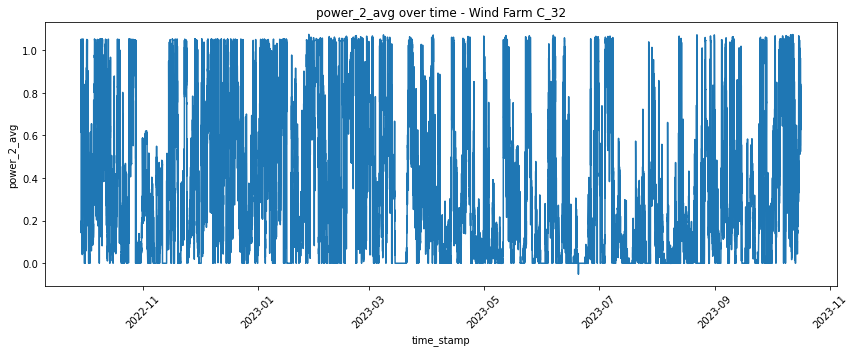

In [10]:
#farm C time series data
test_key = "Wind Farm C_32"

plt.figure(figsize=(12, 5))
plt.plot(avg_data[test_key]["time_stamp"], avg_data[test_key]["power_2_avg"])
plt.title(f"power_2_avg over time - {test_key}")
plt.xlabel("time_stamp")
plt.ylabel("power_2_avg")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

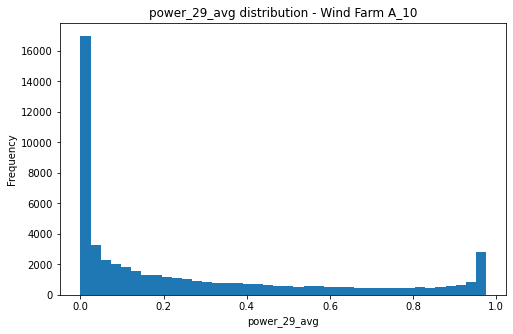

In [11]:
#Farm A power distribution
test_key = "Wind Farm A_10"
power_col = "power_29_avg"   

plt.figure(figsize=(8, 5))
plt.hist(avg_data[test_key][power_col].dropna(), bins=40)
plt.title(f"{power_col} distribution - {test_key}")
plt.xlabel(power_col)
plt.ylabel("Frequency")
plt.show()

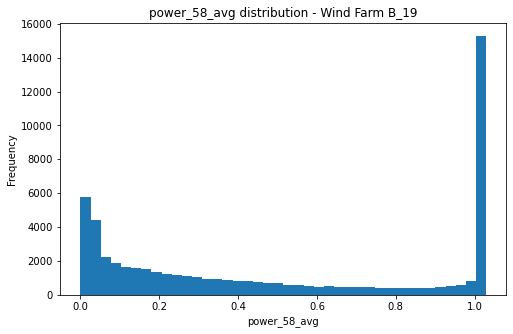

In [12]:
#Farm b power distribution
test_key = "Wind Farm B_19"
power_col = "power_58_avg"   

plt.figure(figsize=(8, 5))
plt.hist(avg_data[test_key][power_col].dropna(), bins=40)
plt.title(f"{power_col} distribution - {test_key}")
plt.xlabel(power_col)
plt.ylabel("Frequency")
plt.show()

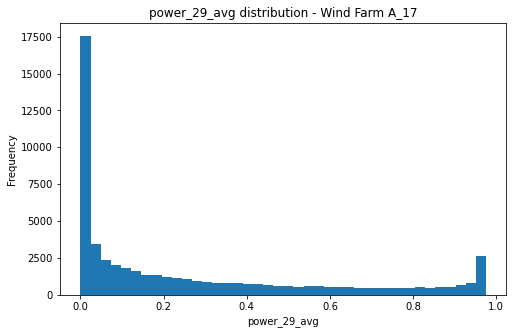

In [13]:
#power 2 farm a distribution
test_key = "Wind Farm A_17"
power_col = "power_29_avg"   

plt.figure(figsize=(8, 5))
plt.hist(avg_data[test_key][power_col].dropna(), bins=40)
plt.title(f"{power_col} distribution - {test_key}")
plt.xlabel(power_col)
plt.ylabel("Frequency")
plt.show()

In [14]:
#build the per farm database

farm_configs = {
    "Wind Farm A": {"power_col": "power_29_avg", "wind_col": "wind_speed_3_avg"},
    "Wind Farm B": {"power_col": "power_58_avg", "wind_col": "wind_speed_59_avg"},
    "Wind Farm C": {"power_col": "power_2_avg", "wind_col": "wind_speed_236_avg"}
}

farm_data = {}

for farm_name, cols in farm_configs.items():
    farm_frames = []

    for key, df in avg_data.items():
        if key.startswith(farm_name):
            temp = df[["time_stamp", "asset_id", "status_type_id", cols["power_col"], cols["wind_col"]]].copy()
            temp = temp.rename(columns={
                cols["power_col"]: "power_avg",
                cols["wind_col"]: "wind_speed_avg"
            })
            temp["farm"] = farm_name
            temp["source_turbine"] = key
            farm_frames.append(temp)

    farm_data[farm_name] = pd.concat(farm_frames, ignore_index=True)

print("Done")

Done


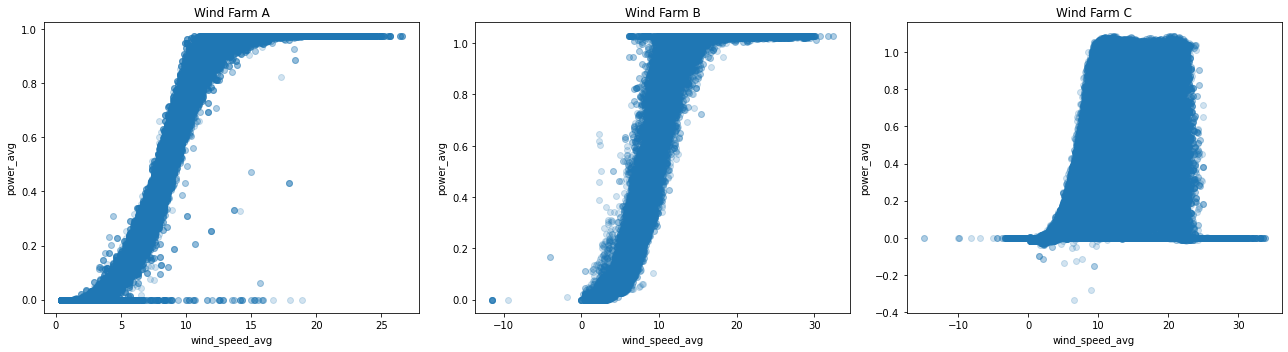

In [15]:
#power distribution across the three farms

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, farm_name in zip(axes, ["Wind Farm A", "Wind Farm B", "Wind Farm C"]):
    df = farm_data[farm_name]

    ax.scatter(df["wind_speed_avg"], df["power_avg"], alpha=0.2)
    ax.set_title(farm_name)
    ax.set_xlabel("wind_speed_avg")
    ax.set_ylabel("power_avg")

plt.tight_layout()
plt.show()

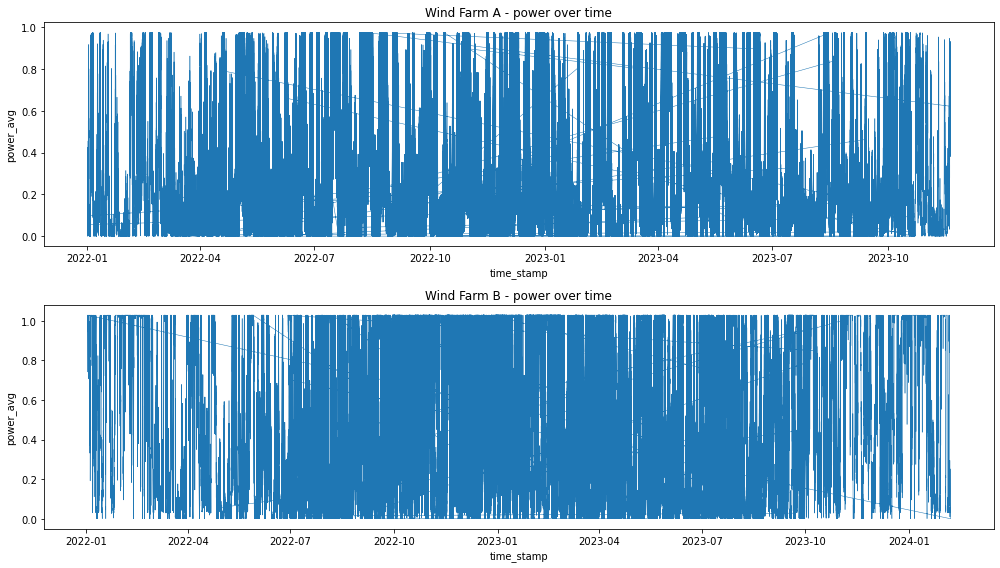

In [16]:
#Farm a and B over time

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)

for ax, farm_name in zip(axes, ["Wind Farm A", "Wind Farm B"]):
    df = farm_data[farm_name]

    ax.plot(df["time_stamp"], df["power_avg"], linewidth=0.5)
    ax.set_title(f"{farm_name} - power over time")
    ax.set_xlabel("time_stamp")
    ax.set_ylabel("power_avg")

plt.tight_layout()
plt.show()

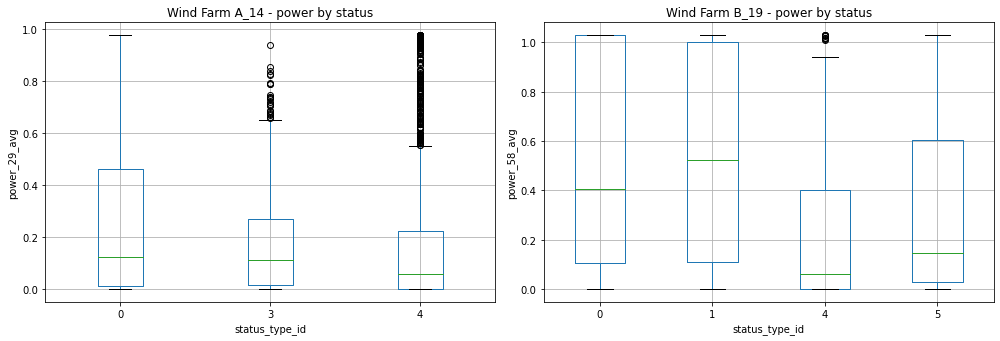

In [17]:
#power by status type Farm A and b
plot_configs = [
    ("Wind Farm A_14", "power_29_avg"),
    ("Wind Farm B_19", "power_58_avg")
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (test_key, power_col) in zip(axes, plot_configs):
    df = avg_data[test_key]
    df.boxplot(column=power_col, by="status_type_id", ax=ax)
    ax.set_title(f"{test_key} - power by status")
    ax.set_xlabel("status_type_id")
    ax.set_ylabel(power_col)

plt.suptitle("")
plt.tight_layout()
plt.show()

In [18]:
#Farm A rebuilt with all sensors

farm_a_columns = [
    'time_stamp', 'asset_id', 'status_type_id', 'source_file', 'source_folder',
    'sensor_0_avg', 'sensor_1_avg', 'sensor_2_avg',
    'wind_speed_3_avg', 'wind_speed_4_avg',
    'sensor_5_avg', 'sensor_6_avg', 'sensor_7_avg', 'sensor_8_avg', 'sensor_9_avg',
    'sensor_10_avg', 'sensor_11_avg', 'sensor_12_avg', 'sensor_13_avg', 'sensor_14_avg',
    'sensor_15_avg', 'sensor_16_avg', 'sensor_17_avg', 'sensor_18_avg', 'sensor_19_avg',
    'sensor_20_avg', 'sensor_21_avg', 'sensor_22_avg', 'sensor_23_avg', 'sensor_24_avg',
    'sensor_25_avg', 'sensor_26_avg',
    'reactive_power_27_avg', 'reactive_power_28_avg',
    'power_29_avg', 'power_30_avg',
    'sensor_31_avg', 'sensor_32_avg', 'sensor_33_avg', 'sensor_34_avg', 'sensor_35_avg',
    'sensor_36_avg', 'sensor_37_avg', 'sensor_38_avg', 'sensor_39_avg', 'sensor_40_avg',
    'sensor_41_avg', 'sensor_42_avg', 'sensor_43_avg', 'sensor_52_avg', 'sensor_53_avg'
]

farm_a_frames = []

for key, df in avg_data.items():
    if key.startswith("Wind Farm A"):
        temp = df[farm_a_columns].copy()
        temp["farm"] = "Wind Farm A"
        temp["source_turbine"] = key
        farm_a_frames.append(temp)

farm_data["Wind Farm A"] = pd.concat(farm_a_frames, ignore_index=True)


print(farm_data["Wind Farm A"].shape)

(1196747, 53)


In [19]:
#farm B rebuilt with all sensors
farm_b_columns = [
    'time_stamp', 'asset_id', 'status_type_id', 'source_file', 'source_folder',
    'sensor_0_avg', 'sensor_1_avg', 'sensor_2_avg', 'sensor_3_avg', 'sensor_4_avg',
    'sensor_5_avg', 'sensor_6_avg', 'sensor_7_avg', 'sensor_8_avg', 'sensor_9_avg',
    'sensor_10_avg', 'reactive_power_11_avg', 'sensor_12_avg', 'sensor_13_avg',
    'sensor_14_avg', 'sensor_15_avg', 'sensor_16_avg', 'sensor_17_avg',
    'sensor_18_avg', 'sensor_19_avg', 'sensor_20_avg', 'sensor_21_avg',
    'sensor_22_avg', 'sensor_23_avg', 'sensor_24_avg', 'sensor_25_avg',
    'sensor_26_avg', 'sensor_27_avg', 'sensor_28_avg', 'sensor_29_avg',
    'sensor_30_avg', 'sensor_31_avg', 'sensor_32_avg', 'sensor_33_avg',
    'sensor_34_avg', 'sensor_35_avg', 'sensor_36_avg', 'sensor_37_avg',
    'sensor_38_avg', 'sensor_39_avg', 'sensor_40_avg', 'sensor_41_avg',
    'sensor_42_avg', 'sensor_43_avg', 'sensor_44_avg', 'sensor_45_avg',
    'sensor_46_avg', 'sensor_47_avg', 'sensor_48_avg', 'sensor_49_avg',
    'sensor_50_avg', 'sensor_51_avg', 'sensor_52_avg', 'sensor_53_avg',
    'sensor_54_avg', 'sensor_55_avg', 'sensor_56_avg', 'sensor_57_avg',
    'power_58_avg', 'wind_speed_59_avg', 'wind_speed_60_avg', 'wind_speed_61_avg',
    'power_62_avg'
]

farm_b_frames = []

for key, df in avg_data.items():
    if key.startswith("Wind Farm B"):
        temp = df[farm_b_columns].copy()
        temp["farm"] = "Wind Farm B"
        temp["source_turbine"] = key
        farm_b_frames.append(temp)

farm_data["Wind Farm B"] = pd.concat(farm_b_frames, ignore_index=True)


print(farm_data["Wind Farm B"].shape)

(859065, 70)


In [20]:
#negative wind speed rows removed from b
df = farm_data["Wind Farm B"].copy()

wind_cols = [col for col in df.columns if col.startswith("wind_speed_")]

before_shape = df.shape

for col in wind_cols:
    df = df[df[col] >= 0]

after_shape = df.shape

print("Before:", before_shape)
print("After:", after_shape)
print("Rows removed:", before_shape[0] - after_shape[0])

farm_data["Wind Farm B"] = df

Before: (859065, 70)
After: (859041, 70)
Rows removed: 24


In [21]:
#Negative temps removed from B
df = farm_data["Wind Farm B"].copy()

for col in ["sensor_12_avg", "sensor_57_avg"]:
    df.loc[df[col] < 0, col] = pd.NA

before_shape = df.shape
df = df.dropna(subset=["sensor_12_avg", "sensor_57_avg"])
after_shape = df.shape

print("Before:", before_shape)
print("After:", after_shape)
print("Rows removed:", before_shape[0] - after_shape[0])

farm_data["Wind Farm B"] = df

Before: (859041, 70)
After: (779255, 70)
Rows removed: 79786


Reactive columns: ['reactive_power_27_avg', 'reactive_power_28_avg']
Power columns: ['reactive_power_27_avg', 'reactive_power_28_avg', 'power_29_avg', 'power_30_avg']


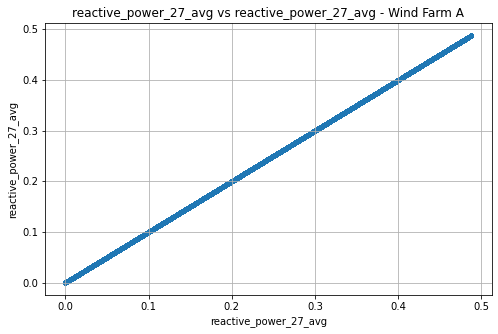

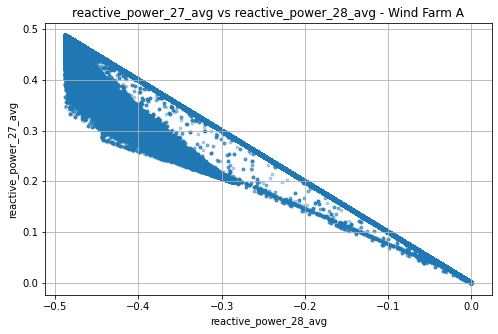

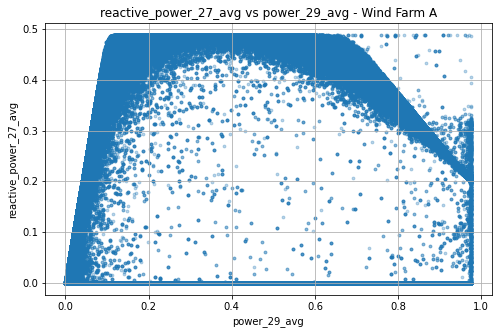

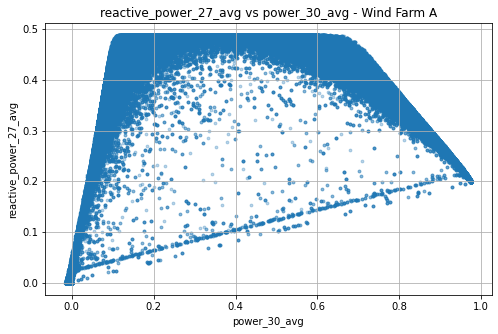

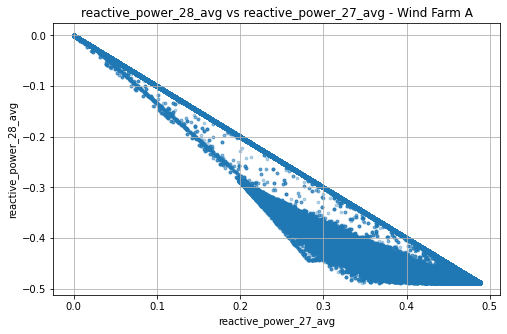

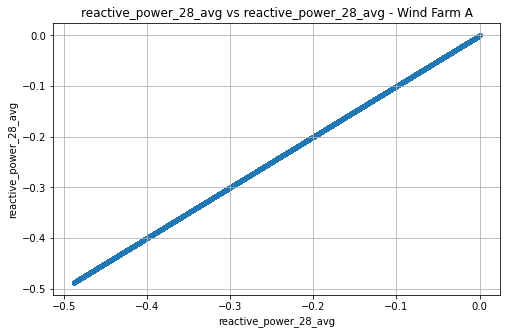

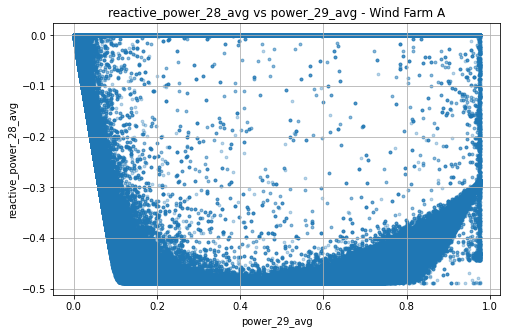

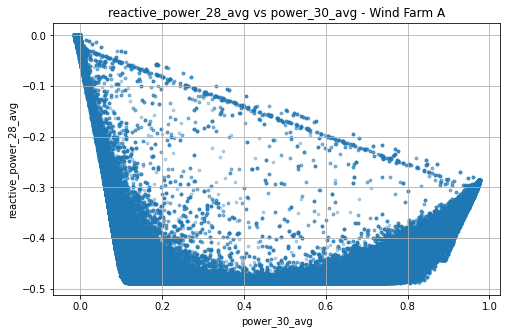

In [22]:
#farm a reactive vs active power

df = farm_data["Wind Farm A"].copy()

reactive_cols = [col for col in df.columns if "reactive_power" in col]
power_cols = [col for col in df.columns if "power_" in col]

print("Reactive columns:", reactive_cols)
print("Power columns:", power_cols)

for reactive_col in reactive_cols:
    for power_col in power_cols:
        temp = df[[power_col, reactive_col]].dropna()

        plt.figure(figsize=(8, 5))
        plt.scatter(temp[power_col], temp[reactive_col], alpha=0.3, s=8)
        plt.xlabel(power_col)
        plt.ylabel(reactive_col)
        plt.title(f"{reactive_col} vs {power_col} - Wind Farm A")
        plt.grid(True)
        plt.show()

In [23]:
#power by status
summary = (
    farm_data["Wind Farm A"]
    .groupby("status_type_id")[["power_29_avg", "power_30_avg", "reactive_power_27_avg", "reactive_power_28_avg"]]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

print(summary)

               power_29_avg                                              \
                      count      mean    median       std  min      max   
status_type_id                                                            
0                   1053736  0.286048  0.130000  0.331697  0.0  0.97561   
3                     23689  0.407230  0.301171  0.373252  0.0  0.97561   
4                    119322  0.283830  0.107146  0.348391  0.0  0.97561   

               power_30_avg                                ...  \
                      count      mean    median       std  ...   
status_type_id                                             ...   
0                   1053736  0.274345  0.119122  0.330667  ...   
3                     23689  0.264687  0.054341  0.352071  ...   
4                    119322  0.255918  0.078829  0.342909  ...   

               reactive_power_27_avg                           \
                              median       std  min       max   
status_type_id        

In [24]:
#Farm A event labels
event_info_a = pd.read_csv(
    r"C:\Users\N1190670\OneDrive - Nottingham Trent University\Care_To_Compare\Wind Farm A\Wind Farm A\event_info.csv",
    sep=";"
)

event_info_a["source_file"] = event_info_a["event_id"].astype(str) + ".csv"

merged = farm_data["Wind Farm A"].copy()

merged = merged.merge(
    event_info_a[["source_file", "event_label", "event_description"]],
    on="source_file",
    how="left"
)

print(merged["event_label"].value_counts(dropna=False))
print(merged.groupby("source_file")["event_label"].nunique().value_counts())
print(merged[["source_file", "event_label"]].drop_duplicates().sort_values("source_file"))

anomaly    649789
normal     546958
Name: event_label, dtype: int64
1    22
Name: event_label, dtype: int64
        source_file event_label
0             0.csv     anomaly
54986        10.csv     anomaly
108578       13.csv      normal
162588       14.csv      normal
216785       17.csv      normal
271875       22.csv     anomaly
324911       24.csv      normal
379914       25.csv      normal
434626       26.csv     anomaly
488328        3.csv      normal
543815       38.csv      normal
598650       40.csv     anomaly
654808       42.csv     anomaly
708694       45.csv     anomaly
762433       51.csv     anomaly
816869       68.csv     anomaly
871227       69.csv      normal
926040       71.csv      normal
980784       72.csv     anomaly
1034866      73.csv     anomaly
1088908      84.csv     anomaly
1142680      92.csv      normal


In [25]:
#farm B event labels
event_info_b = pd.read_csv(
    r"C:\Users\N1190670\OneDrive - Nottingham Trent University\Care_To_Compare\Wind Farm B\Wind Farm B\event_info.csv",
    sep=";"
)

event_info_b["source_file"] = event_info_b["event_id"].astype(str) + ".csv"

merged_b = farm_data["Wind Farm B"].copy()
merged_b = merged_b.merge(
    event_info_b[["source_file", "event_label", "event_description"]],
    on="source_file",
    how="left"
)

print(merged_b["event_label"].value_counts(dropna=False))
print(merged_b.groupby("source_file")["event_label"].nunique().value_counts())
print(merged_b[["source_file", "event_label"]].drop_duplicates().sort_values("source_file"))

normal     456575
anomaly    322680
Name: event_label, dtype: int64
1    15
Name: event_label, dtype: int64
       source_file event_label
0           19.csv     anomaly
52156        2.csv      normal
102217      21.csv      normal
144991      23.csv      normal
195473      27.csv     anomaly
252598      34.csv     anomaly
301766      52.csv      normal
350068      53.csv     anomaly
404608       7.csv     anomaly
457213      74.csv      normal
509197      77.csv     anomaly
566283      82.csv      normal
617029      83.csv      normal
677406      86.csv      normal
728555      87.csv      normal


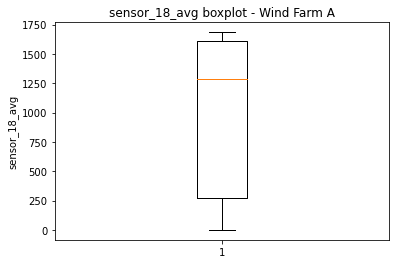

In [26]:
#Farm A sensor 18 box plot
plt.figure(figsize=(6, 4))
plt.boxplot(merged["sensor_18_avg"].dropna(), vert=True)
plt.title("sensor_18_avg boxplot - Wind Farm A")
plt.ylabel("sensor_18_avg")
plt.show()

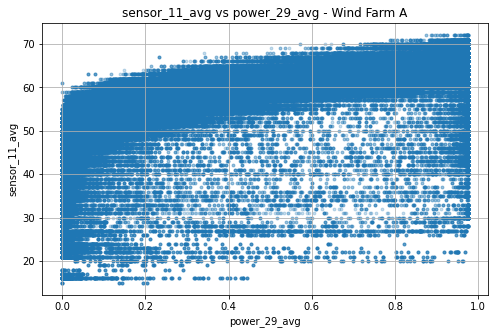

In [27]:
#farm a sensor 11 vs power
temp = merged[["power_29_avg", "sensor_11_avg"]].dropna()

plt.figure(figsize=(8, 5))
plt.scatter(temp["power_29_avg"], temp["sensor_11_avg"], alpha=0.25, s=8)
plt.xlabel("power_29_avg")
plt.ylabel("sensor_11_avg")
plt.title("sensor_11_avg vs power_29_avg - Wind Farm A")
plt.grid(True)
plt.show()

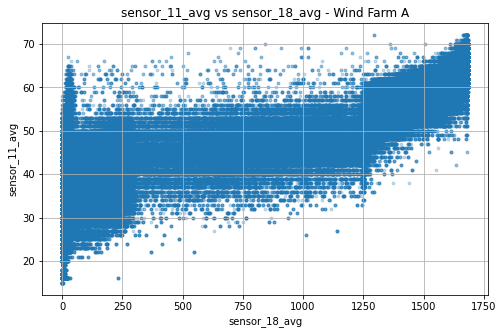

In [28]:
#sensor 18 vs 11 Farm A
temp = merged[["sensor_18_avg", "sensor_11_avg"]].dropna()

plt.figure(figsize=(8, 5))
plt.scatter(temp["sensor_18_avg"], temp["sensor_11_avg"], alpha=0.25, s=8)
plt.xlabel("sensor_18_avg")
plt.ylabel("sensor_11_avg")
plt.title("sensor_11_avg vs sensor_18_avg - Wind Farm A")
plt.grid(True)
plt.show()

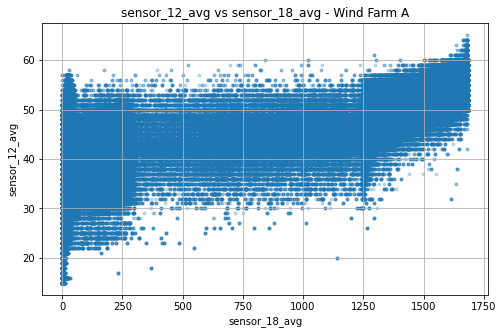

In [29]:
#sensor 12 vs 18 A
temp = merged[["sensor_18_avg", "sensor_12_avg"]].dropna()

plt.figure(figsize=(8, 5))
plt.scatter(temp["sensor_18_avg"], temp["sensor_12_avg"], alpha=0.25, s=8)
plt.xlabel("sensor_18_avg")
plt.ylabel("sensor_12_avg")
plt.title("sensor_12_avg vs sensor_18_avg - Wind Farm A")
plt.grid(True)
plt.show()

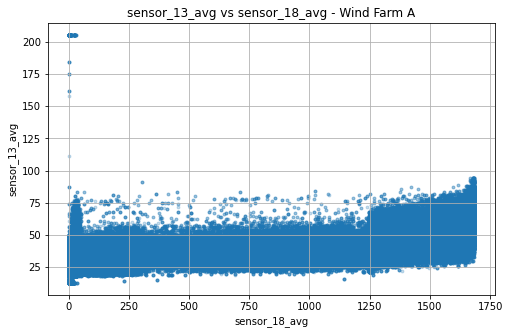

In [30]:
#18 vs 13 A
temp = merged[["sensor_18_avg", "sensor_13_avg"]].dropna()

plt.figure(figsize=(8, 5))
plt.scatter(temp["sensor_18_avg"], temp["sensor_13_avg"], alpha=0.25, s=8)
plt.xlabel("sensor_18_avg")
plt.ylabel("sensor_13_avg")
plt.title("sensor_13_avg vs sensor_18_avg - Wind Farm A")
plt.grid(True)
plt.show()

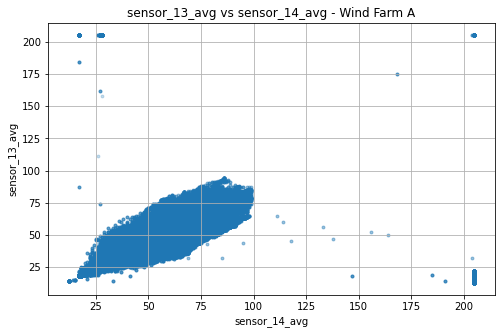

In [31]:
#13 vs 14 A

temp = merged[["sensor_14_avg", "sensor_13_avg"]].dropna()

plt.figure(figsize=(8, 5))
plt.scatter(temp["sensor_14_avg"], temp["sensor_13_avg"], alpha=0.25, s=8)
plt.xlabel("sensor_14_avg")
plt.ylabel("sensor_13_avg")
plt.title("sensor_13_avg vs sensor_14_avg - Wind Farm A")
plt.grid(True)
plt.show()

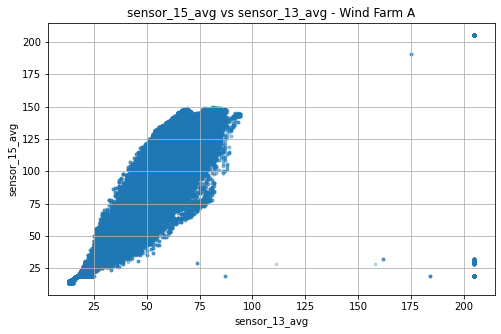

In [32]:
#15 vs 13 A
temp = merged[["sensor_13_avg", "sensor_15_avg"]].dropna()

plt.figure(figsize=(8, 5))
plt.scatter(temp["sensor_13_avg"], temp["sensor_15_avg"], alpha=0.25, s=8)
plt.xlabel("sensor_13_avg")
plt.ylabel("sensor_15_avg")
plt.title("sensor_15_avg vs sensor_13_avg - Wind Farm A")
plt.grid(True)
plt.show()

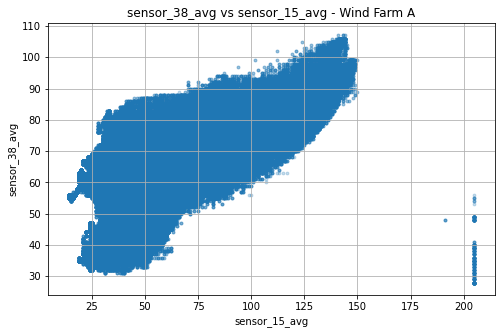

In [33]:
#15 vs 38 A
temp = merged[["sensor_15_avg", "sensor_38_avg"]].dropna()

plt.figure(figsize=(8, 5))
plt.scatter(temp["sensor_15_avg"], temp["sensor_38_avg"], alpha=0.25, s=8)
plt.xlabel("sensor_15_avg")
plt.ylabel("sensor_38_avg")
plt.title("sensor_38_avg vs sensor_15_avg - Wind Farm A")
plt.grid(True)
plt.show()

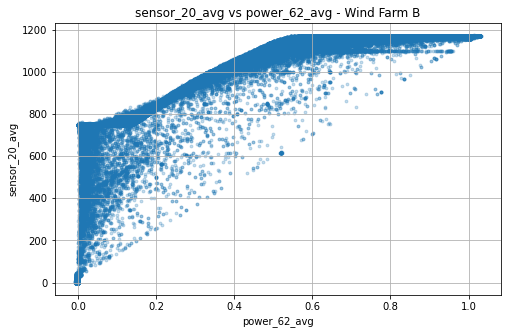

In [34]:
#power 62 vs 20 B
temp = merged_b[["power_62_avg", "sensor_20_avg"]].dropna()

plt.figure(figsize=(8, 5))
plt.scatter(temp["power_62_avg"], temp["sensor_20_avg"], alpha=0.25, s=8)
plt.xlabel("power_62_avg")
plt.ylabel("sensor_20_avg")
plt.title("sensor_20_avg vs power_62_avg - Wind Farm B")
plt.grid(True)
plt.show()

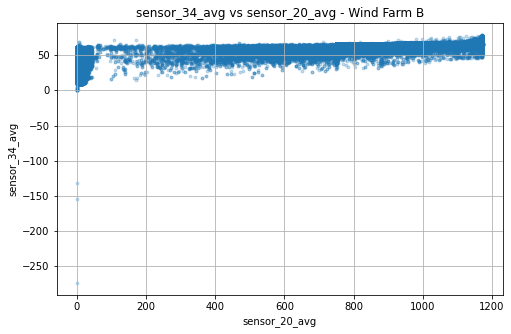

In [35]:
#34 vs 20 B
temp = merged_b[["sensor_20_avg", "sensor_34_avg"]].dropna()

plt.figure(figsize=(8, 5))
plt.scatter(temp["sensor_20_avg"], temp["sensor_34_avg"], alpha=0.25, s=8)
plt.xlabel("sensor_20_avg")
plt.ylabel("sensor_34_avg")
plt.title("sensor_34_avg vs sensor_20_avg - Wind Farm B")
plt.grid(True)
plt.show()

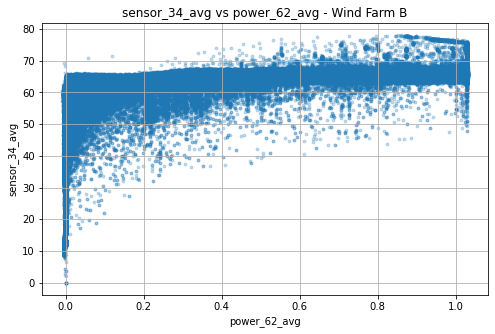

In [36]:
#power 62 vs 34 B

temp = merged_b[["power_62_avg", "sensor_34_avg"]].dropna()

temp = temp[temp["sensor_34_avg"] >= 0]

plt.figure(figsize=(8, 5))
plt.scatter(temp["power_62_avg"], temp["sensor_34_avg"], alpha=0.25, s=8)
plt.xlabel("power_62_avg")
plt.ylabel("sensor_34_avg")
plt.title("sensor_34_avg vs power_62_avg - Wind Farm B")
plt.grid(True)
plt.show()

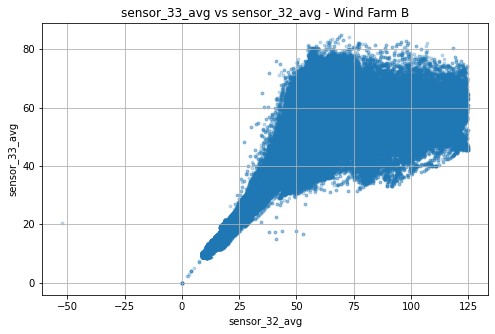

In [37]:
#32 vs 33 B
temp = merged_b[["sensor_32_avg", "sensor_33_avg"]].dropna()

plt.figure(figsize=(8, 5))
plt.scatter(temp["sensor_32_avg"], temp["sensor_33_avg"], alpha=0.25, s=8)
plt.xlabel("sensor_32_avg")
plt.ylabel("sensor_33_avg")
plt.title("sensor_33_avg vs sensor_32_avg - Wind Farm B")
plt.grid(True)
plt.show()

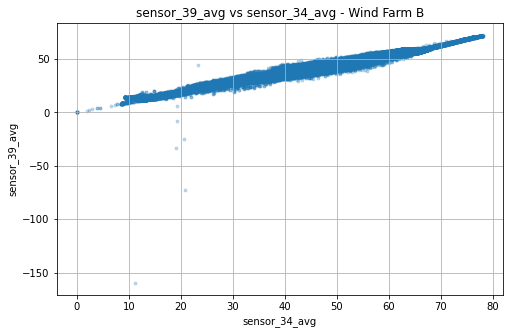

In [38]:
#34 vs 39 b
temp = merged_b[["sensor_34_avg", "sensor_39_avg"]].dropna()

temp = temp[temp["sensor_34_avg"] >= 0]

plt.figure(figsize=(8, 5))
plt.scatter(temp["sensor_34_avg"], temp["sensor_39_avg"], alpha=0.25, s=8)
plt.xlabel("sensor_34_avg")
plt.ylabel("sensor_39_avg")
plt.title("sensor_39_avg vs sensor_34_avg - Wind Farm B")
plt.grid(True)
plt.show()

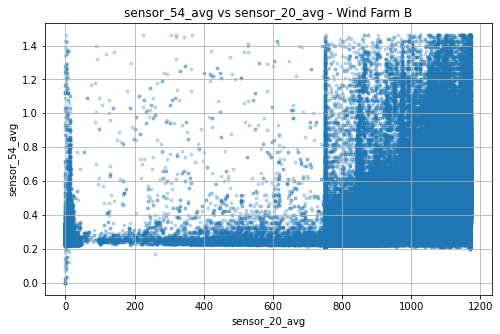

In [39]:
#20 vs 54 b

temp = merged_b[["sensor_20_avg", "sensor_54_avg"]].dropna().copy()

upper = temp["sensor_54_avg"].quantile(0.995)
temp_trim = temp[temp["sensor_54_avg"] <= upper]

plt.figure(figsize=(8, 5))
plt.scatter(temp_trim["sensor_20_avg"], temp_trim["sensor_54_avg"], alpha=0.25, s=8)
plt.xlabel("sensor_20_avg")
plt.ylabel("sensor_54_avg")
plt.title("sensor_54_avg vs sensor_20_avg - Wind Farm B")
plt.grid(True)
plt.show()

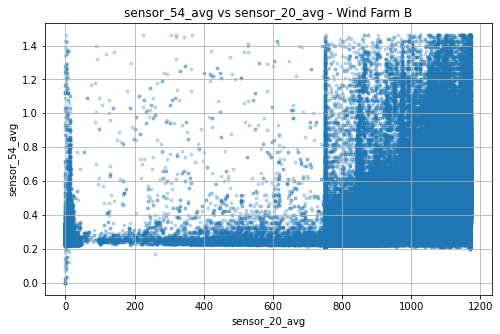

In [40]:
#trimmed outliers (wait did that in the one before remove this is redundant)
temp = merged_b[["sensor_20_avg", "sensor_54_avg"]].dropna().copy()

upper = temp["sensor_54_avg"].quantile(0.995)
temp_trim = temp[temp["sensor_54_avg"] <= upper]

plt.figure(figsize=(8, 5))
plt.scatter(temp_trim["sensor_20_avg"], temp_trim["sensor_54_avg"], alpha=0.25, s=8)
plt.xlabel("sensor_20_avg")
plt.ylabel("sensor_54_avg")
plt.title("sensor_54_avg vs sensor_20_avg - Wind Farm B")
plt.grid(True)
plt.show()

In [41]:
#imports for clustering and feature list

FARM_A_FEATURES = [
    "power_29_avg",
    "wind_speed_3_avg",
    "sensor_18_avg",
    "sensor_11_avg",
    "sensor_12_avg",
    "sensor_13_avg",
    "sensor_14_avg",
    "sensor_15_avg",
    "sensor_38_avg",
    "reactive_power_27_avg",
]

FARM_B_FEATURES = [
    "power_62_avg",
    "wind_speed_61_avg",
    "reactive_power_11_avg",
    "sensor_20_avg",
    "sensor_32_avg",
    "sensor_33_avg",
    "sensor_34_avg",
    "gearbox_temp_diff",
    "power_58_avg",
    "wind_speed_59_avg",
]

In [42]:
#clean and scale Farm metrics
df_a = merged[FARM_A_FEATURES + ["event_label", "source_file"]].copy()

df_a = df_a[df_a["wind_speed_3_avg"] >= 0]

df_a = df_a.dropna(subset=FARM_A_FEATURES).reset_index(drop=True)

print(f"Farm A clean: {df_a.shape[0]:,} rows × {len(FARM_A_FEATURES)} features")
print(f"Farm A label split:\n{df_a['event_label'].value_counts()}\n")


keep_b_raw = [c for c in FARM_B_FEATURES if c != "gearbox_temp_diff"] + \
             ["sensor_39_avg", "event_label", "source_file"]
df_b = merged_b[keep_b_raw].copy()

df_b = df_b[df_b["wind_speed_61_avg"] >= 0]
df_b = df_b[df_b["wind_speed_59_avg"] >= 0]

df_b = df_b[df_b["sensor_34_avg"] >= 0]

df_b = df_b[df_b["sensor_39_avg"] >= 0]

df_b = df_b[df_b["sensor_33_avg"] >= 0]

df_b["gearbox_temp_diff"] = df_b["sensor_39_avg"] - df_b["sensor_34_avg"]

df_b = df_b.drop(columns=["sensor_39_avg"])
df_b = df_b.dropna(subset=FARM_B_FEATURES).reset_index(drop=True)

print(f"Farm B clean: {df_b.shape[0]:,} rows × {len(FARM_B_FEATURES)} features")
print(f"Farm B label split:\n{df_b['event_label'].value_counts()}\n")


scaler_a = StandardScaler()
X_a = scaler_a.fit_transform(df_a[FARM_A_FEATURES])

scaler_b = StandardScaler()
X_b = scaler_b.fit_transform(df_b[FARM_B_FEATURES])

print(f"\nScaled arrays: Farm A {X_a.shape}, Farm B {X_b.shape}")

Farm A clean: 1,196,727 rows × 10 features
Farm A label split:
anomaly    649775
normal     546952
Name: event_label, dtype: int64

Farm B clean: 779,247 rows × 10 features
Farm B label split:
normal     456567
anomaly    322680
Name: event_label, dtype: int64


Scaled arrays: Farm A (1196727, 10), Farm B (779247, 10)


  k=2  inertia=5,812,422  silhouette=0.434
  k=3  inertia=3,778,498  silhouette=0.412
  k=4  inertia=3,171,062  silhouette=0.340
  k=5  inertia=2,809,901  silhouette=0.347
  k=6  inertia=2,642,058  silhouette=0.255
  k=7  inertia=2,282,878  silhouette=0.263
  k=8  inertia=2,120,845  silhouette=0.256
  k=9  inertia=1,973,168  silhouette=0.245
  k=10  inertia=1,862,322  silhouette=0.250


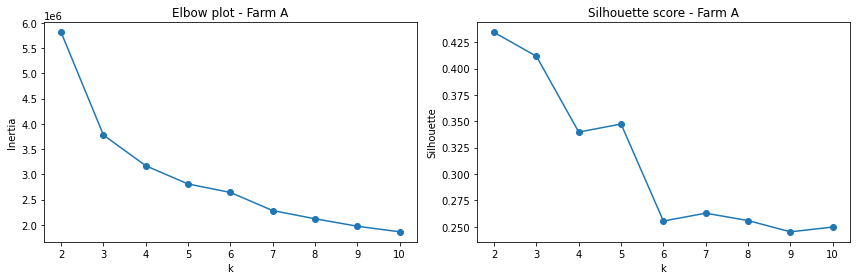

In [43]:
#farm a elbow n sillohuete

inertias, sil_scores = [], []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_a)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_a, labels, sample_size=5000, random_state=42))
    print(f"  k={k}  inertia={km.inertia_:,.0f}  silhouette={sil_scores[-1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(k_range), inertias, "o-")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia"); axes[0].set_title("Elbow plot - Farm A")
axes[1].plot(list(k_range), sil_scores, "o-")
axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette"); axes[1].set_title("Silhouette score - Farm A")
plt.tight_layout()
plt.show()

In [44]:
#k 3 fit farmm A
km_a = KMeans(n_clusters=3, n_init=10, random_state=42)
df_a["kmeans_cluster"] = km_a.fit_predict(X_a)

print(df_a["kmeans_cluster"].value_counts().sort_index())

0    499322
1    420004
2    277401
Name: kmeans_cluster, dtype: int64


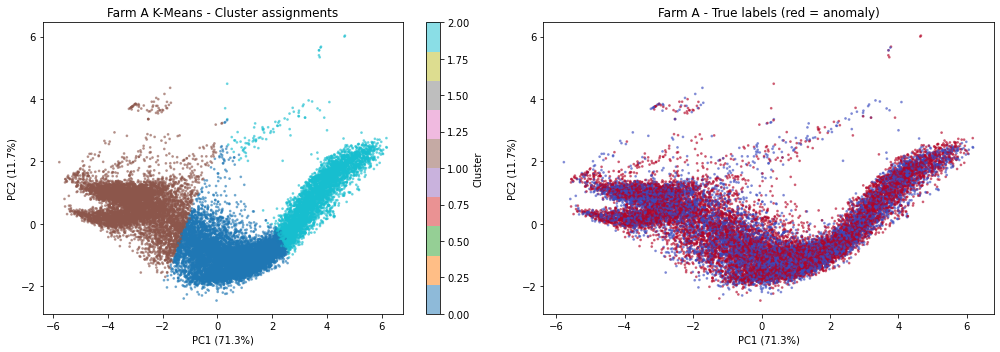

                   count  anomaly_count  normal_count  anomaly_rate  pct_of_data
kmeans_cluster                                                                  
2               277401.0       152053.0      125348.0      0.548134    23.179973
1               420004.0       228279.0      191725.0      0.543516    35.096058
0               499322.0       269443.0      229879.0      0.539618    41.723969


In [45]:
#K-means PCA visualisation vs labels


pca = PCA(n_components=2)

np.random.seed(42)
idx = np.random.choice(len(X_a), size=20000, replace=False)
X2 = pca.fit_transform(X_a[idx])
var = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

scatter1 = axes[0].scatter(X2[:, 0], X2[:, 1],
                           c=df_a["kmeans_cluster"].values[idx], cmap="tab10", s=3, alpha=0.5)
axes[0].set_title("Farm A K-Means - Cluster assignments")
axes[0].set_xlabel(f"PC1 ({var[0]:.1%})")
axes[0].set_ylabel(f"PC2 ({var[1]:.1%})")
plt.colorbar(scatter1, ax=axes[0], label="Cluster")

colours = np.array([0 if l == "normal" else 1 for l in df_a["event_label"].values])
scatter2 = axes[1].scatter(X2[:, 0], X2[:, 1],
                           c=colours[idx], cmap="coolwarm", s=3, alpha=0.5)
axes[1].set_title("Farm A - True labels (red = anomaly)")
axes[1].set_xlabel(f"PC1 ({var[0]:.1%})")
axes[1].set_ylabel(f"PC2 ({var[1]:.1%})")

plt.tight_layout()
plt.show()


profile = df_a.groupby("kmeans_cluster").apply(
    lambda g: pd.Series({
        "count": len(g),
        "anomaly_count": (g["event_label"] == "anomaly").sum(),
        "normal_count": (g["event_label"] == "normal").sum(),
        "anomaly_rate": (g["event_label"] == "anomaly").mean(),
    })
).sort_values("anomaly_rate", ascending=False)

profile["pct_of_data"] = profile["count"] / profile["count"].sum() * 100
print(profile.to_string())

In [46]:
#cluster centroids in origional units
centroids = scaler_a.inverse_transform(km_a.cluster_centers_)
cdf = pd.DataFrame(centroids, columns=FARM_A_FEATURES)
cdf.index.name = "cluster"
print(cdf[["power_29_avg", "wind_speed_3_avg", "sensor_18_avg"]].round(2))

         power_29_avg  wind_speed_3_avg  sensor_18_avg
cluster                                               
0                0.22              6.11        1375.07
1                0.03              2.83         345.08
2                0.81             11.48        1624.37


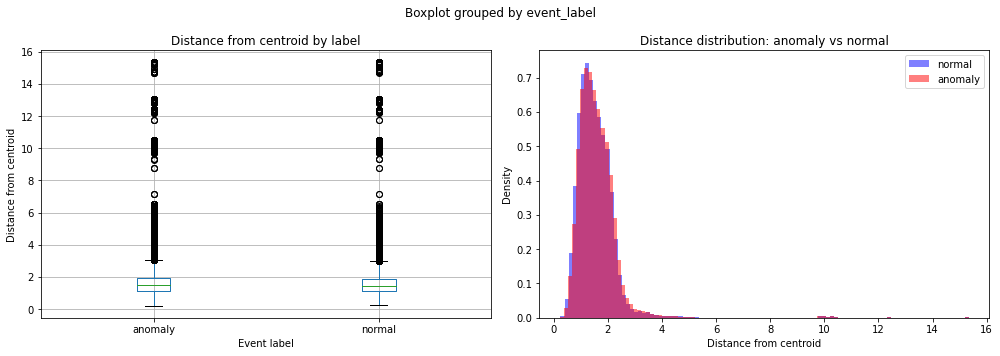

                count      mean       std       min       25%       50%  \
event_label                                                               
anomaly      649775.0  1.603306  0.853361  0.220253  1.142648  1.492371   
normal       546952.0  1.547677  0.770722  0.256285  1.101814  1.448281   

                  75%       max  
event_label                      
anomaly      1.914316  15.34052  
normal       1.869325  15.34052  


In [47]:
#distance from centiod anomaly scoring


distances = np.min(cdist(X_a, km_a.cluster_centers_), axis=1)
df_a["centroid_distance"] = distances

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_a.boxplot(column="centroid_distance", by="event_label", ax=axes[0])
axes[0].set_title("Distance from centroid by label")
axes[0].set_xlabel("Event label")
axes[0].set_ylabel("Distance from centroid")

for label, colour in [("normal", "blue"), ("anomaly", "red")]:
    subset = df_a[df_a["event_label"] == label]["centroid_distance"]
    axes[1].hist(subset, bins=100, alpha=0.5, label=label, color=colour, density=True)
axes[1].set_title("Distance distribution: anomaly vs normal")
axes[1].set_xlabel("Distance from centroid")
axes[1].set_ylabel("Density")
axes[1].legend()

plt.tight_layout()
plt.show()

print(df_a.groupby("event_label")["centroid_distance"].describe())

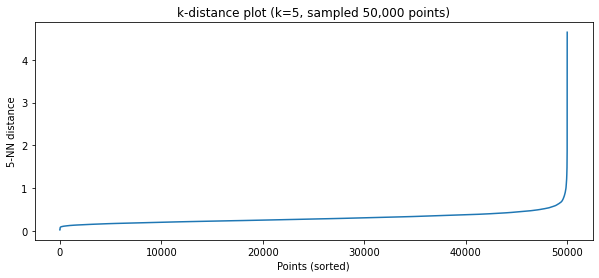

In [48]:
#DBSCAN k-distance plot for eps

np.random.seed(42)
idx = np.random.choice(len(X_a), size=50000, replace=False)
X_sample = X_a[idx]

nn = NearestNeighbors(n_neighbors=5)
nn.fit(X_sample)
distances, _ = nn.kneighbors(X_sample)
k_dists = np.sort(distances[:, -1])

plt.figure(figsize=(10, 4))
plt.plot(k_dists)
plt.xlabel("Points (sorted)")
plt.ylabel("5-NN distance")
plt.title("k-distance plot (k=5, sampled 50,000 points)")
plt.show()

In [49]:
#DBSCAN fit on 50k 


np.random.seed(42)
sample_idx = np.random.choice(len(X_a), size=50000, replace=False)
X_a_sample = X_a[sample_idx]
df_a_sample = df_a.iloc[sample_idx].copy()

db_a = DBSCAN(eps=0.8, min_samples=5, n_jobs=-1)
df_a_sample["dbscan_cluster"] = db_a.fit_predict(X_a_sample)

n_clusters = df_a_sample["dbscan_cluster"].nunique() - (1 if -1 in df_a_sample["dbscan_cluster"].values else 0)
n_noise = (df_a_sample["dbscan_cluster"] == -1).sum()

print(f"Clusters found: {n_clusters}")
print(f"Noise points: {n_noise:,} ({n_noise/len(df_a_sample):.1%})")
print(f"\nCluster sizes:")
print(df_a_sample["dbscan_cluster"].value_counts().sort_index())

Clusters found: 7
Noise points: 175 (0.4%)

Cluster sizes:
-1      175
 0    49620
 1      151
 2       19
 3       14
 4       12
 5        6
 6        3
Name: dbscan_cluster, dtype: int64


In [50]:
#anomaly rate per cluster
df_a_sample["dbscan_outlier"] = (df_a_sample["dbscan_cluster"] != 0).astype(int)

profile = df_a_sample.groupby("dbscan_cluster").apply(
    lambda g: pd.Series({
        "count": len(g),
        "anomaly_count": (g["event_label"] == "anomaly").sum(),
        "normal_count": (g["event_label"] == "normal").sum(),
        "anomaly_rate": (g["event_label"] == "anomaly").mean(),
    })
).sort_values("anomaly_rate", ascending=False)
print(profile.to_string())

print("\nOutlier vs core")
print(df_a_sample.groupby("dbscan_outlier")["event_label"].value_counts(normalize=True))

                  count  anomaly_count  normal_count  anomaly_rate
dbscan_cluster                                                    
 4                 12.0           10.0           2.0      0.833333
 3                 14.0           11.0           3.0      0.785714
 2                 19.0           12.0           7.0      0.631579
-1                175.0          106.0          69.0      0.605714
 1                151.0           82.0          69.0      0.543046
 0              49620.0        26895.0       22725.0      0.542019
 5                  6.0            3.0           3.0      0.500000
 6                  3.0            1.0           2.0      0.333333

Outlier vs core
dbscan_outlier  event_label
0               anomaly        0.542019
                normal         0.457981
1               anomaly        0.592105
                normal         0.407895
Name: event_label, dtype: float64


  k=2  inertia=4,481,102  silhouette=0.388
  k=3  inertia=3,024,762  silhouette=0.408
  k=4  inertia=2,635,517  silhouette=0.281
  k=5  inertia=2,283,448  silhouette=0.298
  k=6  inertia=1,981,723  silhouette=0.306
  k=7  inertia=1,759,712  silhouette=0.315
  k=8  inertia=1,635,130  silhouette=0.267
  k=9  inertia=1,526,775  silhouette=0.275
  k=10  inertia=1,449,058  silhouette=0.250


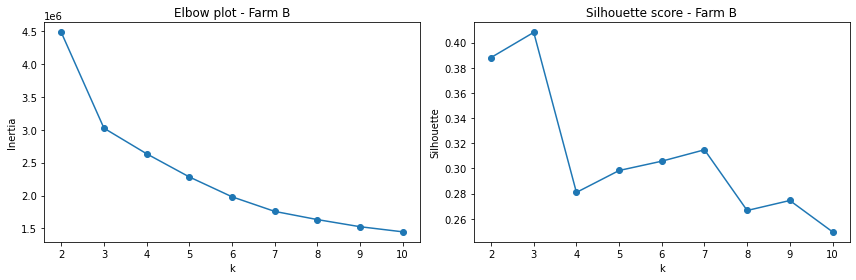

In [51]:
#Farm B elbow and silohuette scores
inertias_b, sil_b = [], []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_b)
    inertias_b.append(km.inertia_)
    sil_b.append(silhouette_score(X_b, labels, sample_size=5000, random_state=42))
    print(f"  k={k}  inertia={km.inertia_:,.0f}  silhouette={sil_b[-1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(k_range), inertias_b, "o-")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia"); axes[0].set_title("Elbow plot - Farm B")
axes[1].plot(list(k_range), sil_b, "o-")
axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette"); axes[1].set_title("Silhouette score - Farm B")
plt.tight_layout()
plt.show()

In [52]:
#fit k 3 and inspect the centroids
km_b = KMeans(n_clusters=3, n_init=10, random_state=42)
df_b["kmeans_cluster"] = km_b.fit_predict(X_b)

print(df_b["kmeans_cluster"].value_counts().sort_index())

centroids_b = scaler_b.inverse_transform(km_b.cluster_centers_)
cdf_b = pd.DataFrame(centroids_b, columns=FARM_B_FEATURES)
cdf_b.index.name = "cluster"
print("\nCluster centroids:")
print(cdf_b[["power_62_avg", "wind_speed_61_avg", "sensor_20_avg"]].round(2))

0    344715
1    350062
2     84470
Name: kmeans_cluster, dtype: int64

Cluster centroids:
         power_62_avg  wind_speed_61_avg  sensor_20_avg
cluster                                                
0                0.68              12.74        1130.15
1                0.18               6.37         815.46
2               -0.00               6.22          11.20


In [53]:
#distance from centoid

distances_b = np.min(cdist(X_b, km_b.cluster_centers_), axis=1)
df_b["centroid_distance"] = distances_b

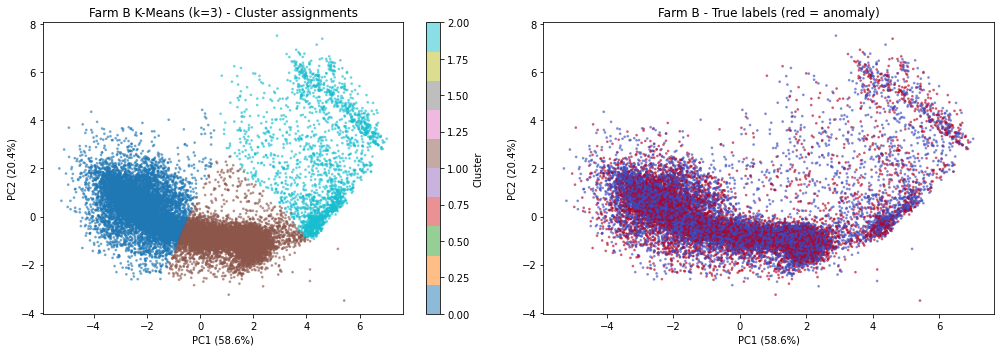

                   count  anomaly_count  normal_count  anomaly_rate  pct_of_data
kmeans_cluster                                                                  
1               350062.0       146082.0      203980.0      0.417303    44.923112
2                84470.0        34846.0       49624.0      0.412525    10.839952
0               344715.0       141752.0      202963.0      0.411215    44.236936


In [54]:
#PCA visualisation
np.random.seed(42)
idx = np.random.choice(len(X_b), size=20000, replace=False)

pca_b = PCA(n_components=2)
X2_b = pca_b.fit_transform(X_b[idx])
var_b = pca_b.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

scatter1 = axes[0].scatter(X2_b[:, 0], X2_b[:, 1],
                           c=df_b["kmeans_cluster"].values[idx], cmap="tab10", s=3, alpha=0.5)
axes[0].set_title("Farm B K-Means (k=3) - Cluster assignments")
axes[0].set_xlabel(f"PC1 ({var_b[0]:.1%})")
axes[0].set_ylabel(f"PC2 ({var_b[1]:.1%})")
plt.colorbar(scatter1, ax=axes[0], label="Cluster")

colours = np.array([0 if l == "normal" else 1 for l in df_b["event_label"].values])
scatter2 = axes[1].scatter(X2_b[:, 0], X2_b[:, 1],
                           c=colours[idx], cmap="coolwarm", s=3, alpha=0.5)
axes[1].set_title("Farm B - True labels (red = anomaly)")
axes[1].set_xlabel(f"PC1 ({var_b[0]:.1%})")
axes[1].set_ylabel(f"PC2 ({var_b[1]:.1%})")

plt.tight_layout()
plt.show()

profile_b = df_b.groupby("kmeans_cluster").apply(
    lambda g: pd.Series({
        "count": len(g),
        "anomaly_count": (g["event_label"] == "anomaly").sum(),
        "normal_count": (g["event_label"] == "normal").sum(),
        "anomaly_rate": (g["event_label"] == "anomaly").mean(),
    })
).sort_values("anomaly_rate", ascending=False)
profile_b["pct_of_data"] = profile_b["count"] / profile_b["count"].sum() * 100
print(profile_b.to_string())

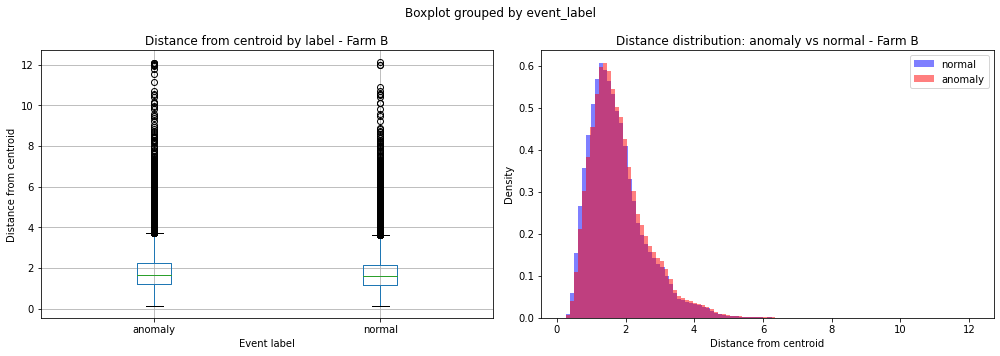

                count   mean    std    min    25%    50%    75%     max
event_label                                                            
anomaly      322680.0  1.822  0.845  0.143  1.229  1.653  2.226  12.084
normal       456567.0  1.755  0.833  0.143  1.165  1.593  2.148  12.115


In [55]:
#distance distribution 
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_b.boxplot(column="centroid_distance", by="event_label", ax=axes[0])
axes[0].set_title("Distance from centroid by label - Farm B")
axes[0].set_xlabel("Event label")
axes[0].set_ylabel("Distance from centroid")

for label, colour in [("normal", "blue"), ("anomaly", "red")]:
    subset = df_b[df_b["event_label"] == label]["centroid_distance"]
    axes[1].hist(subset, bins=100, alpha=0.5, label=label, color=colour, density=True)
axes[1].set_title("Distance distribution: anomaly vs normal - Farm B")
axes[1].set_xlabel("Distance from centroid")
axes[1].set_ylabel("Density")
axes[1].legend()

plt.tight_layout()
plt.show()

print(df_b.groupby("event_label")["centroid_distance"].describe().round(3))

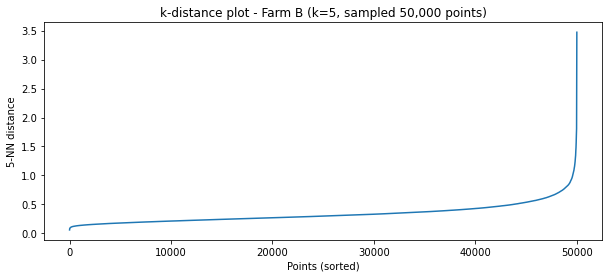

In [56]:
#k-distance plot
np.random.seed(42)
sample_idx_b = np.random.choice(len(X_b), size=50000, replace=False)
X_b_sample = X_b[sample_idx_b]
df_b_sample = df_b.iloc[sample_idx_b].copy()

nn_b = NearestNeighbors(n_neighbors=5)
nn_b.fit(X_b_sample)
distances_nn, _ = nn_b.kneighbors(X_b_sample)
k_dists_b = np.sort(distances_nn[:, -1])

plt.figure(figsize=(10, 4))
plt.plot(k_dists_b)
plt.xlabel("Points (sorted)")
plt.ylabel("5-NN distance")
plt.title("k-distance plot - Farm B (k=5, sampled 50,000 points)")
plt.show()

In [57]:
#fit on 50k samples 
db_b = DBSCAN(eps=0.8, min_samples=5, n_jobs=-1)
df_b_sample["dbscan_cluster"] = db_b.fit_predict(X_b_sample)

n_clusters = df_b_sample["dbscan_cluster"].nunique() - (1 if -1 in df_b_sample["dbscan_cluster"].values else 0)
n_noise = (df_b_sample["dbscan_cluster"] == -1).sum()

print(f"Clusters found: {n_clusters}")
print(f"Noise points: {n_noise:,} ({n_noise/len(df_b_sample):.1%})")
print(f"\nCluster sizes:")
print(df_b_sample["dbscan_cluster"].value_counts().sort_index())

print("\nAnomaly profile:")
db_profile_b = df_b_sample.groupby("dbscan_cluster").apply(
    lambda g: pd.Series({
        "count": len(g),
        "anomaly_count": (g["event_label"] == "anomaly").sum(),
        "normal_count": (g["event_label"] == "normal").sum(),
        "anomaly_rate": (g["event_label"] == "anomaly").mean(),
    })
).sort_values("anomaly_rate", ascending=False)
print(db_profile_b.to_string())

Clusters found: 8
Noise points: 551 (1.1%)

Cluster sizes:
-1      551
 0    49406
 1        8
 2        6
 3       10
 4        4
 5        5
 6        5
 7        5
Name: dbscan_cluster, dtype: int64

Anomaly profile:
                  count  anomaly_count  normal_count  anomaly_rate
dbscan_cluster                                                    
 5                  5.0            5.0           0.0      1.000000
 7                  5.0            4.0           1.0      0.800000
 2                  6.0            3.0           3.0      0.500000
 4                  4.0            2.0           2.0      0.500000
 0              49406.0        20678.0       28728.0      0.418532
 6                  5.0            2.0           3.0      0.400000
-1                551.0          212.0         339.0      0.384755
 3                 10.0            2.0           8.0      0.200000
 1                  8.0            0.0           8.0      0.000000


In [58]:
#train/test split (80/20) file level


file_labels = df_a.groupby("source_file")["event_label"].first()

anomaly_files = file_labels[file_labels == "anomaly"].index.values
normal_files = file_labels[file_labels == "normal"].index.values

np.random.seed(42)
np.random.shuffle(anomaly_files)
np.random.shuffle(normal_files)

a_split = int(len(anomaly_files) * 0.8)
n_split = int(len(normal_files) * 0.8)

train_files = np.concatenate([anomaly_files[:a_split], normal_files[:n_split]])
test_files = np.concatenate([anomaly_files[a_split:], normal_files[n_split:]])

train_a = df_a[df_a["source_file"].isin(train_files)]
test_a = df_a[df_a["source_file"].isin(test_files)]

print(f"Anomaly files: {len(anomaly_files)} total -> {a_split} train, {len(anomaly_files)-a_split} test")
print(f"Normal files:  {len(normal_files)} total -> {n_split} train, {len(normal_files)-n_split} test")
print(f"\nTrain: {len(train_a):,} rows")
print(f"Test:  {len(test_a):,} rows")
print(f"\nTrain labels:\n{train_a['event_label'].value_counts()}")
print(f"\nTest labels:\n{test_a['event_label'].value_counts()}")

scaler_knn = StandardScaler()
X_train = scaler_knn.fit_transform(train_a[FARM_A_FEATURES])
X_test = scaler_knn.transform(test_a[FARM_A_FEATURES])

y_train = (train_a["event_label"] == "anomaly").astype(int)
y_test = (test_a["event_label"] == "anomaly").astype(int)

Anomaly files: 12 total -> 9 train, 3 test
Normal files:  10 total -> 8 train, 2 test

Train: 925,973 rows
Test:  270,754 rows

Train labels:
anomaly    487900
normal     438073
Name: event_label, dtype: int64

Test labels:
anomaly    161875
normal     108879
Name: event_label, dtype: int64


Training on 30,000 normal-only rows

Threshold analysis:
  threshold=0.382  precision=0.571  recall=0.191  flagged=54,151
  threshold=0.409  precision=0.576  recall=0.145  flagged=40,613
  threshold=0.447  precision=0.599  recall=0.100  flagged=27,076
  threshold=0.518  precision=0.651  recall=0.054  flagged=13,538


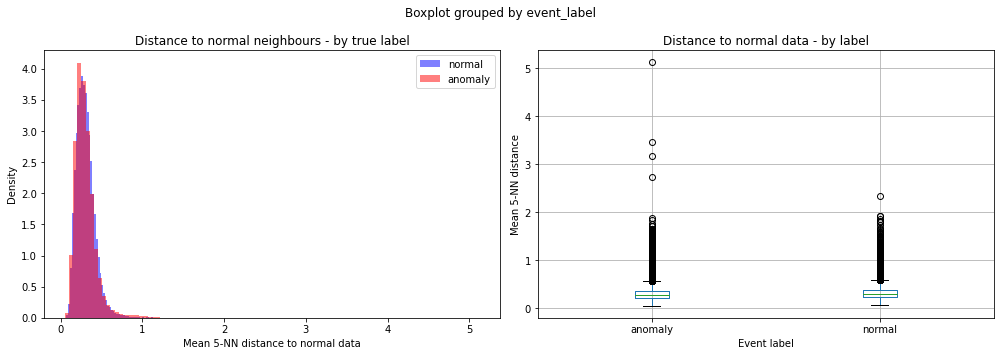

In [59]:
#one class KNN (row level)


X_train_normal = scaler_knn.transform(train_a[train_a["event_label"] == "normal"][FARM_A_FEATURES])

np.random.seed(42)
sample_idx = np.random.choice(len(X_train_normal), size=30000, replace=False)
X_train_normal_sample = X_train_normal[sample_idx]

print(f"Training on {len(X_train_normal_sample):,} normal-only rows")

nn = NearestNeighbors(n_neighbors=5, n_jobs=-1)
nn.fit(X_train_normal_sample)

distances_test, _ = nn.kneighbors(X_test)
mean_dist = distances_test.mean(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for label, colour in [("normal", "blue"), ("anomaly", "red")]:
    mask = test_a["event_label"].values == label
    axes[0].hist(mean_dist[mask], bins=100, alpha=0.5, label=label, color=colour, density=True)
axes[0].set_title("Distance to normal neighbours - by true label")
axes[0].set_xlabel("Mean 5-NN distance to normal data")
axes[0].set_ylabel("Density")
axes[0].legend()

thresholds = np.percentile(mean_dist, [80, 85, 90, 95])
print("\nThreshold analysis:")
for t in thresholds:
    y_pred_oc = (mean_dist > t).astype(int)
    tp = ((y_pred_oc == 1) & (y_test.values == 1)).sum()
    fp = ((y_pred_oc == 1) & (y_test.values == 0)).sum()
    fn = ((y_pred_oc == 0) & (y_test.values == 1)).sum()
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    print(f"  threshold={t:.3f}  precision={precision:.3f}  recall={recall:.3f}  flagged={y_pred_oc.sum():,}")

test_a_copy = test_a.copy()
test_a_copy["dist_to_normal"] = mean_dist
test_a_copy.boxplot(column="dist_to_normal", by="event_label", ax=axes[1])
axes[1].set_title("Distance to normal data - by label")
axes[1].set_xlabel("Event label")
axes[1].set_ylabel("Mean 5-NN distance")

plt.tight_layout()
plt.show()

Training on 100,000 rows
Sample split: 52,738 anomaly, 47,262 normal
  Random Forest - Farm A
              precision    recall  f1-score   support

      normal       0.34      0.33      0.34    108879
     anomaly       0.56      0.58      0.57    161875

    accuracy                           0.48    270754
   macro avg       0.45      0.45      0.45    270754
weighted avg       0.47      0.48      0.48    270754



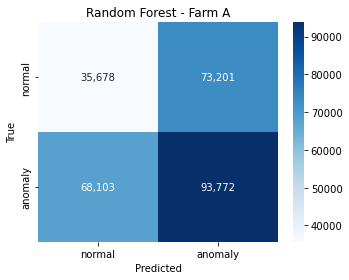

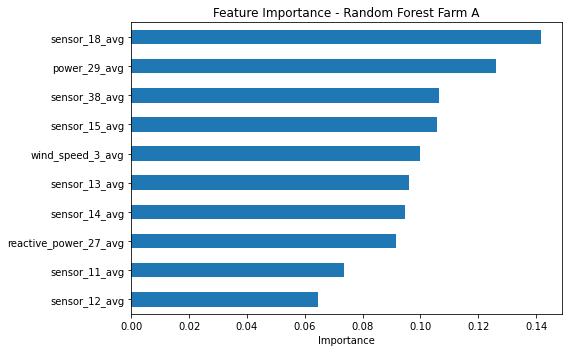

In [60]:
#random forrest (row level)

np.random.seed(42)
sample_size = 100000
train_idx = np.random.choice(len(X_train), size=sample_size, replace=False)
X_train_sample = X_train[train_idx]
y_train_sample = y_train.values[train_idx]

print(f"Training on {sample_size:,} rows")
print(f"Sample split: {(y_train_sample==1).sum():,} anomaly, {(y_train_sample==0).sum():,} normal")

rf = RandomForestClassifier(n_estimators=100, max_depth=20, random_state=42, n_jobs=-1)
rf.fit(X_train_sample, y_train_sample)

y_pred_rf = rf.predict(X_test)


print("  Random Forest - Farm A")
print(classification_report(y_test, y_pred_rf, target_names=["normal", "anomaly"]))

cm = confusion_matrix(y_test, y_pred_rf)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues",
            xticklabels=["normal", "anomaly"], yticklabels=["normal", "anomaly"], ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title("Random Forest - Farm A")
plt.tight_layout()
plt.show()

importances = pd.Series(rf.feature_importances_, index=FARM_A_FEATURES).sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(8, 5))
importances.plot(kind="barh", ax=ax)
ax.set_title("Feature Importance - Random Forest Farm A")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

In [61]:
#temporal features engennering
df_a_temp = merged[FARM_A_FEATURES + ["event_label", "source_file", "time_stamp"]].copy()
df_a_temp = df_a_temp[df_a_temp["wind_speed_3_avg"] >= 0]
df_a_temp = df_a_temp.dropna(subset=FARM_A_FEATURES).reset_index(drop=True)

df_a_temp = df_a_temp.sort_values(["source_file", "time_stamp"]).reset_index(drop=True)

for feat in ["power_29_avg", "sensor_11_avg", "sensor_13_avg", "sensor_15_avg"]:
    grouped = df_a_temp.groupby("source_file")[feat]
    
    df_a_temp[f"{feat}_roll_mean_6"] = grouped.transform(lambda x: x.rolling(6, min_periods=1).mean())
    df_a_temp[f"{feat}_roll_std_6"] = grouped.transform(lambda x: x.rolling(6, min_periods=1).std().fillna(0))
    df_a_temp[f"{feat}_diff"] = grouped.transform(lambda x: x.diff().fillna(0))
    df_a_temp[f"{feat}_deviation"] = df_a_temp[feat] - df_a_temp[f"{feat}_roll_mean_6"]

print(f"Total rows: {len(df_a_temp):,}")
print(f"New temporal features: {len([c for c in df_a_temp.columns if 'roll' in c or 'diff' in c or 'deviation' in c])}")
print("\nSample:")
print(df_a_temp[[c for c in df_a_temp.columns if 'roll' in c or 'diff' in c or 'deviation' in c]].head())

Total rows: 1,196,727
New temporal features: 16

Sample:
   power_29_avg_roll_mean_6  power_29_avg_roll_std_6  power_29_avg_diff  \
0                  0.000049                 0.000000           0.000000   
1                  0.000024                 0.000034          -0.000049   
2                  0.000016                 0.000028           0.000000   
3                  0.000012                 0.000024           0.000000   
4                  0.000010                 0.000022           0.000000   

   power_29_avg_deviation  sensor_11_avg_roll_mean_6  \
0                0.000000                  39.000000   
1               -0.000024                  38.500000   
2               -0.000016                  38.333333   
3               -0.000012                  38.250000   
4               -0.000010                  38.200000   

   sensor_11_avg_roll_std_6  sensor_11_avg_diff  sensor_11_avg_deviation  \
0                  0.000000                 0.0                 0.000000   
1  

Total features: 26 (10 original + 16 temporal)
  Random Forest + Temporal Features - Farm A
              precision    recall  f1-score   support

      normal       0.35      0.31      0.33    108879
     anomaly       0.57      0.60      0.58    161875

    accuracy                           0.49    270754
   macro avg       0.46      0.46      0.46    270754
weighted avg       0.48      0.49      0.48    270754



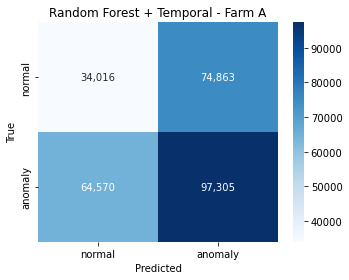

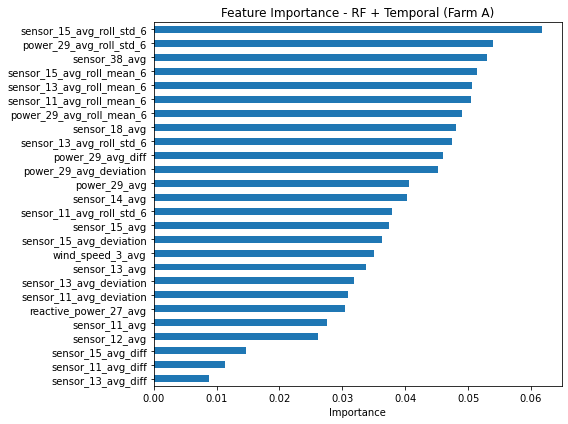

In [62]:
#random forrest temporal features
TEMPORAL_FEATURES = [c for c in df_a_temp.columns if "roll" in c or "diff" in c or "deviation" in c]
ALL_FEATURES = FARM_A_FEATURES + TEMPORAL_FEATURES

print(f"Total features: {len(ALL_FEATURES)} ({len(FARM_A_FEATURES)} original + {len(TEMPORAL_FEATURES)} temporal)")

train_temp = df_a_temp[df_a_temp["source_file"].isin(train_files)]
test_temp = df_a_temp[df_a_temp["source_file"].isin(test_files)]

scaler_temp = StandardScaler()
X_train_temp = scaler_temp.fit_transform(train_temp[ALL_FEATURES])
X_test_temp = scaler_temp.transform(test_temp[ALL_FEATURES])

y_train_temp = (train_temp["event_label"] == "anomaly").astype(int)
y_test_temp = (test_temp["event_label"] == "anomaly").astype(int)

np.random.seed(42)
sample_idx = np.random.choice(len(X_train_temp), size=100000, replace=False)
X_train_sample = X_train_temp[sample_idx]
y_train_sample = y_train_temp.values[sample_idx]

rf_temp = RandomForestClassifier(n_estimators=100, max_depth=20, random_state=42, n_jobs=-1)
rf_temp.fit(X_train_sample, y_train_sample)

y_pred_temp = rf_temp.predict(X_test_temp)


print("  Random Forest + Temporal Features - Farm A")
print(classification_report(y_test_temp, y_pred_temp, target_names=["normal", "anomaly"]))

cm = confusion_matrix(y_test_temp, y_pred_temp)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues",
            xticklabels=["normal", "anomaly"], yticklabels=["normal", "anomaly"], ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title("Random Forest + Temporal - Farm A")
plt.tight_layout()
plt.show()

importances = pd.Series(rf_temp.feature_importances_, index=ALL_FEATURES).sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(8, 6))
importances.plot(kind="barh", ax=ax)
ax.set_title("Feature Importance - RF + Temporal (Farm A)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

In [63]:
#hourly aggregation
df_a_temp["time_stamp"] = pd.to_datetime(df_a_temp["time_stamp"])

df_a_temp["hour_bin"] = df_a_temp.groupby("source_file")["time_stamp"].transform(
    lambda x: ((x - x.min()).dt.total_seconds() // 3600).astype(int)
)

agg_dict = {feat: ["mean", "std"] for feat in FARM_A_FEATURES}
agg_dict["event_label"] = "first"

df_a_hourly = df_a_temp.groupby(["source_file", "hour_bin"]).agg(agg_dict).reset_index()

df_a_hourly.columns = ["source_file", "hour_bin"] + \
    [f"{feat}_{stat}" for feat in FARM_A_FEATURES for stat in ["mean", "std"]] + \
    ["event_label"]

std_cols = [c for c in df_a_hourly.columns if c.endswith("_std")]
df_a_hourly[std_cols] = df_a_hourly[std_cols].fillna(0)

HOURLY_FEATURES = [c for c in df_a_hourly.columns if c.endswith(("_mean", "_std"))]

print(f"Hourly rows: {len(df_a_hourly):,} (down from {len(df_a_temp):,})")
print(f"Features: {len(HOURLY_FEATURES)}")
print(f"\nLabel split:\n{df_a_hourly['event_label'].value_counts()}")

Hourly rows: 199,718 (down from 1,196,727)
Features: 20

Label split:
anomaly    108444
normal      91274
Name: event_label, dtype: int64


Train: 154,538 rows
Test:  45,180 rows
  Random Forest (Hourly) - Farm A
              precision    recall  f1-score   support

      normal       0.43      0.44      0.44     18168
     anomaly       0.62      0.61      0.61     27012

    accuracy                           0.54     45180
   macro avg       0.53      0.53      0.53     45180
weighted avg       0.54      0.54      0.54     45180



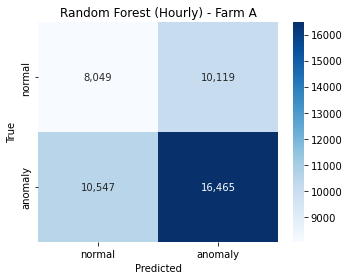

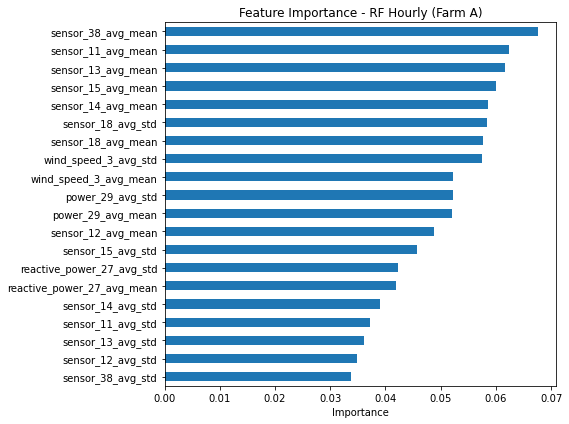

In [64]:
#rando forrest (hourly)
train_hourly = df_a_hourly[df_a_hourly["source_file"].isin(train_files)]
test_hourly = df_a_hourly[df_a_hourly["source_file"].isin(test_files)]

HOURLY_FEATURES = [c for c in df_a_hourly.columns if c.endswith(("_mean", "_std"))]

scaler_hourly = StandardScaler()
X_train_h = scaler_hourly.fit_transform(train_hourly[HOURLY_FEATURES])
X_test_h = scaler_hourly.transform(test_hourly[HOURLY_FEATURES])

y_train_h = (train_hourly["event_label"] == "anomaly").astype(int)
y_test_h = (test_hourly["event_label"] == "anomaly").astype(int)

print(f"Train: {len(train_hourly):,} rows")
print(f"Test:  {len(test_hourly):,} rows")

rf_hourly = RandomForestClassifier(n_estimators=100, max_depth=20, random_state=42, n_jobs=-1)
rf_hourly.fit(X_train_h, y_train_h)

y_pred_h = rf_hourly.predict(X_test_h)


print("  Random Forest (Hourly) - Farm A")
print(classification_report(y_test_h, y_pred_h, target_names=["normal", "anomaly"]))

cm = confusion_matrix(y_test_h, y_pred_h)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues",
            xticklabels=["normal", "anomaly"], yticklabels=["normal", "anomaly"], ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title("Random Forest (Hourly) - Farm A")
plt.tight_layout()
plt.show()

importances = pd.Series(rf_hourly.feature_importances_, index=HOURLY_FEATURES).sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(8, 6))
importances.plot(kind="barh", ax=ax)
ax.set_title("Feature Importance - RF Hourly (Farm A)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

Training on 73,106 normal-only hourly rows
Testing on 45,180 rows (27,012 anomaly, 18,168 normal)


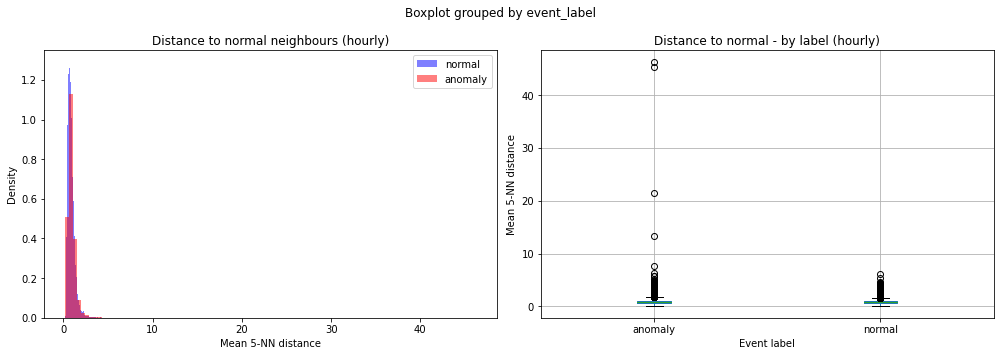


Threshold analysis:
  threshold=1.126  precision=0.636  recall=0.213  f1=0.319  flagged=9,036
  threshold=1.221  precision=0.637  recall=0.160  f1=0.256  flagged=6,777
  threshold=1.359  precision=0.635  recall=0.106  f1=0.182  flagged=4,518
  threshold=1.603  precision=0.631  recall=0.053  f1=0.097  flagged=2,259


In [65]:
#one class KNN hourly


train_hourly = df_a_hourly[df_a_hourly["source_file"].isin(train_files)]
test_hourly = df_a_hourly[df_a_hourly["source_file"].isin(test_files)]

HOURLY_FEATURES = [c for c in df_a_hourly.columns if c.endswith(("_mean", "_std"))]

scaler_hourly = StandardScaler()
X_train_h = scaler_hourly.fit_transform(train_hourly[HOURLY_FEATURES])
X_test_h = scaler_hourly.transform(test_hourly[HOURLY_FEATURES])

y_test_h = (test_hourly["event_label"] == "anomaly").astype(int)

X_train_normal = X_train_h[(train_hourly["event_label"] == "normal").values]
print(f"Training on {len(X_train_normal):,} normal-only hourly rows")
print(f"Testing on {len(X_test_h):,} rows ({y_test_h.sum():,} anomaly, {(y_test_h==0).sum():,} normal)")

nn_hourly = NearestNeighbors(n_neighbors=5, n_jobs=-1)
nn_hourly.fit(X_train_normal)

distances_h, _ = nn_hourly.kneighbors(X_test_h)
mean_dist_h = distances_h.mean(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for label, colour in [("normal", "blue"), ("anomaly", "red")]:
    mask = test_hourly["event_label"].values == label
    axes[0].hist(mean_dist_h[mask], bins=100, alpha=0.5, label=label, color=colour, density=True)
axes[0].set_title("Distance to normal neighbours (hourly)")
axes[0].set_xlabel("Mean 5-NN distance")
axes[0].set_ylabel("Density")
axes[0].legend()

test_hourly_copy = test_hourly.copy()
test_hourly_copy["dist_to_normal"] = mean_dist_h
test_hourly_copy.boxplot(column="dist_to_normal", by="event_label", ax=axes[1])
axes[1].set_title("Distance to normal - by label (hourly)")
axes[1].set_xlabel("Event label")
axes[1].set_ylabel("Mean 5-NN distance")

plt.tight_layout()
plt.show()

print("\nThreshold analysis:")
thresholds = np.percentile(mean_dist_h, [80, 85, 90, 95])
for t in thresholds:
    y_pred_oc = (mean_dist_h > t).astype(int)
    tp = ((y_pred_oc == 1) & (y_test_h.values == 1)).sum()
    fp = ((y_pred_oc == 1) & (y_test_h.values == 0)).sum()
    fn = ((y_pred_oc == 0) & (y_test_h.values == 1)).sum()
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    print(f"  threshold={t:.3f}  precision={precision:.3f}  recall={recall:.3f}  f1={f1:.3f}  flagged={y_pred_oc.sum():,}")

Training One-Class SVM on 30,000 normal-only hourly rows
  One-Class SVM (Hourly) - Farm A
              precision    recall  f1-score   support

      normal       0.41      0.92      0.57     18168
     anomaly       0.66      0.11      0.18     27012

    accuracy                           0.43     45180
   macro avg       0.54      0.51      0.37     45180
weighted avg       0.56      0.43      0.34     45180



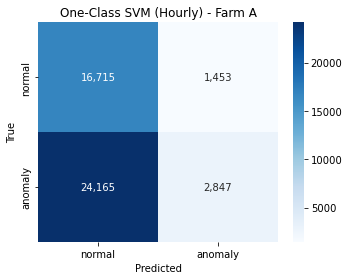

In [66]:
#one class SVM horuly 


np.random.seed(42)
sample_size = min(30000, len(X_train_normal))
sample_idx = np.random.choice(len(X_train_normal), size=sample_size, replace=False)
X_train_normal_sample = X_train_normal[sample_idx]

print(f"Training One-Class SVM on {sample_size:,} normal-only hourly rows")

ocsvm = OneClassSVM(kernel="rbf", gamma="scale", nu=0.1)
ocsvm.fit(X_train_normal_sample)

y_pred_svm = ocsvm.predict(X_test_h)
y_pred_svm = (y_pred_svm == -1).astype(int)

print("  One-Class SVM (Hourly) - Farm A")
print(classification_report(y_test_h, y_pred_svm, target_names=["normal", "anomaly"]))

cm = confusion_matrix(y_test_h, y_pred_svm)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues",
            xticklabels=["normal", "anomaly"], yticklabels=["normal", "anomaly"], ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title("One-Class SVM (Hourly) - Farm A")
plt.tight_layout()
plt.show()

Files: 22
Features: 30

Label split:
anomaly    12
normal     10
Name: event_label, dtype: int64

Rows per file:
count       22.0
mean     54397.0
std        712.0
min      53035.0
25%      53915.0
50%      54278.0
75%      54829.0
max      56156.0
Name: row_count, dtype: float64
  Random Forest (File-Level, LOO CV) - Farm A
              precision    recall  f1-score   support

      normal       0.36      0.40      0.38        10
     anomaly       0.45      0.42      0.43        12

    accuracy                           0.41        22
   macro avg       0.41      0.41      0.41        22
weighted avg       0.41      0.41      0.41        22


Per-file predictions:
  Y 0.csv: true=anomaly, pred=anomaly
  N 10.csv: true=anomaly, pred=normal
  N 13.csv: true=normal, pred=anomaly
  N 14.csv: true=normal, pred=anomaly
  N 17.csv: true=normal, pred=anomaly
  N 22.csv: true=anomaly, pred=normal
  N 24.csv: true=normal, pred=anomaly
  Y 25.csv: true=normal, pred=normal
  Y 26.csv: true=ano

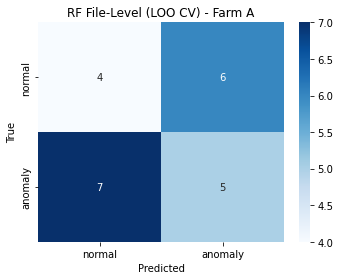

In [67]:
#random forrest with 30 features
agg_dict = {}
for feat in FARM_A_FEATURES:
    agg_dict[f"{feat}_mean"] = (feat, "mean")
    agg_dict[f"{feat}_std"] = (feat, "std")
    agg_dict[f"{feat}_range"] = (feat, lambda x: x.max() - x.min())

df_a_file = df_a_temp.groupby("source_file").agg(
    event_label=("event_label", "first"),
    row_count=("event_label", "size"),
    **agg_dict
).reset_index()

std_cols = [c for c in df_a_file.columns if c.endswith("_std")]
df_a_file[std_cols] = df_a_file[std_cols].fillna(0)

FILE_FEATURES = [c for c in df_a_file.columns if c.endswith(("_mean", "_std", "_range"))]

print(f"Files: {len(df_a_file)}")
print(f"Features: {len(FILE_FEATURES)}")
print(f"\nLabel split:\n{df_a_file['event_label'].value_counts()}")
print(f"\nRows per file:\n{df_a_file['row_count'].describe().round(0)}")

X_file = df_a_file[FILE_FEATURES].values
y_file = (df_a_file["event_label"] == "anomaly").astype(int).values

loo = LeaveOneOut()
y_true_all, y_pred_all = [], []
file_names = df_a_file["source_file"].values

for train_idx, test_idx in loo.split(X_file):
    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_file[train_idx])
    X_te = scaler.transform(X_file[test_idx])
    
    rf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1)
    rf.fit(X_tr, y_file[train_idx])
    
    pred = rf.predict(X_te)[0]
    y_true_all.append(y_file[test_idx][0])
    y_pred_all.append(pred)

y_true_all = np.array(y_true_all)
y_pred_all = np.array(y_pred_all)

print("  Random Forest (File-Level, LOO CV) - Farm A")
print(classification_report(y_true_all, y_pred_all, target_names=["normal", "anomaly"]))

print("\nPer-file predictions:")
for name, true, pred in zip(file_names, y_true_all, y_pred_all):
    status = "Y" if true == pred else "N"
    print(f"  {status} {name}: true={['normal','anomaly'][true]}, pred={['normal','anomaly'][pred]}")

cm = confusion_matrix(y_true_all, y_pred_all)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["normal", "anomaly"], yticklabels=["normal", "anomaly"], ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title("RF File-Level (LOO CV) - Farm A")
plt.tight_layout()
plt.show()

In [68]:
#anomaly vs normal file level (10 features)
file_summary = df_a_temp.groupby("source_file").agg(
    event_label=("event_label", "first"),
    **{f"{feat}_mean": (feat, "mean") for feat in FARM_A_FEATURES},
    **{f"{feat}_std": (feat, "std") for feat in FARM_A_FEATURES}
).reset_index()

anomaly_files = file_summary[file_summary["event_label"] == "anomaly"]
normal_files = file_summary[file_summary["event_label"] == "normal"]

print("File-level MEANS: anomaly vs normal\n")
for feat in FARM_A_FEATURES:
    a_val = anomaly_files[f"{feat}_mean"].mean()
    n_val = normal_files[f"{feat}_mean"].mean()
    diff_pct = ((a_val - n_val) / n_val * 100) if n_val != 0 else 0
    print(f"{feat:>25s}:  anomaly={a_val:.3f}  normal={n_val:.3f}  diff={diff_pct:+.1f}%")

print("\n File-level STD: anomaly vs normal \n")
for feat in FARM_A_FEATURES:
    a_val = anomaly_files[f"{feat}_std"].mean()
    n_val = normal_files[f"{feat}_std"].mean()
    diff_pct = ((a_val - n_val) / n_val * 100) if n_val != 0 else 0
    print(f"{feat:>25s}:  anomaly={a_val:.3f}  normal={n_val:.3f}  diff={diff_pct:+.1f}%")

File-level MEANS: anomaly vs normal

             power_29_avg:  anomaly=0.290  normal=0.286  diff=+1.3%
         wind_speed_3_avg:  anomaly=6.213  normal=6.190  diff=+0.4%
            sensor_18_avg:  anomaly=1071.116  normal=1071.919  diff=-0.1%
            sensor_11_avg:  anomaly=51.624  normal=51.640  diff=-0.0%
            sensor_12_avg:  anomaly=47.590  normal=47.634  diff=-0.1%
            sensor_13_avg:  anomaly=43.868  normal=43.426  diff=+1.0%
            sensor_14_avg:  anomaly=47.648  normal=46.976  diff=+1.4%
            sensor_15_avg:  anomaly=65.471  normal=65.834  diff=-0.6%
            sensor_38_avg:  anomaly=65.028  normal=65.558  diff=-0.8%
    reactive_power_27_avg:  anomaly=0.249  normal=0.251  diff=-0.9%

 File-level STD: anomaly vs normal 

             power_29_avg:  anomaly=0.335  normal=0.332  diff=+0.8%
         wind_speed_3_avg:  anomaly=3.729  normal=3.702  diff=+0.7%
            sensor_18_avg:  anomaly=615.431  normal=613.548  diff=+0.3%
            sensor_

In [69]:
#anomaly vs normal all  46 features, file level
additional_features = {
    "Hydraulic":    ["sensor_41_avg"],
    "Pitch":        ["sensor_5_avg"],
    "Transformer":  ["sensor_39_avg", "sensor_40_avg"],
    "Electrical":   ["sensor_22_avg", "sensor_23_avg",
                     "sensor_24_avg", "sensor_25_avg",
                     "sensor_32_avg", "sensor_33_avg",
                     "sensor_34_avg"],
    "Controller":   ["sensor_6_avg", "sensor_7_avg",
                     "sensor_8_avg", "sensor_9_avg"],
    "Stator":       ["sensor_16_avg", "sensor_17_avg"],
    "Inverter":     ["sensor_35_avg", "sensor_36_avg",
                     "sensor_37_avg", "sensor_21_avg"],
    "Other":        ["sensor_0_avg", "sensor_43_avg",
                     "sensor_52_avg", "wind_speed_4_avg"],
}

all_avg_cols = [c for c in merged.columns if c.endswith("_avg")]

df_all = merged[all_avg_cols + ["event_label", "source_file"]].copy()
df_all = df_all.dropna().reset_index(drop=True)

file_means = df_all.groupby("source_file").agg(
    event_label=("event_label", "first"),
    **{feat: (feat, "mean") for feat in all_avg_cols}
).reset_index()

anomaly_means = file_means[file_means["event_label"] == "anomaly"][all_avg_cols].mean()
normal_means = file_means[file_means["event_label"] == "normal"][all_avg_cols].mean()

diff_pct = ((anomaly_means - normal_means) / normal_means * 100).abs().sort_values(ascending=False)

print("Top 20 features by % difference (anomaly vs normal file means) \n")
for feat in diff_pct.head(20).index:
    a = anomaly_means[feat]
    n = normal_means[feat]
    d = diff_pct[feat]
    print(f"{feat:>25s}:  anomaly={a:.3f}  normal={n:.3f}  diff={d:.1f}%")

Top 20 features by % difference (anomaly vs normal file means) 

             sensor_2_avg:  anomaly=0.073  normal=0.189  diff=61.6%
             sensor_5_avg:  anomaly=9.470  normal=9.084  diff=4.3%
            sensor_40_avg:  anomaly=68.086  normal=70.576  diff=3.5%
            sensor_41_avg:  anomaly=38.756  normal=37.540  diff=3.2%
            sensor_42_avg:  anomaly=172.959  normal=178.061  diff=2.9%
             sensor_1_avg:  anomaly=168.846  normal=173.182  diff=2.5%
            sensor_22_avg:  anomaly=0.838  normal=0.859  diff=2.4%
            sensor_39_avg:  anomaly=70.340  normal=72.015  diff=2.3%
            sensor_19_avg:  anomaly=30.532  normal=30.042  diff=1.6%
             sensor_8_avg:  anomaly=80.208  normal=78.949  diff=1.6%
            sensor_14_avg:  anomaly=47.648  normal=46.976  diff=1.4%
            sensor_23_avg:  anomaly=484.076  normal=477.537  diff=1.4%
            sensor_43_avg:  anomaly=30.291  normal=29.888  diff=1.3%
             power_30_avg:  anomaly=0

In [70]:
#per fault type feat differences
fault_map = {
    "68.csv": "Transformer failure",
    "22.csv": "Hydraulic group",
    "72.csv": "Gearbox failure", 
    "73.csv": "Hydraulic group",
    "0.csv": "Generator bearing failure",
    "26.csv": "Hydraulic group",
    "40.csv": "Generator bearing failure",
    "42.csv": "Hydraulic group",
    "10.csv": "Gearbox failure",
    "45.csv": "Hydraulic group",
    "84.csv": "Hydraulic group",
    "51.csv": "Gearbox bearings damaged",
}

file_means["fault_type"] = file_means["source_file"].map(fault_map).fillna("normal")

normal_row = file_means[file_means["fault_type"] == "normal"][all_avg_cols].mean()

for fault in ["Generator bearing failure", "Hydraulic group", "Gearbox failure", "Transformer failure", "Gearbox bearings damaged"]:
    fault_rows = file_means[file_means["fault_type"] == fault]
    if len(fault_rows) == 0:
        continue
    fault_row = fault_rows[all_avg_cols].mean()
    diff = ((fault_row - normal_row) / normal_row * 100).abs().sort_values(ascending=False)
    
    print(f"  {fault} ({len(fault_rows)} files)")
    for feat in diff.head(10).index:
        f_val = fault_row[feat]
        n_val = normal_row[feat]
        print(f"  {feat:>25s}:  fault={f_val:.3f}  normal={n_val:.3f}  diff={diff[feat]:+.1f}%")

  Generator bearing failure (2 files)
               sensor_2_avg:  fault=0.468  normal=0.189  diff=+147.7%
               sensor_5_avg:  fault=10.819  normal=9.084  diff=+19.1%
              sensor_41_avg:  fault=42.725  normal=37.540  diff=+13.8%
              sensor_38_avg:  fault=71.290  normal=65.558  diff=+8.7%
              sensor_39_avg:  fault=76.866  normal=72.015  diff=+6.7%
              sensor_40_avg:  fault=75.262  normal=70.576  diff=+6.6%
              sensor_14_avg:  fault=49.500  normal=46.976  diff=+5.4%
              sensor_22_avg:  fault=0.817  normal=0.859  diff=+4.9%
              sensor_13_avg:  fault=45.514  normal=43.426  diff=+4.8%
      reactive_power_27_avg:  fault=0.239  normal=0.251  diff=+4.8%
  Hydraulic group (6 files)
               sensor_2_avg:  fault=0.326  normal=0.189  diff=+72.5%
              sensor_40_avg:  fault=67.453  normal=70.576  diff=+4.4%
              sensor_23_avg:  fault=494.857  normal=477.537  diff=+3.6%
              sensor_25_av

Files: 22
Features: 138

Label split:
anomaly    12
normal     10
Name: event_label, dtype: int64
  RF All Features File-Level (LOO CV) - Farm A
              precision    recall  f1-score   support

      normal       0.50      0.40      0.44        10
     anomaly       0.57      0.67      0.62        12

    accuracy                           0.55        22
   macro avg       0.54      0.53      0.53        22
weighted avg       0.54      0.55      0.54        22


Per-file predictions:
  Y 0.csv: true=anomaly (Generator bearing), pred=anomaly
  N 10.csv: true=anomaly (Gearbox failure), pred=normal
  N 13.csv: true=normal (normal), pred=anomaly
  N 14.csv: true=normal (normal), pred=anomaly
  N 17.csv: true=normal (normal), pred=anomaly
  Y 22.csv: true=anomaly (Hydraulic group), pred=anomaly
  N 24.csv: true=normal (normal), pred=anomaly
  Y 25.csv: true=normal (normal), pred=normal
  Y 26.csv: true=anomaly (Hydraulic group), pred=anomaly
  N 3.csv: true=normal (normal), pred=anoma

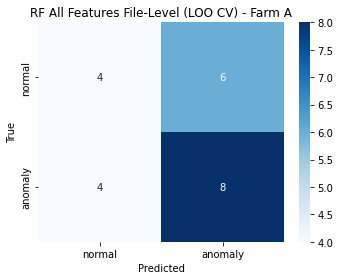

In [71]:
#random forrest with 138 features

all_avg_cols = [c for c in merged.columns if c.endswith("_avg")]

df_a_all = merged[all_avg_cols + ["event_label", "source_file"]].copy()
df_a_all = df_a_all.dropna().reset_index(drop=True)

agg_dict = {}
for feat in all_avg_cols:
    agg_dict[f"{feat}_mean"] = (feat, "mean")
    agg_dict[f"{feat}_std"] = (feat, "std")
    agg_dict[f"{feat}_range"] = (feat, lambda x: x.max() - x.min())

df_a_file = df_a_all.groupby("source_file").agg(
    event_label=("event_label", "first"),
    **agg_dict
).reset_index()

std_cols = [c for c in df_a_file.columns if c.endswith("_std")]
df_a_file[std_cols] = df_a_file[std_cols].fillna(0)

FILE_FEATURES = [c for c in df_a_file.columns if c.endswith(("_mean", "_std", "_range"))]

print(f"Files: {len(df_a_file)}")
print(f"Features: {len(FILE_FEATURES)}")
print(f"\nLabel split:\n{df_a_file['event_label'].value_counts()}")

X_file = df_a_file[FILE_FEATURES].values
y_file = (df_a_file["event_label"] == "anomaly").astype(int).values

loo = LeaveOneOut()
y_true_all, y_pred_all = [], []
file_names = df_a_file["source_file"].values

for train_idx, test_idx in loo.split(X_file):
    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_file[train_idx])
    X_te = scaler.transform(X_file[test_idx])
    
    rf = RandomForestClassifier(n_estimators=200, max_depth=5, random_state=42, n_jobs=-1)
    rf.fit(X_tr, y_file[train_idx])
    
    pred = rf.predict(X_te)[0]
    y_true_all.append(y_file[test_idx][0])
    y_pred_all.append(pred)

y_true_all = np.array(y_true_all)
y_pred_all = np.array(y_pred_all)


print("  RF All Features File-Level (LOO CV) - Farm A")
print(classification_report(y_true_all, y_pred_all, target_names=["normal", "anomaly"]))

print("\nPer-file predictions:")
fault_map = {
    "68.csv": "Transformer failure", "22.csv": "Hydraulic group",
    "72.csv": "Gearbox failure", "73.csv": "Hydraulic group",
    "0.csv": "Generator bearing", "26.csv": "Hydraulic group",
    "40.csv": "Generator bearing", "42.csv": "Hydraulic group",
    "10.csv": "Gearbox failure", "45.csv": "Hydraulic group",
    "84.csv": "Hydraulic group", "51.csv": "Gearbox bearings",
}
for name, true, pred in zip(file_names, y_true_all, y_pred_all):
    status = "Y" if true == pred else "N"
    fault = fault_map.get(name, "normal")
    print(f"  {status} {name}: true={['normal','anomaly'][true]} ({fault}), pred={['normal','anomaly'][pred]}")

cm = confusion_matrix(y_true_all, y_pred_all)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["normal", "anomaly"], yticklabels=["normal", "anomaly"], ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title("RF All Features File-Level (LOO CV) - Farm A")
plt.tight_layout()
plt.show()

Hourly rows: 199,718
Features: 92

Label split:
anomaly    108444
normal      91274
Name: event_label, dtype: int64

Train: 154,538 rows from 17 files
Test:  45,180 rows from 5 files
  RF Hourly All Features - Farm A
              precision    recall  f1-score   support

      normal       0.52      0.57      0.54     18168
     anomaly       0.69      0.64      0.66     27012

    accuracy                           0.61     45180
   macro avg       0.60      0.61      0.60     45180
weighted avg       0.62      0.61      0.61     45180



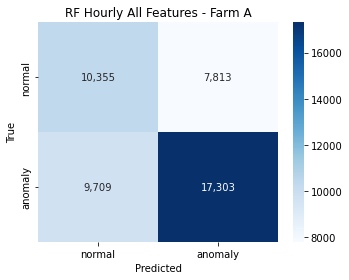

In [72]:
#random forrest hourly all 46
all_avg_cols = [c for c in merged.columns if c.endswith("_avg")]

df_a_all = merged[all_avg_cols + ["event_label", "source_file", "time_stamp"]].copy()
df_a_all = df_a_all.dropna().reset_index(drop=True)
df_a_all["time_stamp"] = pd.to_datetime(df_a_all["time_stamp"])

df_a_all["hour_bin"] = df_a_all.groupby("source_file")["time_stamp"].transform(
    lambda x: ((x - x.min()).dt.total_seconds() // 3600).astype(int)
)

agg_dict = {feat: ["mean", "std"] for feat in all_avg_cols}
agg_dict["event_label"] = "first"
agg_dict["source_file"] = "first"

df_a_hourly_all = df_a_all.groupby(["source_file", "hour_bin"]).agg(agg_dict).reset_index(drop=True)

df_a_hourly_all.columns = [f"{feat}_{stat}" if stat != "" else feat 
                            for feat, stat in df_a_hourly_all.columns]

df_a_hourly_all = df_a_hourly_all.rename(columns={
    "event_label_first": "event_label",
    "source_file_first": "source_file"
})

std_cols = [c for c in df_a_hourly_all.columns if c.endswith("_std")]
df_a_hourly_all[std_cols] = df_a_hourly_all[std_cols].fillna(0)

HOURLY_ALL_FEATURES = [c for c in df_a_hourly_all.columns if c.endswith(("_mean", "_std"))]

print(f"Hourly rows: {len(df_a_hourly_all):,}")
print(f"Features: {len(HOURLY_ALL_FEATURES)}")
print(f"\nLabel split:\n{df_a_hourly_all['event_label'].value_counts()}")

file_labels = df_a_hourly_all.groupby("source_file")["event_label"].first()
anomaly_files = file_labels[file_labels == "anomaly"].index.values
normal_files = file_labels[file_labels == "normal"].index.values

np.random.seed(42)
np.random.shuffle(anomaly_files)
np.random.shuffle(normal_files)

a_split = int(len(anomaly_files) * 0.8)
n_split = int(len(normal_files) * 0.8)
train_files = np.concatenate([anomaly_files[:a_split], normal_files[:n_split]])
test_files = np.concatenate([anomaly_files[a_split:], normal_files[n_split:]])

train_h = df_a_hourly_all[df_a_hourly_all["source_file"].isin(train_files)]
test_h = df_a_hourly_all[df_a_hourly_all["source_file"].isin(test_files)]

scaler_h = StandardScaler()
X_train_h = scaler_h.fit_transform(train_h[HOURLY_ALL_FEATURES])
X_test_h = scaler_h.transform(test_h[HOURLY_ALL_FEATURES])
y_train_h = (train_h["event_label"] == "anomaly").astype(int)
y_test_h = (test_h["event_label"] == "anomaly").astype(int)

print(f"\nTrain: {len(train_h):,} rows from {len(train_files)} files")
print(f"Test:  {len(test_h):,} rows from {len(test_files)} files")

rf_h_all = RandomForestClassifier(n_estimators=200, max_depth=None, random_state=42, n_jobs=-1)
rf_h_all.fit(X_train_h, y_train_h)
y_pred_h_all = rf_h_all.predict(X_test_h)


print("  RF Hourly All Features - Farm A")

print(classification_report(y_test_h, y_pred_h_all, target_names=["normal", "anomaly"]))

cm = confusion_matrix(y_test_h, y_pred_h_all)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues",
            xticklabels=["normal", "anomaly"], yticklabels=["normal", "anomaly"], ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title("RF Hourly All Features - Farm A")
plt.tight_layout()
plt.show()

Top 30 features:
sensor_2_avg_std        0.018853
sensor_40_avg_mean      0.018515
sensor_1_avg_std        0.016870
sensor_41_avg_mean      0.016803
sensor_33_avg_mean      0.016522
sensor_2_avg_mean       0.016309
sensor_8_avg_mean       0.015842
sensor_34_avg_mean      0.015798
sensor_38_avg_mean      0.015735
sensor_32_avg_mean      0.015693
sensor_1_avg_mean       0.015688
sensor_34_avg_std       0.015382
sensor_31_avg_mean      0.015363
sensor_32_avg_std       0.015222
sensor_33_avg_std       0.015139
sensor_39_avg_mean      0.014908
sensor_42_avg_mean      0.014874
sensor_13_avg_mean      0.014514
sensor_36_avg_mean      0.014254
sensor_31_avg_std       0.014223
wind_speed_3_avg_std    0.013430
sensor_14_avg_mean      0.013317
sensor_11_avg_mean      0.013104
wind_speed_4_avg_std    0.013085
sensor_43_avg_mean      0.012805
sensor_24_avg_mean      0.012797
sensor_18_avg_std       0.012769
sensor_42_avg_std       0.012717
sensor_9_avg_mean       0.012195
sensor_19_avg_mean      0.

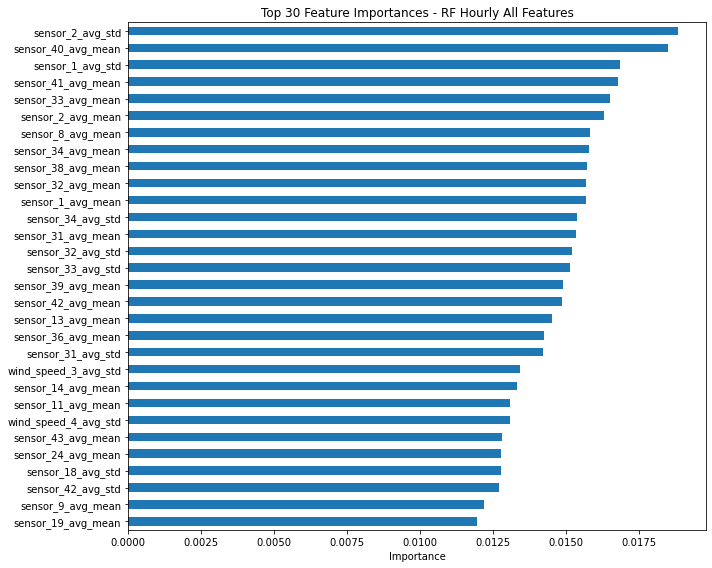


Top 20 features capture 31.7% of total importance


In [73]:
#feature importance
importances = pd.Series(rf_h_all.feature_importances_, index=HOURLY_ALL_FEATURES).sort_values(ascending=False)

print("Top 30 features:")
print(importances.head(30).to_string())

fig, ax = plt.subplots(figsize=(10, 8))
importances.head(30).sort_values().plot(kind="barh", ax=ax)
ax.set_title("Top 30 Feature Importances - RF Hourly All Features")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

top20 = importances.head(20).sum()
total = importances.sum()
print(f"\nTop 20 features capture {top20/total:.1%} of total importance")

In [74]:
#faults mapped and file list n feature removal 
warnings.filterwarnings("ignore")
 
FAULT_MAP = {
    "0.csv":  "Generator bearing failure",
    "40.csv": "Generator bearing failure",
    "72.csv": "Gearbox failure",
    "10.csv": "Gearbox failure",
    "51.csv": "Gearbox bearings damaged",
    "68.csv": "Transformer failure",
    "22.csv": "Hydraulic group",
    "26.csv": "Hydraulic group",
    "42.csv": "Hydraulic group",
    "45.csv": "Hydraulic group",
    "84.csv": "Hydraulic group",
    "73.csv": "Hydraulic group",
}
 
NORMAL_FILES = ["3.csv", "13.csv", "14.csv", "17.csv", "24.csv",
                "25.csv", "38.csv", "69.csv", "71.csv", "92.csv"]
 
ANOMALY_FILES = list(FAULT_MAP.keys())
 
FAULT_WINDOWS = {
    "0.csv":  ("2023-08-06 06:10", "2023-08-20 06:10"),
    "72.csv": ("2023-10-10 08:40", "2023-10-17 08:40"),
    "10.csv": ("2023-10-11 08:40", "2023-10-18 08:40"),
    "51.csv": ("2023-10-06 01:30", "2023-10-17 16:10"),
    "68.csv": ("2023-07-28 13:20", "2023-08-11 13:10"),
    "26.csv": ("2023-10-12 10:20", "2023-10-19 10:20"),
}
 
REMOVE_FEATURES = ["sensor_1_avg", "sensor_2_avg", "sensor_42_avg",
                    "wind_speed_4_avg", "power_30_avg", "reactive_power_28_avg"]
 
print("Setup complete.")
print(f"Anomaly files: {len(ANOMALY_FILES)}, Normal files: {len(NORMAL_FILES)}")
 

Setup complete.
Anomaly files: 12, Normal files: 10


In [75]:
#build trimmed daily aggregated data frame
all_avg_cols = [c for c in merged.columns if c.endswith("_avg") 
                and c not in REMOVE_FEATURES]
print(f"Using {len(all_avg_cols)} features (after trimming)")
 
df_full = merged[all_avg_cols + ["event_label", "source_file", "time_stamp"]].copy()
df_full = df_full.dropna().reset_index(drop=True)
df_full["time_stamp"] = pd.to_datetime(df_full["time_stamp"])
df_full["date"] = df_full["time_stamp"].dt.date
 
agg_dict = {feat: ["mean", "std"] for feat in all_avg_cols}
agg_dict["event_label"] = "first"
agg_dict["time_stamp"] = "first"
 
df_daily = df_full.groupby(["source_file", "date"]).agg(agg_dict).reset_index()
 
new_cols = []
for col in df_daily.columns:
    if col[1] == "":
        new_cols.append(col[0])
    elif col[1] == "first":
        new_cols.append(col[0])
    else:
        new_cols.append(f"{col[0]}_{col[1]}")
df_daily.columns = new_cols
 
std_cols = [c for c in df_daily.columns if c.endswith("_std")]
df_daily[std_cols] = df_daily[std_cols].fillna(0)
 
FEATURES = [c for c in df_daily.columns if c.endswith(("_mean", "_std"))]
 
df_daily["fault_type"] = df_daily["source_file"].map(FAULT_MAP).fillna("normal")
 
print(f"Daily rows: {len(df_daily):,}")
print(f"Features per day: {len(FEATURES)}")
print(f"Files: {df_daily['source_file'].nunique()}")
print(f"\nRows per label:")
print(df_daily["event_label"].value_counts())

Using 40 features (after trimming)
Daily rows: 8,389
Features per day: 80
Files: 22

Rows per label:
anomaly    4555
normal     3834
Name: event_label, dtype: int64


In [76]:
#Tranning KNN on normal days
normal_daily = df_daily[df_daily["event_label"] == "normal"].copy()
print(f"Training on {len(normal_daily):,} normal days from {normal_daily['source_file'].nunique()} files")
 
scaler_knn = StandardScaler()
X_normal = scaler_knn.fit_transform(normal_daily[FEATURES])
 
nn = NearestNeighbors(n_neighbors=5, n_jobs=-1)
nn.fit(X_normal)
 
all_results = []
 
for fname in df_daily["source_file"].unique():
    file_days = df_daily[df_daily["source_file"] == fname].copy()
    X_file = scaler_knn.transform(file_days[FEATURES])
    dist, _ = nn.kneighbors(X_file)
    file_days["raw_score"] = dist.mean(axis=1)
    file_days["rolling_7d"] = file_days["raw_score"].rolling(7, min_periods=1).mean()
    
    n_baseline = max(3, len(file_days) // 4)
    baseline_mean = file_days["raw_score"].iloc[:n_baseline].mean()
    baseline_std = file_days["raw_score"].iloc[:n_baseline].std()
    if baseline_std < 0.01:
        baseline_std = 0.01
    
    file_days["normalised_score"] = (file_days["raw_score"] - baseline_mean) / baseline_std
    file_days["norm_rolling_7d"] = file_days["normalised_score"].rolling(7, min_periods=1).mean()
    
    all_results.append(file_days)
 
df_scored = pd.concat(all_results, ignore_index=True)
print(f"Scored {df_scored['source_file'].nunique()} files, {len(df_scored):,} total days")
 

Training on 3,834 normal days from 10 files
Scored 22 files, 8,389 total days


In [77]:
#per feature z scores
normal_means = normal_daily[FEATURES].mean()
normal_stds = normal_daily[FEATURES].std()
normal_stds = normal_stds.replace(0, 0.01)
 
zscore_results = []
 
for fname in df_daily["source_file"].unique():
    file_days = df_daily[df_daily["source_file"] == fname].copy()
    
    z_scores = (file_days[FEATURES].values - normal_means.values) / normal_stds.values
    
    file_days["zscore_mean"] = np.abs(z_scores).mean(axis=1)
    
    file_days["zscore_max"] = np.abs(z_scores).max(axis=1)
    
    top5 = np.sort(np.abs(z_scores), axis=1)[:, -5:]
    file_days["zscore_top5"] = top5.mean(axis=1)
    
    for col in ["zscore_mean", "zscore_max", "zscore_top5"]:
        file_days[f"{col}_7d"] = file_days[col].rolling(7, min_periods=1).mean()
    
    zscore_results.append(file_days[["source_file", "date", "time_stamp", "event_label", "fault_type",
                                     "zscore_mean", "zscore_max", "zscore_top5",
                                     "zscore_mean_7d", "zscore_max_7d", "zscore_top5_7d"]])
 
df_zscore = pd.concat(zscore_results, ignore_index=True)
 
df_all = df_scored.merge(
    df_zscore[["source_file", "date", "zscore_mean", "zscore_max", "zscore_top5",
               "zscore_mean_7d", "zscore_max_7d", "zscore_top5_7d"]],
    on=["source_file", "date"],
    how="left"
)
 
print("Combined scoring complete.")
print(f"Scoring columns: raw_score, normalised_score, zscore_mean, zscore_max, zscore_top5")

Combined scoring complete.
Scoring columns: raw_score, normalised_score, zscore_mean, zscore_max, zscore_top5


In [78]:
#file level summary stats
file_summary = []
 
for fname in df_all["source_file"].unique():
    fdata = df_all[df_all["source_file"] == fname]
    label = fdata["event_label"].iloc[0]
    fault_type = fdata["fault_type"].iloc[0]
    
    row = {
        "file": fname,
        "label": label,
        "fault_type": fault_type,
        "n_days": len(fdata),
        "knn_max": fdata["rolling_7d"].max(),
        "knn_mean": fdata["rolling_7d"].mean(),
        "knn_last7_mean": fdata["rolling_7d"].iloc[-7:].mean() if len(fdata) >= 7 else fdata["rolling_7d"].mean(),
        "norm_max": fdata["norm_rolling_7d"].max(),
        "norm_last7": fdata["norm_rolling_7d"].iloc[-7:].mean() if len(fdata) >= 7 else fdata["norm_rolling_7d"].mean(),
        "ztop5_max": fdata["zscore_top5_7d"].max(),
        "ztop5_mean": fdata["zscore_top5_7d"].mean(),
        "ztop5_last7": fdata["zscore_top5_7d"].iloc[-7:].mean() if len(fdata) >= 7 else fdata["zscore_top5_7d"].mean(),
        "zmax_max": fdata["zscore_max_7d"].max(),
    }
    file_summary.append(row)
 
df_files = pd.DataFrame(file_summary)
 

print("  FILE-LEVEL ANOMALY SCORES (sorted by zscore_top5 max)")
display_cols = ["file", "label", "fault_type", "n_days", "knn_max", "norm_max", "ztop5_max", "zmax_max"]
print(df_files.sort_values("ztop5_max", ascending=False)[display_cols].to_string(index=False))

  FILE-LEVEL ANOMALY SCORES (sorted by zscore_top5 max)
  file   label                fault_type  n_days   knn_max  norm_max  ztop5_max  zmax_max
13.csv  normal                    normal     382 29.448058  2.391338  16.411180 26.007920
72.csv anomaly           Gearbox failure     380  9.000133  2.254872   6.547459 10.159781
51.csv anomaly  Gearbox bearings damaged     382  9.000133  2.259328   6.547459 10.159781
22.csv anomaly           Hydraulic group     374  9.000133  2.177894   6.547459 10.159781
40.csv anomaly Generator bearing failure     393  5.315917  2.742621   5.381080  9.921303
10.csv anomaly           Gearbox failure     375  5.315917  1.976627   5.381080  9.921303
17.csv  normal                    normal     386  3.583519  1.442971   5.381080  9.921303
42.csv anomaly           Hydraulic group     377  5.315917  1.913460   5.381080  9.921303
 3.csv  normal                    normal     389  5.315917  3.699607   5.381080  9.921303
26.csv anomaly           Hydraulic group    

In [79]:
#scoring method comparison and optimal threshold

scoring_methods = {
    "KNN raw (7d max)":   "knn_max",
    "KNN normalised max": "norm_max",
    "Z-score top5 max":   "ztop5_max",
    "Z-score max max":    "zmax_max",
}
 
y_true = (df_files["label"] == "anomaly").astype(int).values
 

print("  THRESHOLD OPTIMISATION - FILE-LEVEL BINARY CLASSIFICATION")

 
best_method = None
best_f1 = 0
best_threshold = 0
 
for method_name, col in scoring_methods.items():
    scores = df_files[col].values
    
    thresholds = np.linspace(scores.min(), scores.max(), 200)
    f1s = []
    for t in thresholds:
        preds = (scores >= t).astype(int)
        f1s.append(f1_score(y_true, preds, zero_division=0))
    
    f1s = np.array(f1s)
    best_idx = f1s.argmax()
    opt_thresh = thresholds[best_idx]
    opt_f1 = f1s[best_idx]
    
    preds = (scores >= opt_thresh).astype(int)
    tp = ((preds == 1) & (y_true == 1)).sum()
    fp = ((preds == 1) & (y_true == 0)).sum()
    fn = ((preds == 0) & (y_true == 1)).sum()
    tn = ((preds == 0) & (y_true == 0)).sum()
    
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    print(f"\n{method_name}:")
    print(f"  Optimal threshold: {opt_thresh:.3f}")
    print(f"  F1: {opt_f1:.3f}  |  Precision: {precision:.3f}  |  Recall: {recall:.3f}")
    print(f"  TP={tp}  FP={fp}  FN={fn}  TN={tn}")
    
    if opt_f1 > best_f1:
        best_f1 = opt_f1
        best_method = method_name
        best_threshold = opt_thresh
        best_col = col
 

print(f"  BEST METHOD: {best_method}")
print(f"  F1 = {best_f1:.3f}, threshold = {best_threshold:.3f}")

 
df_files["predicted"] = (df_files[best_col] >= best_threshold).map({True: "ANOMALY", False: "NORMAL"})
df_files["correct"] = (
    ((df_files["predicted"] == "ANOMALY") & (df_files["label"] == "anomaly")) |
    ((df_files["predicted"] == "NORMAL") & (df_files["label"] == "normal"))
)
 
print(f"\nPer-file predictions ({best_method}, threshold={best_threshold:.3f}):")

for _, row in df_files.sort_values("file").iterrows():
    status = "Y" if row["correct"] else "N"
    print(f"  {status}  {row['file']:>8s}  true={row['label']:>8s}  pred={row['predicted']:>8s}  "
          f"score={row[best_col]:.3f}  ({row['fault_type']})")
 

  THRESHOLD OPTIMISATION - FILE-LEVEL BINARY CLASSIFICATION

KNN raw (7d max):
  Optimal threshold: 3.731
  F1: 0.846  |  Precision: 0.786  |  Recall: 0.917
  TP=11  FP=3  FN=1  TN=7

KNN normalised max:
  Optimal threshold: 1.482
  F1: 0.750  |  Precision: 0.600  |  Recall: 1.000
  TP=12  FP=8  FN=0  TN=2

Z-score top5 max:
  Optimal threshold: 2.669
  F1: 0.710  |  Precision: 0.579  |  Recall: 0.917
  TP=11  FP=8  FN=1  TN=2

Z-score max max:
  Optimal threshold: 2.925
  F1: 0.706  |  Precision: 0.545  |  Recall: 1.000
  TP=12  FP=10  FN=0  TN=0
  BEST METHOD: KNN raw (7d max)
  F1 = 0.846, threshold = 3.731

Per-file predictions (KNN raw (7d max), threshold=3.731):
  Y     0.csv  true= anomaly  pred= ANOMALY  score=6.784  (Generator bearing failure)
  Y    10.csv  true= anomaly  pred= ANOMALY  score=5.316  (Gearbox failure)
  N    13.csv  true=  normal  pred= ANOMALY  score=29.448  (normal)
  N    14.csv  true=  normal  pred= ANOMALY  score=4.307  (normal)
  Y    17.csv  true=  norm

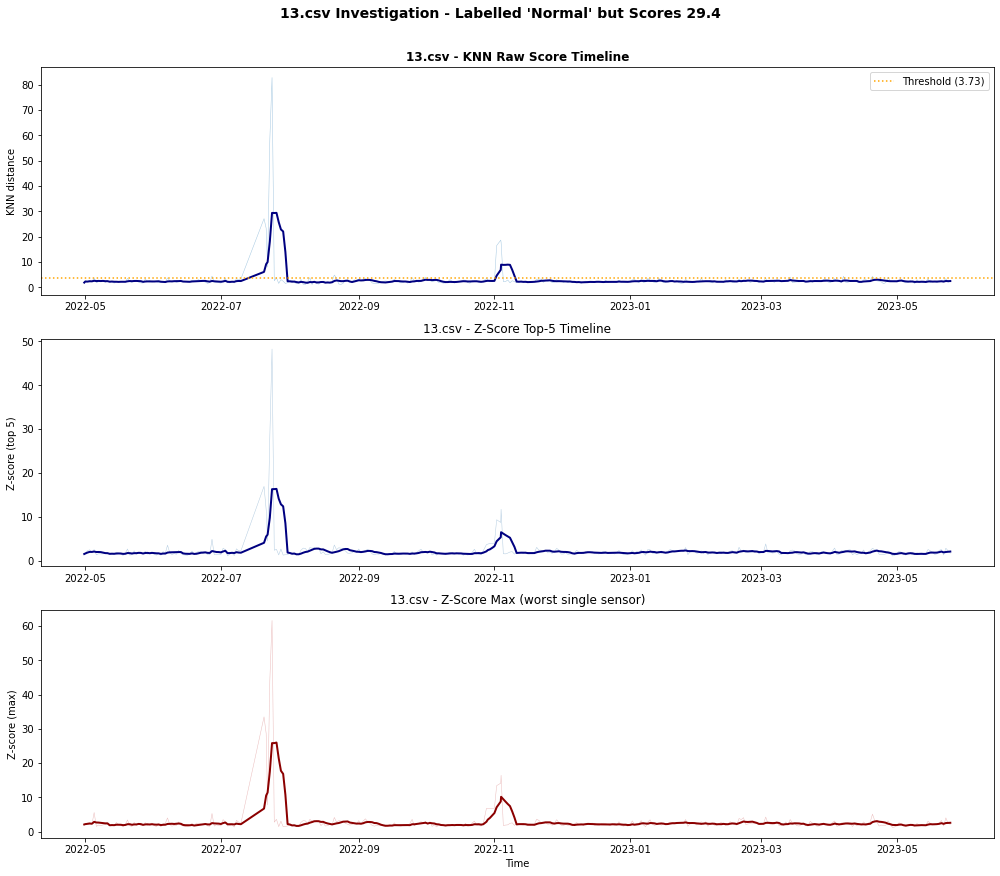

In [80]:
#spikes in 13 investigated
fdata_13 = df_all[df_all["source_file"] == "13.csv"].copy()
 
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
 
ax = axes[0]
ax.plot(fdata_13["time_stamp"].values, fdata_13["raw_score"].values, linewidth=0.5, alpha=0.4)
ax.plot(fdata_13["time_stamp"].values, fdata_13["rolling_7d"].values, linewidth=2, color="navy")
ax.axhline(best_threshold, color="orange", linestyle=":", linewidth=1.5, label=f"Threshold ({best_threshold:.2f})")
ax.set_title("13.csv - KNN Raw Score Timeline", fontweight="bold")
ax.set_ylabel("KNN distance")
ax.legend()
 
ax = axes[1]
ax.plot(fdata_13["time_stamp"].values, fdata_13["zscore_top5"].values, linewidth=0.5, alpha=0.4, color="steelblue")
ax.plot(fdata_13["time_stamp"].values, fdata_13["zscore_top5_7d"].values, linewidth=2, color="navy")
ax.set_title("13.csv - Z-Score Top-5 Timeline")
ax.set_ylabel("Z-score (top 5)")
 
ax = axes[2]
ax.plot(fdata_13["time_stamp"].values, fdata_13["zscore_max"].values, linewidth=0.5, alpha=0.4, color="indianred")
ax.plot(fdata_13["time_stamp"].values, fdata_13["zscore_max_7d"].values, linewidth=2, color="darkred")
ax.set_title("13.csv - Z-Score Max (worst single sensor)")
ax.set_ylabel("Z-score (max)")
ax.set_xlabel("Time")
 
plt.suptitle("13.csv Investigation - Labelled 'Normal' but Scores 29.4", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()
 

In [81]:
#alternative scoring metrics (last 14 days)
file_summary_v2 = []
 
for fname in df_all["source_file"].unique():
    fdata = df_all[df_all["source_file"] == fname].copy()
    label = fdata["event_label"].iloc[0]
    fault_type = fdata["fault_type"].iloc[0] if "fault_type" in fdata.columns else FAULT_MAP.get(fname, "normal")
    
    score_col = "rolling_7d"
    scores = fdata[score_col].values
    n_days = len(scores)
    
    
    days_above = (scores >= best_threshold).sum()
    frac_above = days_above / n_days if n_days > 0 else 0
    
    above = scores >= best_threshold
    longest_run = 0
    current_run = 0
    for val in above:
        if val:
            current_run += 1
            longest_run = max(longest_run, current_run)
        else:
            current_run = 0
    
    last_14 = scores[-14:] if len(scores) >= 14 else scores
    last_14_mean = last_14.mean()
    
    last_30 = scores[-30:] if len(scores) >= 30 else scores
    last_30_mean = last_30.mean()
    
    q1 = max(3, n_days // 4)
    early_mean = scores[:q1].mean()
    late_mean = scores[-q1:].mean()
    tail_ratio = late_mean / early_mean if early_mean > 0.01 else late_mean
    
    excess = np.maximum(scores - best_threshold, 0)
    area_above = excess.sum()
    
    knn_max = scores.max()
    
    file_summary_v2.append({
        "file": fname,
        "label": label,
        "fault_type": fault_type,
        "n_days": n_days,
        "knn_max": knn_max,
        "days_above": days_above,
        "frac_above": frac_above,
        "longest_run": longest_run,
        "last_14_mean": last_14_mean,
        "last_30_mean": last_30_mean,
        "tail_ratio": tail_ratio,
        "area_above": area_above,
    })
 
df_v2 = pd.DataFrame(file_summary_v2)
 

print("  SUSTAINED ELEVATION METRICS - All Files")

show_cols = ["file", "label", "fault_type", "knn_max", "days_above", "longest_run", 
             "frac_above", "last_14_mean", "tail_ratio", "area_above"]
print(df_v2.sort_values("file")[show_cols].to_string(index=False, float_format="%.2f"))
 
 
 
y_true = (df_v2["label"] == "anomaly").astype(int).values
 
candidate_metrics = {
    "Original: knn_max":         "knn_max",
    "Days above threshold":      "days_above",
    "Fraction above threshold":  "frac_above",
    "Longest consecutive run":   "longest_run",
    "Last 14-day mean":          "last_14_mean",
    "Last 30-day mean":          "last_30_mean",
    "Tail ratio (late/early)":   "tail_ratio",
    "Area above threshold":      "area_above",
}
 

print("  THRESHOLD OPTIMISATION - SUSTAINED METRICS")

 
results = []
 
for method_name, col in candidate_metrics.items():
    scores = df_v2[col].values
    
    thresholds = np.linspace(scores.min(), scores.max(), 500)
    f1s = []
    for t in thresholds:
        preds = (scores >= t).astype(int)
        f1s.append(f1_score(y_true, preds, zero_division=0))
    
    f1s = np.array(f1s)
    best_idx = f1s.argmax()
    opt_thresh = thresholds[best_idx]
    opt_f1 = f1s[best_idx]
    
    preds = (scores >= opt_thresh).astype(int)
    tp = ((preds == 1) & (y_true == 1)).sum()
    fp = ((preds == 1) & (y_true == 0)).sum()
    fn = ((preds == 0) & (y_true == 1)).sum()
    tn = ((preds == 0) & (y_true == 0)).sum()
    
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    accuracy = (tp + tn) / (tp + fp + fn + tn)
    
    results.append({
        "method": method_name, "col": col, "threshold": opt_thresh,
        "f1": opt_f1, "precision": precision, "recall": recall, 
        "accuracy": accuracy, "tp": tp, "fp": fp, "fn": fn, "tn": tn
    })
    
    print(f"\n{method_name}:")
    print(f"  Threshold: {opt_thresh:.3f}  |  F1: {opt_f1:.3f}  |  Acc: {accuracy:.1%}")
    print(f"  Precision: {precision:.3f}  |  Recall: {recall:.3f}")
    print(f"  TP={tp}  FP={fp}  FN={fn}  TN={tn}")
 
results_df = pd.DataFrame(results)
best_row = results_df.loc[results_df["f1"].idxmax()]
 

print(f"  BEST METHOD: {best_row['method']}")
print(f"  F1 = {best_row['f1']:.3f}  |  Accuracy = {best_row['accuracy']:.1%}")
print(f"  Threshold = {best_row['threshold']:.3f}")
print(f"  TP={int(best_row['tp'])}  FP={int(best_row['fp'])}  FN={int(best_row['fn'])}  TN={int(best_row['tn'])}")

 
 
 
best_col_v2 = best_row["col"]
best_thresh_v2 = best_row["threshold"]
 
df_v2["predicted"] = (df_v2[best_col_v2] >= best_thresh_v2).map({True: "ANOMALY", False: "NORMAL"})
df_v2["correct"] = (
    ((df_v2["predicted"] == "ANOMALY") & (df_v2["label"] == "anomaly")) |
    ((df_v2["predicted"] == "NORMAL") & (df_v2["label"] == "normal"))
)
 
print(f"\nPer-file predictions ({best_row['method']}, threshold={best_thresh_v2:.3f}):")

for _, row in df_v2.sort_values("file").iterrows():
    status = "Y" if row["correct"] else "N"
    print(f"  {status}  {row['file']:>8s}  true={row['label']:>8s}  pred={row['predicted']:>8s}  "
          f"{best_col_v2}={row[best_col_v2]:.3f}  ({row['fault_type']})")
 
old_correct = 18
new_correct = df_v2["correct"].sum()
total = len(df_v2)
 

print(f"  IMPROVEMENT SUMMARY")

print(f"  Previous (knn_max):     {old_correct}/{total} = {old_correct/total:.1%} accuracy, F1=0.846")
print(f"  New ({best_row['method']}): {new_correct}/{total} = {new_correct/total:.1%} accuracy, F1={best_row['f1']:.3f}")
 
if new_correct > old_correct:
    print(f"\n  IMPROVEMENT: +{new_correct - old_correct} files correctly classified")
elif new_correct == old_correct:
    print(f"\n  Same accuracy but potentially better precision/recall balance")
    
missed = df_v2[(df_v2["label"] == "anomaly") & (df_v2["predicted"] == "NORMAL")]
false_alarms = df_v2[(df_v2["label"] == "normal") & (df_v2["predicted"] == "ANOMALY")]
 
if len(missed) > 0:
    print(f"\n  Still missed:")
    for _, row in missed.iterrows():
        print(f"    {row['file']} ({row['fault_type']}) - {best_col_v2}={row[best_col_v2]:.3f}")
 
if len(false_alarms) > 0:
    print(f"\n  Still false alarms:")
    for _, row in false_alarms.iterrows():
        print(f"    {row['file']} - {best_col_v2}={row[best_col_v2]:.3f}")
 
if len(missed) == 0 and len(false_alarms) == 0:
    print(f"\n  PERFECT CLASSIFICATION - all 22 files correct")

  SUSTAINED ELEVATION METRICS - All Files
  file   label                fault_type  knn_max  days_above  longest_run  frac_above  last_14_mean  tail_ratio  area_above
 0.csv anomaly Generator bearing failure     6.78          24           12        0.06          4.25        1.89       12.18
10.csv anomaly           Gearbox failure     5.32           8            8        0.02          2.73        1.05        9.11
13.csv  normal                    normal    29.45          20           11        0.05          2.36        0.58      209.82
14.csv  normal                    normal     4.31           1            1        0.00          1.80        0.72        0.58
17.csv  normal                    normal     3.58           0            0        0.00          2.45        1.15        0.00
22.csv anomaly           Hydraulic group     9.00          13            9        0.03          3.26        1.08       34.57
24.csv  normal                    normal     3.24           0            0        0

In [82]:
#leave one out cross val




print("  LEAVE-ONE-OUT CROSS-VALIDATION - Normal Files")


loo_results = []

for held_out in NORMAL_FILES:
    train_files = [f for f in NORMAL_FILES if f != held_out]
    train_days = df_daily[df_daily["source_file"].isin(train_files)]
    
    scaler_loo = StandardScaler()
    X_train = scaler_loo.fit_transform(train_days[FEATURES])
    
    nn_loo = NearestNeighbors(n_neighbors=5, n_jobs=-1)
    nn_loo.fit(X_train)
    
    held_out_days = df_daily[df_daily["source_file"] == held_out].copy()
    X_held = scaler_loo.transform(held_out_days[FEATURES])
    dist, _ = nn_loo.kneighbors(X_held)
    held_out_days["raw_score"] = dist.mean(axis=1)
    held_out_days["rolling_7d"] = held_out_days["raw_score"].rolling(7, min_periods=1).mean()
    
    scores = held_out_days["rolling_7d"].values
    last_14 = scores[-14:] if len(scores) >= 14 else scores
    last_14_mean = last_14.mean()
    knn_max = scores.max()
    
    predicted = "ANOMALY" if last_14_mean >= best_thresh_v2 else "NORMAL"
    correct = predicted == "NORMAL"
    
    loo_results.append({
        "held_out": held_out,
        "train_files": len(train_files),
        "last_14_mean": last_14_mean,
        "knn_max": knn_max,
        "predicted": predicted,
        "correct": correct,
    })
    
    status = "Y" if correct else "N"
    print(f"  {status}  {held_out:>8s}  last_14_mean={last_14_mean:.3f}  "
          f"knn_max={knn_max:.3f}  pred={predicted}  (trained on {len(train_files)} normal files)")

loo_df = pd.DataFrame(loo_results)
loo_correct = loo_df["correct"].sum()
print(f"\nLOO result: {loo_correct}/{len(NORMAL_FILES)} normal files correctly classified as NORMAL")

print(f"\nComparison of last_14_mean scores:")
print(f"{'File':<10s} {'Original (in training)':>22s} {'LOO (held out)':>16s} {'Difference':>12s}")

for _, row in loo_df.iterrows():
    fname = row["held_out"]
    original = df_v2[df_v2["file"] == fname]["last_14_mean"].iloc[0]
    loo_score = row["last_14_mean"]
    diff = loo_score - original
    diff_pct = (diff / original * 100) if original > 0 else 0
    print(f"{fname:<10s} {original:>22.3f} {loo_score:>16.3f} {diff:>+10.3f} ({diff_pct:>+.1f}%)")




print("  FULL LOO EVALUATION - Anomaly Files Scored with LOO Models")
print("  (Each anomaly file scored with all 10 LOO models, showing mean ± std)")

anomaly_loo_scores = {f: [] for f in ANOMALY_FILES}

for held_out in NORMAL_FILES:
    train_files = [f for f in NORMAL_FILES if f != held_out]
    train_days = df_daily[df_daily["source_file"].isin(train_files)]
    
    scaler_loo = StandardScaler()
    X_train = scaler_loo.fit_transform(train_days[FEATURES])
    
    nn_loo = NearestNeighbors(n_neighbors=5, n_jobs=-1)
    nn_loo.fit(X_train)
    
    for afname in ANOMALY_FILES:
        adays = df_daily[df_daily["source_file"] == afname].copy()
        X_a = scaler_loo.transform(adays[FEATURES])
        dist, _ = nn_loo.kneighbors(X_a)
        adays["raw_score"] = dist.mean(axis=1)
        adays["rolling_7d"] = adays["raw_score"].rolling(7, min_periods=1).mean()
        
        scores = adays["rolling_7d"].values
        last_14 = scores[-14:] if len(scores) >= 14 else scores
        anomaly_loo_scores[afname].append(last_14.mean())

print(f"\n{'File':<10s} {'Fault Type':<30s} {'Mean Score':>10s} {'Std':>8s} {'Min':>8s} {'Max':>8s} {'All Detected?':>14s}")

for afname in sorted(ANOMALY_FILES):
    scores = anomaly_loo_scores[afname]
    mean_s = np.mean(scores)
    std_s = np.std(scores)
    min_s = np.min(scores)
    max_s = np.max(scores)
    all_detected = "YES" if min_s >= best_thresh_v2 else "NO (some)"
    always_missed = "NO (all)" if max_s < best_thresh_v2 else all_detected
    print(f"{afname:<10s} {FAULT_MAP[afname]:<30s} {mean_s:>10.3f} {std_s:>8.3f} {min_s:>8.3f} {max_s:>8.3f} {always_missed:>14s}")




print("  LOO VALIDATION SUMMARY")


print(f"\n  Normal files (held out of training):")
print(f"    {loo_correct}/{len(NORMAL_FILES)} still correctly classified as NORMAL")
if loo_correct == len(NORMAL_FILES):
    print(f"    All normal files remain below threshold even when held out - results are robust")
else:
    failed = loo_df[~loo_df["correct"]]
    print(f"    Files that flip to ANOMALY when held out:")
    for _, row in failed.iterrows():
        print(f"      {row['held_out']} - LOO score: {row['last_14_mean']:.3f} (threshold: {best_thresh_v2:.3f})")

stable_anomalies = sum(1 for f in ANOMALY_FILES if np.min(anomaly_loo_scores[f]) >= best_thresh_v2)
print(f"\n  Anomaly files (stable across all LOO models):")
print(f"    {stable_anomalies}/{len(ANOMALY_FILES)} detected by ALL 10 LOO models")


  LEAVE-ONE-OUT CROSS-VALIDATION - Normal Files
  Y     3.csv  last_14_mean=2.441  knn_max=7.939  pred=NORMAL  (trained on 9 normal files)
  N    13.csv  last_14_mean=3.866  knn_max=170.617  pred=ANOMALY  (trained on 9 normal files)
  N    14.csv  last_14_mean=2.590  knn_max=5.533  pred=ANOMALY  (trained on 9 normal files)
  N    17.csv  last_14_mean=3.554  knn_max=6.701  pred=ANOMALY  (trained on 9 normal files)
  N    24.csv  last_14_mean=3.284  knn_max=4.158  pred=ANOMALY  (trained on 9 normal files)
  Y    25.csv  last_14_mean=2.192  knn_max=4.006  pred=NORMAL  (trained on 9 normal files)
  N    38.csv  last_14_mean=3.485  knn_max=4.047  pred=ANOMALY  (trained on 9 normal files)
  N    69.csv  last_14_mean=3.181  knn_max=4.599  pred=ANOMALY  (trained on 9 normal files)
  Y    71.csv  last_14_mean=2.452  knn_max=3.989  pred=NORMAL  (trained on 9 normal files)
  Y    92.csv  last_14_mean=1.687  knn_max=4.711  pred=NORMAL  (trained on 9 normal files)

LOO result: 4/10 normal files cor

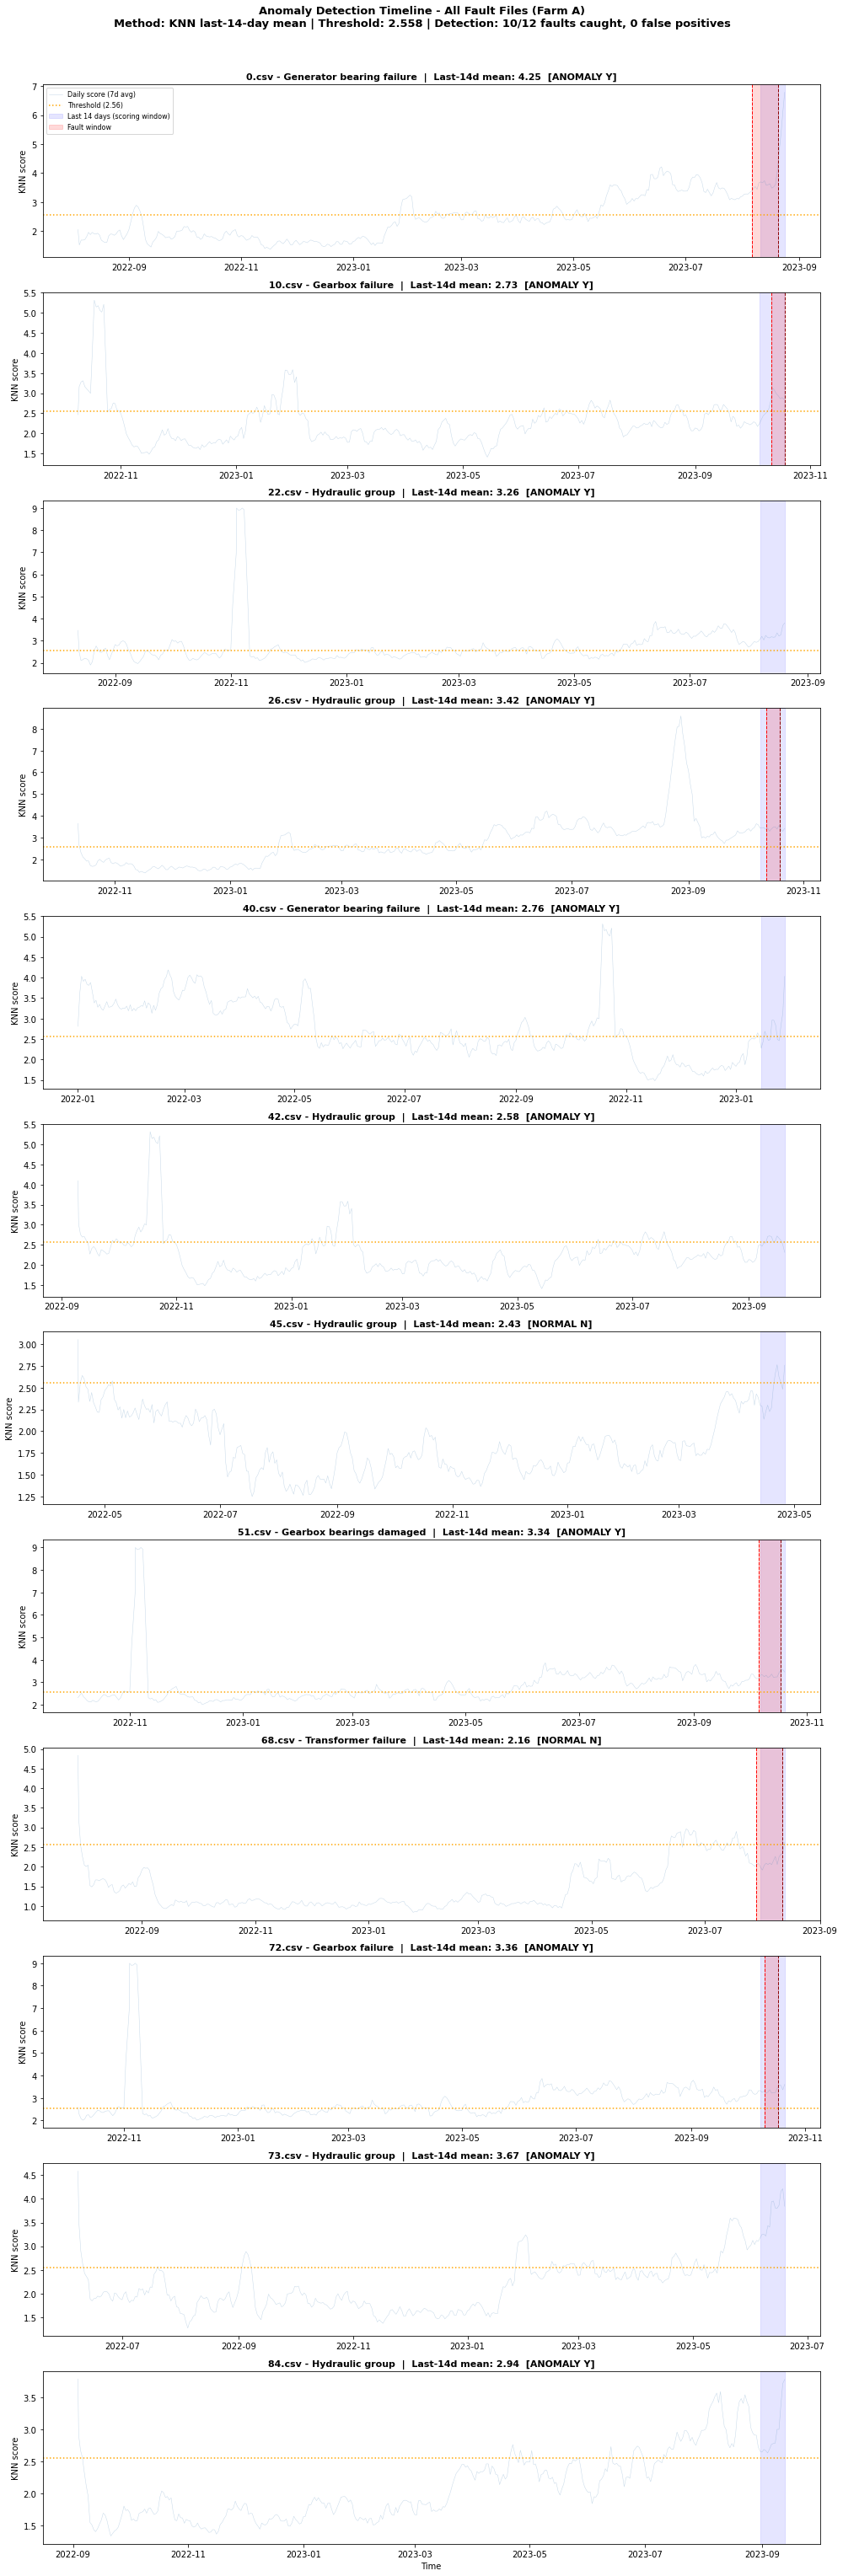

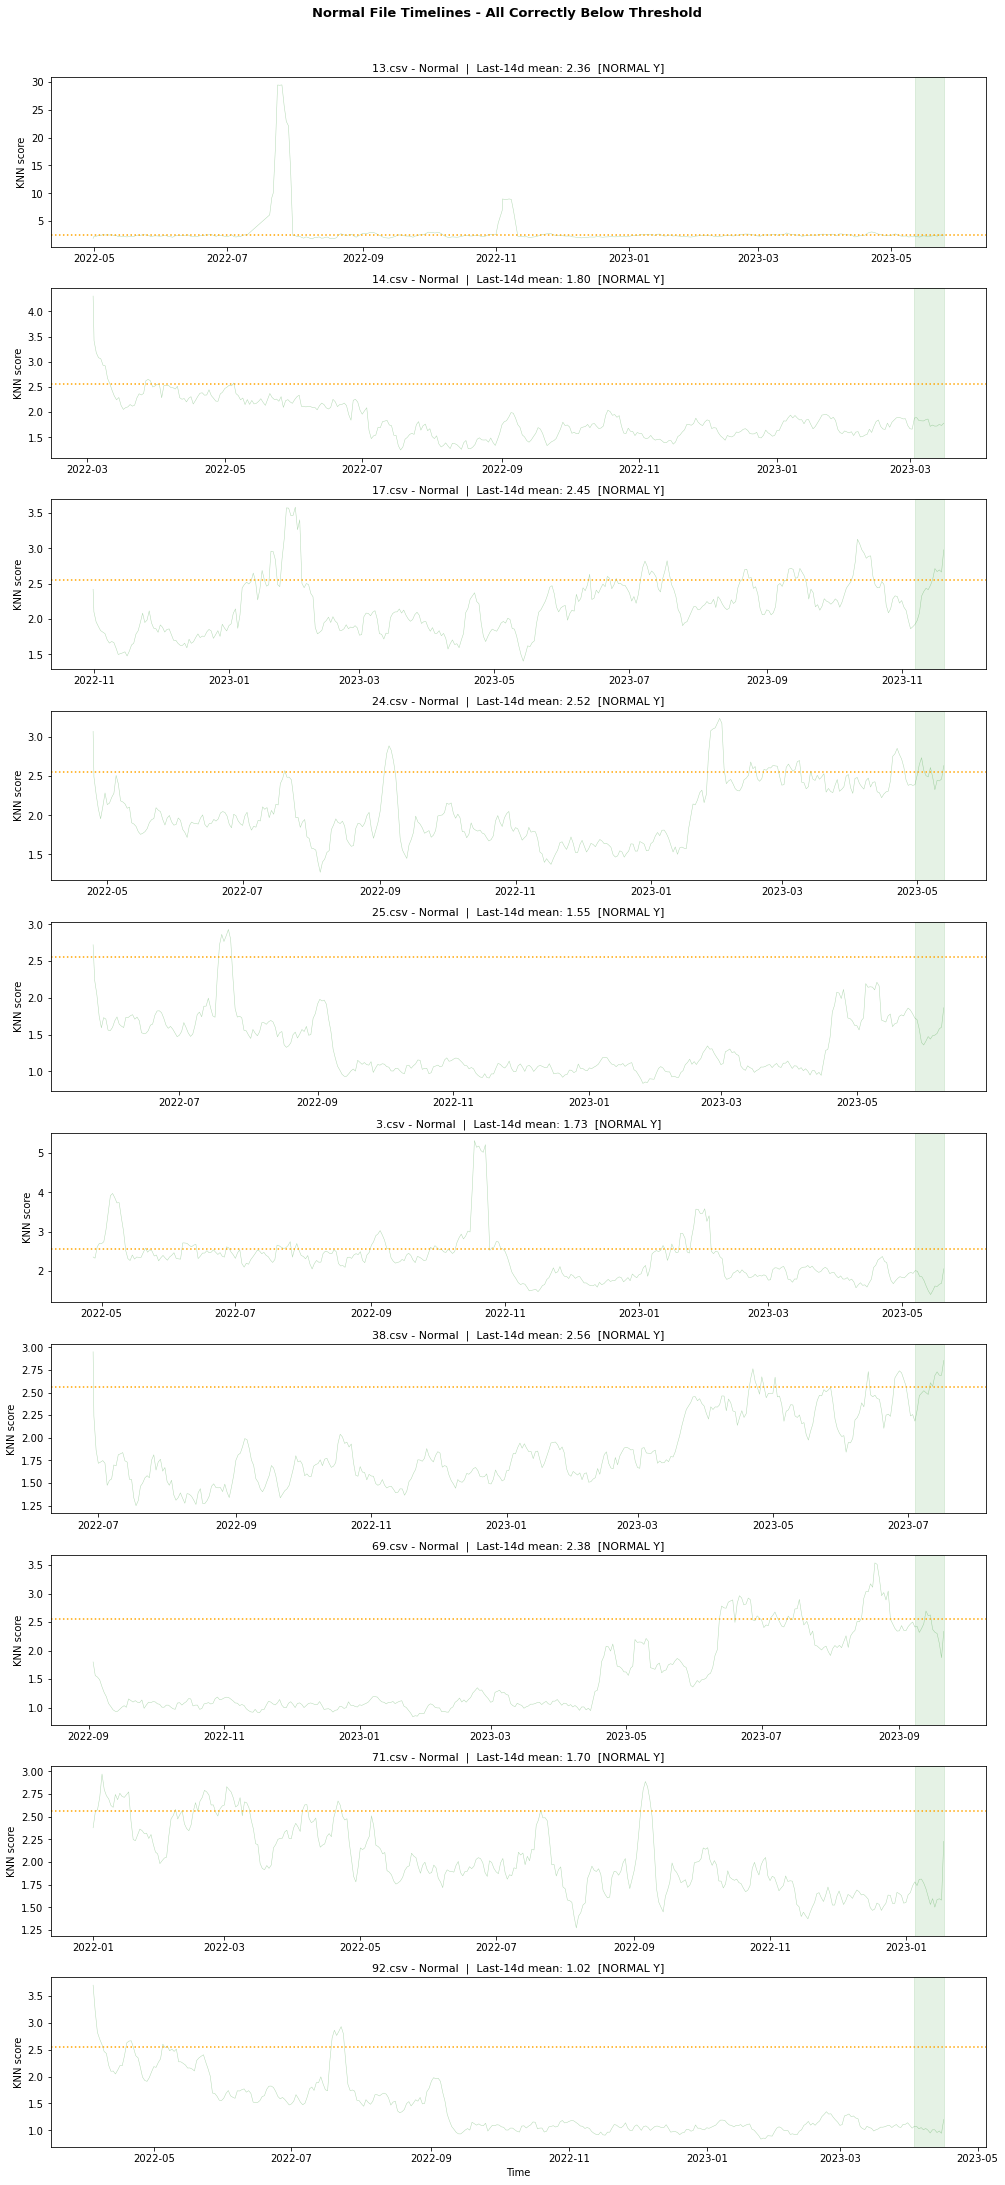

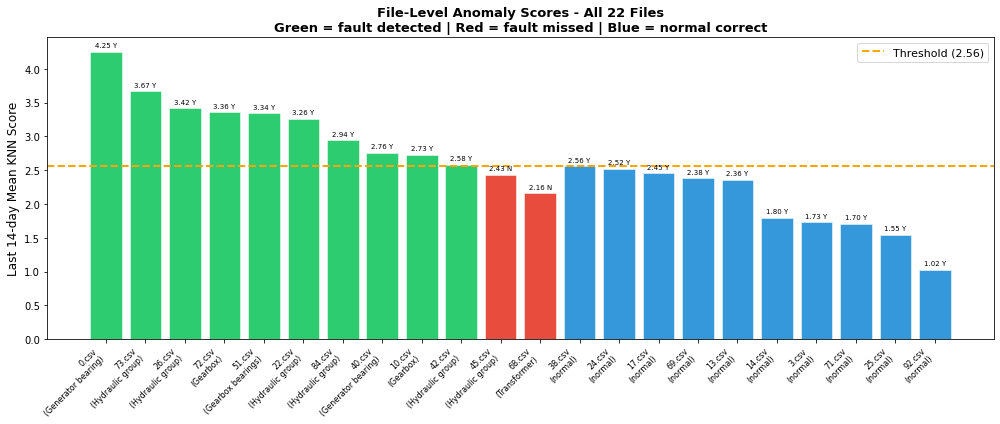

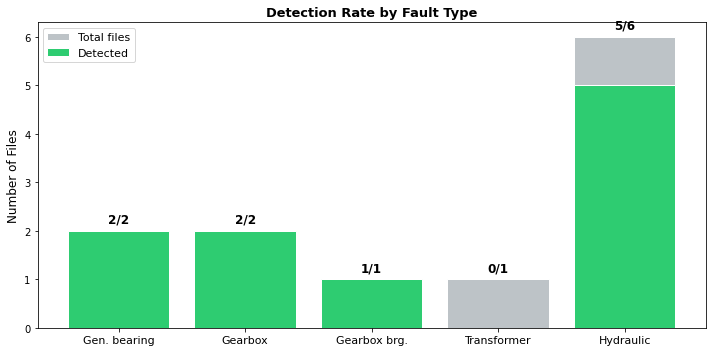

In [83]:
#all timeline plots



n_anomaly = len(ANOMALY_FILES)
fig, axes = plt.subplots(n_anomaly, 1, figsize=(14, 3.5 * n_anomaly))

for ax, fname in zip(axes, sorted(ANOMALY_FILES)):
    fdata = df_all[df_all["source_file"] == fname].copy()
    fault_type = FAULT_MAP[fname]
    
    ax.plot(fdata["time_stamp"].values, fdata["rolling_7d"].values,
            linewidth=0.5, alpha=0.3, color="steelblue", label="Daily score (7d avg)")
    
    if len(fdata) >= 14:
        last_14_start = fdata["time_stamp"].iloc[-14]
        ax.axvspan(last_14_start, fdata["time_stamp"].iloc[-1], 
                   alpha=0.1, color="blue", label="Last 14 days (scoring window)")
    
    ax.axhline(best_thresh_v2, color="orange", linestyle=":", linewidth=1.5, 
               label=f"Threshold ({best_thresh_v2:.2f})")
    
    if fname in FAULT_WINDOWS:
        fs = pd.to_datetime(FAULT_WINDOWS[fname][0])
        fe = pd.to_datetime(FAULT_WINDOWS[fname][1])
        ax.axvline(fs, color="red", linestyle="--", linewidth=1)
        ax.axvline(fe, color="darkred", linestyle="--", linewidth=1)
        ax.axvspan(fs, fe, alpha=0.15, color="red", label="Fault window")
    
    file_row = df_v2[df_v2["file"] == fname].iloc[0]
    pred = file_row["predicted"]
    correct = file_row["correct"]
    score = file_row["last_14_mean"]
    marker = "Y" if correct else "N"
    
    ax.set_title(f"{fname} - {fault_type}  |  Last-14d mean: {score:.2f}  [{pred} {marker}]", 
                 fontsize=11, fontweight="bold")
    ax.set_ylabel("KNN score")
    
    if ax == axes[0]:
        ax.legend(loc="upper left", fontsize=8)

axes[-1].set_xlabel("Time")
fig.suptitle("Anomaly Detection Timeline - All Fault Files (Farm A)\n"
             f"Method: KNN last-14-day mean | Threshold: {best_thresh_v2:.3f} | "
             f"Detection: 10/12 faults caught, 0 false positives",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()



n_normal = len(NORMAL_FILES)
fig, axes = plt.subplots(n_normal, 1, figsize=(14, 3 * n_normal))

for ax, fname in zip(axes, sorted(NORMAL_FILES)):
    fdata = df_all[df_all["source_file"] == fname].copy()
    
    if len(fdata) == 0:
        ax.set_title(f"{fname} - Normal [NO DATA]")
        continue
    
    ax.plot(fdata["time_stamp"].values, fdata["rolling_7d"].values,
            linewidth=0.5, alpha=0.3, color="green")
    
    if len(fdata) >= 14:
        last_14_start = fdata["time_stamp"].iloc[-14]
        ax.axvspan(last_14_start, fdata["time_stamp"].iloc[-1],
                   alpha=0.1, color="green")
    
    ax.axhline(best_thresh_v2, color="orange", linestyle=":", linewidth=1.5)
    
    file_row = df_v2[df_v2["file"] == fname].iloc[0]
    score = file_row["last_14_mean"]
    
    ax.set_title(f"{fname} - Normal  |  Last-14d mean: {score:.2f}  [NORMAL Y]", fontsize=11)
    ax.set_ylabel("KNN score")

axes[-1].set_xlabel("Time")
fig.suptitle("Normal File Timelines - All Correctly Below Threshold",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()



fig, ax = plt.subplots(figsize=(14, 6))

df_plot = df_v2.sort_values(["label", "last_14_mean"], ascending=[True, False]).copy()
df_plot = pd.concat([
    df_plot[df_plot["label"] == "anomaly"].sort_values("last_14_mean", ascending=False),
    df_plot[df_plot["label"] == "normal"].sort_values("last_14_mean", ascending=False)
])

x = range(len(df_plot))
colors = []
for _, row in df_plot.iterrows():
    if row["label"] == "anomaly" and row["correct"]:
        colors.append("#2ecc71")
    elif row["label"] == "anomaly" and not row["correct"]:
        colors.append("#e74c3c")
    elif row["label"] == "normal" and row["correct"]:
        colors.append("#3498db")
    else:
        colors.append("#e67e22")

bars = ax.bar(x, df_plot["last_14_mean"].values, color=colors, edgecolor="white", linewidth=0.5)

ax.axhline(best_thresh_v2, color="orange", linestyle="--", linewidth=2, label=f"Threshold ({best_thresh_v2:.2f})")

labels = []
for _, row in df_plot.iterrows():
    if row["label"] == "anomaly":
        ft_short = row["fault_type"].replace(" failure", "").replace(" damaged", "")
        labels.append(f"{row['file']}\n({ft_short})")
    else:
        labels.append(f"{row['file']}\n(normal)")

ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=8, rotation=45, ha="right")
ax.set_ylabel("Last 14-day Mean KNN Score", fontsize=12)
ax.set_title("File-Level Anomaly Scores - All 22 Files\n"
             "Green = fault detected | Red = fault missed | Blue = normal correct",
             fontsize=13, fontweight="bold")
ax.legend(fontsize=11)

for bar, (_, row) in zip(bars, df_plot.iterrows()):
    height = bar.get_height()
    marker = "Y" if row["correct"] else "N"
    ax.text(bar.get_x() + bar.get_width()/2., height + 0.05,
            f"{height:.2f} {marker}", ha="center", va="bottom", fontsize=7)

plt.tight_layout()
plt.show()



fault_types = ["Generator bearing failure", "Gearbox failure", 
               "Gearbox bearings damaged", "Transformer failure", "Hydraulic group"]

fig, ax = plt.subplots(figsize=(10, 5))

detected_counts = []
total_counts = []
for ft in fault_types:
    ft_files = df_v2[df_v2["fault_type"] == ft]
    total_counts.append(len(ft_files))
    detected_counts.append((ft_files["predicted"] == "ANOMALY").sum())

x = range(len(fault_types))
short_names = ["Gen. bearing", "Gearbox", "Gearbox brg.", "Transformer", "Hydraulic"]

bars_total = ax.bar(x, total_counts, color="#bdc3c7", edgecolor="white", label="Total files")
bars_detected = ax.bar(x, detected_counts, color="#2ecc71", edgecolor="white", label="Detected")

ax.set_xticks(x)
ax.set_xticklabels(short_names, fontsize=11)
ax.set_ylabel("Number of Files", fontsize=12)
ax.set_title("Detection Rate by Fault Type", fontsize=13, fontweight="bold")
ax.legend(fontsize=11)

for i, (det, tot) in enumerate(zip(detected_counts, total_counts)):
    ax.text(i, tot + 0.1, f"{det}/{tot}", ha="center", va="bottom", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()




In [84]:
#equivalent sensors between Farm A and B 
FEATURE_MAP = {
    "active_power":       ("power_29_avg",          "power_62_avg"),
    "reactive_power":     ("reactive_power_27_avg", "reactive_power_11_avg"),
    "wind_speed":         ("wind_speed_3_avg",      "wind_speed_61_avg"),
    "ambient_temp":       ("sensor_0_avg",          "sensor_8_avg"),
    "gen_bearing_temp_1": ("sensor_14_avg",         "sensor_32_avg"),
    "gen_bearing_temp_2": ("sensor_13_avg",         "sensor_33_avg"),
    "gearbox_bearing_temp":("sensor_11_avg",        "sensor_34_avg"),
    "gearbox_oil_temp":   ("sensor_12_avg",         "sensor_39_avg"),
    "transformer_L1":     ("sensor_38_avg",         "sensor_41_avg"),
    "transformer_L2":     ("sensor_39_avg",         "sensor_43_avg"),
    "transformer_L3":     ("sensor_40_avg",         "sensor_45_avg"),
    "generator_rpm":      ("sensor_18_avg",         "sensor_19_avg"),
    "gearbox_rpm":        ("sensor_52_avg",         "sensor_20_avg"),
    "grid_frequency":     ("sensor_26_avg",         "sensor_23_avg"),
}
 
GENERIC_NAMES = list(FEATURE_MAP.keys())
FARM_A_COLS = [FEATURE_MAP[g][0] for g in GENERIC_NAMES]
FARM_B_COLS = [FEATURE_MAP[g][1] for g in GENERIC_NAMES]
 
print(f"Mapped features: {len(GENERIC_NAMES)}")
for g in GENERIC_NAMES:
    a, b = FEATURE_MAP[g]
    print(f"  {g:<25s}  A: {a:<25s}  B: {b}")

Mapped features: 14
  active_power               A: power_29_avg               B: power_62_avg
  reactive_power             A: reactive_power_27_avg      B: reactive_power_11_avg
  wind_speed                 A: wind_speed_3_avg           B: wind_speed_61_avg
  ambient_temp               A: sensor_0_avg               B: sensor_8_avg
  gen_bearing_temp_1         A: sensor_14_avg              B: sensor_32_avg
  gen_bearing_temp_2         A: sensor_13_avg              B: sensor_33_avg
  gearbox_bearing_temp       A: sensor_11_avg              B: sensor_34_avg
  gearbox_oil_temp           A: sensor_12_avg              B: sensor_39_avg
  transformer_L1             A: sensor_38_avg              B: sensor_41_avg
  transformer_L2             A: sensor_39_avg              B: sensor_43_avg
  transformer_L3             A: sensor_40_avg              B: sensor_45_avg
  generator_rpm              A: sensor_18_avg              B: sensor_19_avg
  gearbox_rpm                A: sensor_52_avg             

In [85]:
#farm a daily mapped farme
df_a_mapped = merged[FARM_A_COLS + ["event_label", "source_file", "time_stamp"]].copy()
df_a_mapped.columns = GENERIC_NAMES + ["event_label", "source_file", "time_stamp"]
 
df_a_mapped = df_a_mapped[df_a_mapped["wind_speed"] >= 0]
df_a_mapped = df_a_mapped.dropna().reset_index(drop=True)
df_a_mapped["time_stamp"] = pd.to_datetime(df_a_mapped["time_stamp"])
df_a_mapped["date"] = df_a_mapped["time_stamp"].dt.date
 
agg_dict = {feat: ["mean", "std"] for feat in GENERIC_NAMES}
agg_dict["event_label"] = "first"
agg_dict["time_stamp"] = "first"
 
df_a_daily = df_a_mapped.groupby(["source_file", "date"]).agg(agg_dict).reset_index()
 
new_cols = []
for col in df_a_daily.columns:
    if col[1] == "":
        new_cols.append(col[0])
    elif col[1] == "first":
        new_cols.append(col[0])
    else:
        new_cols.append(f"{col[0]}_{col[1]}")
df_a_daily.columns = new_cols
 
std_cols = [c for c in df_a_daily.columns if c.endswith("_std")]
df_a_daily[std_cols] = df_a_daily[std_cols].fillna(0)
 
FEATURES = [c for c in df_a_daily.columns if c.endswith(("_mean", "_std"))]
 
print(f"\nFarm A daily: {len(df_a_daily):,} rows, {len(FEATURES)} features")
print(f"Normal files: {df_a_daily[df_a_daily['event_label'] == 'normal']['source_file'].nunique()}")


Farm A daily: 8,389 rows, 28 features
Normal files: 10


In [86]:
#farm b daily mapped frame + anomaly breakdown
df_b_mapped = merged_b[FARM_B_COLS + ["event_label", "source_file", "time_stamp"]].copy()
df_b_mapped.columns = GENERIC_NAMES + ["event_label", "source_file", "time_stamp"]
 
df_b_mapped = df_b_mapped[df_b_mapped["wind_speed"] >= 0]
df_b_mapped = df_b_mapped[df_b_mapped["gearbox_bearing_temp"] >= 0]
df_b_mapped = df_b_mapped[df_b_mapped["gearbox_oil_temp"] >= 0]
df_b_mapped = df_b_mapped[df_b_mapped["gen_bearing_temp_2"] >= 0]
df_b_mapped = df_b_mapped.dropna().reset_index(drop=True)
df_b_mapped["time_stamp"] = pd.to_datetime(df_b_mapped["time_stamp"])
df_b_mapped["date"] = df_b_mapped["time_stamp"].dt.date
 
agg_dict_b = {feat: ["mean", "std"] for feat in GENERIC_NAMES}
agg_dict_b["event_label"] = "first"
agg_dict_b["time_stamp"] = "first"
 
df_b_daily = df_b_mapped.groupby(["source_file", "date"]).agg(agg_dict_b).reset_index()
 
new_cols_b = []
for col in df_b_daily.columns:
    if col[1] == "":
        new_cols_b.append(col[0])
    elif col[1] == "first":
        new_cols_b.append(col[0])
    else:
        new_cols_b.append(f"{col[0]}_{col[1]}")
df_b_daily.columns = new_cols_b
 
std_cols_b = [c for c in df_b_daily.columns if c.endswith("_std")]
df_b_daily[std_cols_b] = df_b_daily[std_cols_b].fillna(0)
 
FEATURES_B = [c for c in df_b_daily.columns if c.endswith(("_mean", "_std"))]
assert FEATURES == FEATURES_B, f"Feature mismatch: {set(FEATURES) ^ set(FEATURES_B)}"
 
print(f"Farm B daily: {len(df_b_daily):,} rows, {len(FEATURES_B)} features")
print(f"Farm B files: {df_b_daily['source_file'].nunique()}")
print(f"\nFarm B file breakdown:")
print(df_b_daily.groupby(["source_file", "event_label"]).size().reset_index(name="days").to_string(index=False))

Farm B daily: 5,983 rows, 28 features
Farm B files: 15

Farm B file breakdown:
source_file event_label  days
     19.csv     anomaly   392
      2.csv      normal   382
     21.csv      normal   369
     23.csv      normal   380
     27.csv     anomaly   435
     34.csv     anomaly   393
     52.csv      normal   384
     53.csv     anomaly   408
      7.csv     anomaly   403
     74.csv      normal   388
     77.csv     anomaly   430
     82.csv      normal   383
     83.csv      normal   463
     86.csv      normal   386
     87.csv      normal   387


In [87]:
#train on Farm A normal, score on Farm B
normal_a = df_a_daily[df_a_daily["event_label"] == "normal"]
print(f"Training on Farm A normal data: {len(normal_a):,} days from {normal_a['source_file'].nunique()} files")
 
scaler_cross = StandardScaler()
X_train = scaler_cross.fit_transform(normal_a[FEATURES])
 
nn_cross = NearestNeighbors(n_neighbors=5, n_jobs=-1)
nn_cross.fit(X_train)
 
b_results = []
 
for fname in df_b_daily["source_file"].unique():
    file_days = df_b_daily[df_b_daily["source_file"] == fname].copy()
    X_file = scaler_cross.transform(file_days[FEATURES])
    dist, _ = nn_cross.kneighbors(X_file)
    file_days["raw_score"] = dist.mean(axis=1)
    file_days["rolling_7d"] = file_days["raw_score"].rolling(7, min_periods=1).mean()
    b_results.append(file_days)
 
df_b_scored = pd.concat(b_results, ignore_index=True)
print(f"Scored {df_b_scored['source_file'].nunique()} Farm B files")

Training on Farm A normal data: 3,834 days from 10 files
Scored 15 Farm B files


In [88]:
#file level cross farm results
b_file_summary = []
 
for fname in df_b_scored["source_file"].unique():
    fdata = df_b_scored[df_b_scored["source_file"] == fname]
    label = fdata["event_label"].iloc[0]
    scores = fdata["rolling_7d"].values
    
    b_file_summary.append({
        "file": fname,
        "label": label,
        "n_days": len(fdata),
        "knn_max": scores.max(),
        "knn_mean": scores.mean(),
        "last_14_mean": scores[-14:].mean() if len(scores) >= 14 else scores.mean(),
    })
 
df_b_files = pd.DataFrame(b_file_summary)
 
y_true_b = (df_b_files["label"] == "anomaly").astype(int).values
 

print("  CROSS-FARM RESULTS - Farm A model applied to Farm B")

 
for method_name, col in [("Max score (7d rolling)", "knn_max"), ("Last-14-day mean", "last_14_mean")]:
    scores = df_b_files[col].values
    
    thresholds = np.linspace(scores.min(), scores.max(), 500)
    f1s = [f1_score(y_true_b, (scores >= t).astype(int), zero_division=0) for t in thresholds]
    f1s = np.array(f1s)
    best_idx = f1s.argmax()
    opt_thresh = thresholds[best_idx]
    opt_f1 = f1s[best_idx]
    
    preds = (scores >= opt_thresh).astype(int)
    tp = ((preds == 1) & (y_true_b == 1)).sum()
    fp = ((preds == 1) & (y_true_b == 0)).sum()
    fn = ((preds == 0) & (y_true_b == 1)).sum()
    tn = ((preds == 0) & (y_true_b == 0)).sum()
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    accuracy = (tp + tn) / len(y_true_b)
    
    print(f"\n{method_name}:")
    print(f"  Optimal threshold: {opt_thresh:.3f}")
    print(f"  Accuracy: {accuracy:.1%}  |  F1: {opt_f1:.3f}")
    print(f"  Precision: {precision:.3f}  |  Recall: {recall:.3f}")
    print(f"  TP={tp}  FP={fp}  FN={fn}  TN={tn}")
 



 
farm_a_thresh = 3.731
preds_transfer = (df_b_files["knn_max"] >= farm_a_thresh).astype(int)
tp_t = ((preds_transfer == 1) & (y_true_b == 1)).sum()
fp_t = ((preds_transfer == 1) & (y_true_b == 0)).sum()
fn_t = ((preds_transfer == 0) & (y_true_b == 1)).sum()
tn_t = ((preds_transfer == 0) & (y_true_b == 0)).sum()
acc_t = (tp_t + tn_t) / len(y_true_b)
f1_t = f1_score(y_true_b, preds_transfer, zero_division=0)
prec_t = tp_t / (tp_t + fp_t) if (tp_t + fp_t) > 0 else 0
rec_t = tp_t / (tp_t + fn_t) if (tp_t + fn_t) > 0 else 0
 
print(f"  Accuracy: {acc_t:.1%}  |  F1: {f1_t:.3f}")
print(f"  Precision: {prec_t:.3f}  |  Recall: {rec_t:.3f}")
print(f"  TP={tp_t}  FP={fp_t}  FN={fn_t}  TN={tn_t}")
 
print(f"\nPer-file predictions (Farm A threshold = {farm_a_thresh}):")

for _, row in df_b_files.sort_values("file").iterrows():
    pred = "ANOMALY" if row["knn_max"] >= farm_a_thresh else "NORMAL"
    correct = (pred == "ANOMALY" and row["label"] == "anomaly") or (pred == "NORMAL" and row["label"] == "normal")
    status = "Y" if correct else "N"
    print(f"  {status}  {row['file']:>8s}  true={row['label']:>8s}  pred={pred:>8s}  "
          f"max_score={row['knn_max']:.3f}")

  CROSS-FARM RESULTS - Farm A model applied to Farm B

Max score (7d rolling):
  Optimal threshold: 306.565
  Accuracy: 46.7%  |  F1: 0.600
  Precision: 0.429  |  Recall: 1.000
  TP=6  FP=8  FN=0  TN=1

Last-14-day mean:
  Optimal threshold: 260.960
  Accuracy: 60.0%  |  F1: 0.625
  Precision: 0.500  |  Recall: 0.833
  TP=5  FP=5  FN=1  TN=4
  Accuracy: 40.0%  |  F1: 0.571
  Precision: 0.400  |  Recall: 1.000
  TP=6  FP=9  FN=0  TN=0

Per-file predictions (Farm A threshold = 3.731):
  Y    19.csv  true= anomaly  pred= ANOMALY  max_score=328.639
  N     2.csv  true=  normal  pred= ANOMALY  max_score=393.505
  N    21.csv  true=  normal  pred= ANOMALY  max_score=304.623
  N    23.csv  true=  normal  pred= ANOMALY  max_score=386.475
  Y    27.csv  true= anomaly  pred= ANOMALY  max_score=1273.966
  Y    34.csv  true= anomaly  pred= ANOMALY  max_score=325.156
  N    52.csv  true=  normal  pred= ANOMALY  max_score=325.156
  Y    53.csv  true= anomaly  pred= ANOMALY  max_score=327.656
  Y    

  FEATURE COMPARISON - Farm A Normal vs Farm B Normal

Feature                       Farm A Mean  Farm B Mean       Diff    Ratio
active_power_mean                    0.29         0.36      +0.08     1.27
reactive_power_mean                  0.25         0.01      -0.24     0.05 <<<
wind_speed_mean                      6.18         8.84      +2.66     1.43
ambient_temp_mean                   19.87        12.66      -7.21     0.64
gen_bearing_temp_1_mean             47.01        55.01      +8.00     1.17
gen_bearing_temp_2_mean             43.46        49.87      +6.41     1.15
gearbox_bearing_temp_mean           51.60        60.17      +8.57     1.17
gearbox_oil_temp_mean               47.60        54.29      +6.69     1.14
transformer_L1_mean                 65.54        54.08     -11.45     0.83
transformer_L2_mean                 71.97        55.67     -16.31     0.77
transformer_L3_mean                 70.54        54.04     -16.50     0.77
generator_rpm_mean                1069.49

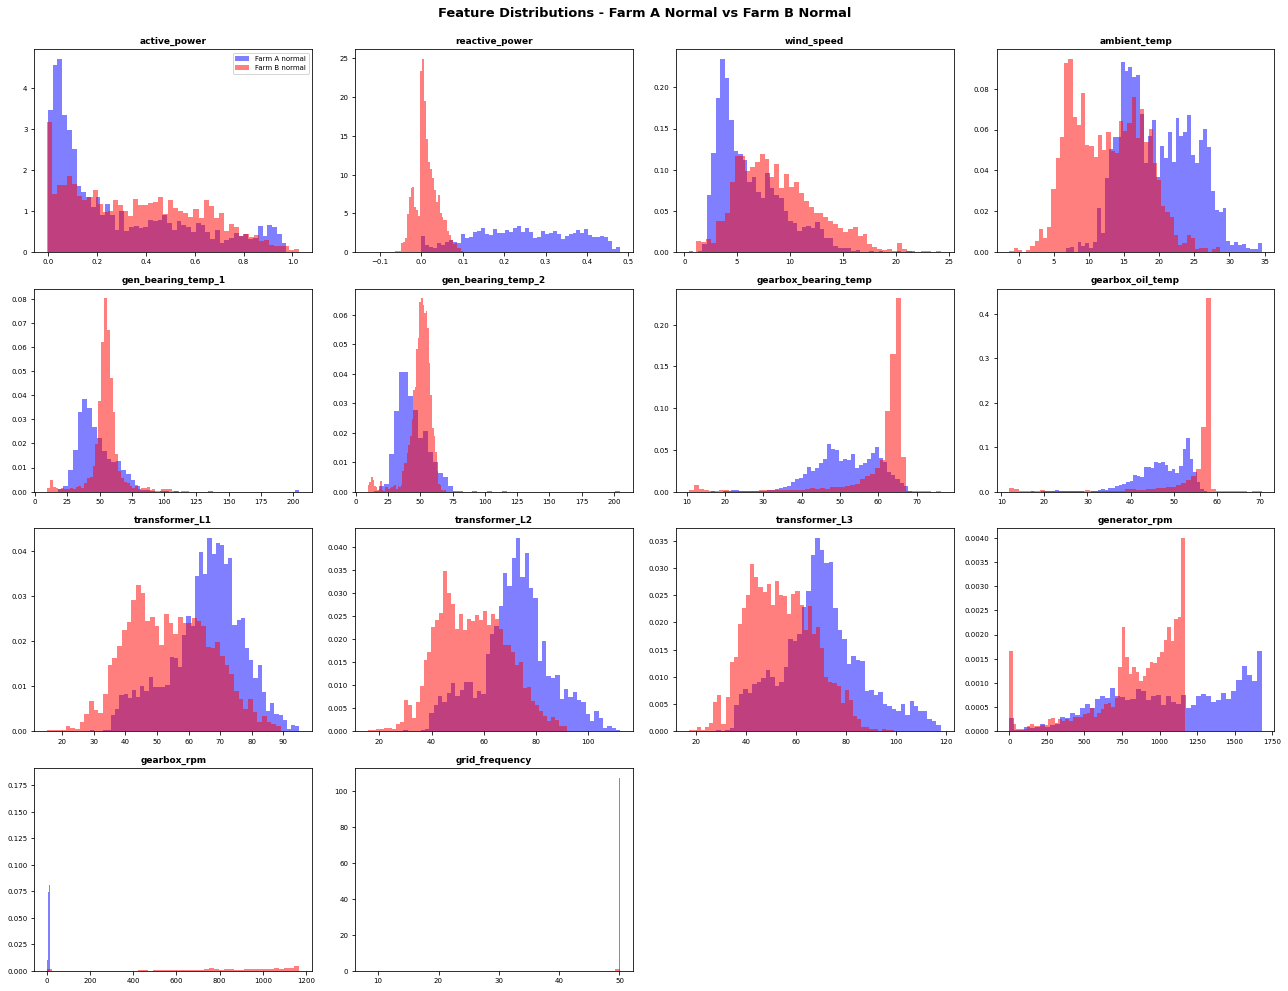

In [89]:
#raw feature distribution comparison

print("  FEATURE COMPARISON - Farm A Normal vs Farm B Normal")

 
normal_a_daily = df_a_daily[df_a_daily["event_label"] == "normal"]
normal_b_daily = df_b_daily[df_b_daily["event_label"] == "normal"]
 
mean_features = [c for c in FEATURES if c.endswith("_mean")]
 
print(f"\n{'Feature':<28s} {'Farm A Mean':>12s} {'Farm B Mean':>12s} {'Diff':>10s} {'Ratio':>8s}")

for feat in mean_features:
    a_mean = normal_a_daily[feat].mean()
    b_mean = normal_b_daily[feat].mean()
    diff = b_mean - a_mean
    ratio = b_mean / a_mean if abs(a_mean) > 0.001 else float('inf')
    flag = " <<<" if abs(ratio - 1) > 0.5 or abs(diff) > 50 else ""
    print(f"{feat:<28s} {a_mean:>12.2f} {b_mean:>12.2f} {diff:>+10.2f} {ratio:>8.2f}{flag}")
 
 
 
std_features = [c for c in FEATURES if c.endswith("_std")]
 
print(f"\n{'Feature':<28s} {'Farm A Std':>12s} {'Farm B Std':>12s} {'Ratio':>8s}")

for feat in std_features:
    a_std = normal_a_daily[feat].mean()
    b_std = normal_b_daily[feat].mean()
    ratio = b_std / a_std if abs(a_std) > 0.001 else float('inf')
    flag = " <<<" if abs(ratio - 1) > 1 else ""
    print(f"{feat:<28s} {a_std:>12.2f} {b_std:>12.2f} {ratio:>8.2f}{flag}")
 
 
 
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
axes = axes.flatten()
 
for i, feat in enumerate(mean_features[:14]):
    ax = axes[i]
    a_vals = normal_a_daily[feat].dropna()
    b_vals = normal_b_daily[feat].dropna()
    
    ax.hist(a_vals, bins=50, alpha=0.5, color="blue", label="Farm A normal", density=True)
    ax.hist(b_vals, bins=50, alpha=0.5, color="red", label="Farm B normal", density=True)
    
    name = feat.replace("_mean", "")
    ax.set_title(name, fontsize=9, fontweight="bold")
    ax.tick_params(labelsize=7)
    if i == 0:
        ax.legend(fontsize=7)
 
for j in range(len(mean_features), len(axes)):
    axes[j].set_visible(False)
 
plt.suptitle("Feature Distributions - Farm A Normal vs Farm B Normal\n",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

In [90]:
#Removed mismatch features
FEATURE_MAP_v2 = {
    "active_power":       ("power_29_avg",          "power_62_avg"),
    "wind_speed":         ("wind_speed_3_avg",      "wind_speed_61_avg"),
    "ambient_temp":       ("sensor_0_avg",          "sensor_8_avg"),
    "gen_bearing_temp_1": ("sensor_14_avg",         "sensor_32_avg"),
    "gen_bearing_temp_2": ("sensor_13_avg",         "sensor_33_avg"),
    "gearbox_bearing_temp":("sensor_11_avg",        "sensor_34_avg"),
    "gearbox_oil_temp":   ("sensor_12_avg",         "sensor_39_avg"),
    "transformer_L1":     ("sensor_38_avg",         "sensor_41_avg"),
    "transformer_L2":     ("sensor_39_avg",         "sensor_43_avg"),
    "transformer_L3":     ("sensor_40_avg",         "sensor_45_avg"),
    "generator_rpm":      ("sensor_18_avg",         "sensor_19_avg"),
}
 
GENERIC_v2 = list(FEATURE_MAP_v2.keys())
FARM_A_COLS_v2 = [FEATURE_MAP_v2[g][0] for g in GENERIC_v2]
FARM_B_COLS_v2 = [FEATURE_MAP_v2[g][1] for g in GENERIC_v2]
 
print(f"Using {len(GENERIC_v2)} matched features (removed gearbox_rpm, grid_frequency, reactive_power)")

Using 11 matched features (removed gearbox_rpm, grid_frequency, reactive_power)


In [91]:
#new farm a mapped daily frame
df_a2 = merged[FARM_A_COLS_v2 + ["event_label", "source_file", "time_stamp"]].copy()
df_a2.columns = GENERIC_v2 + ["event_label", "source_file", "time_stamp"]
df_a2 = df_a2[df_a2["wind_speed"] >= 0]
df_a2 = df_a2.dropna().reset_index(drop=True)
df_a2["time_stamp"] = pd.to_datetime(df_a2["time_stamp"])
df_a2["date"] = df_a2["time_stamp"].dt.date
 
agg_a2 = {feat: ["mean", "std"] for feat in GENERIC_v2}
agg_a2["event_label"] = "first"
agg_a2["time_stamp"] = "first"
 
df_a2_daily = df_a2.groupby(["source_file", "date"]).agg(agg_a2).reset_index()
 
new_cols = []
for col in df_a2_daily.columns:
    if col[1] == "":
        new_cols.append(col[0])
    elif col[1] == "first":
        new_cols.append(col[0])
    else:
        new_cols.append(f"{col[0]}_{col[1]}")
df_a2_daily.columns = new_cols
 
std_cols = [c for c in df_a2_daily.columns if c.endswith("_std")]
df_a2_daily[std_cols] = df_a2_daily[std_cols].fillna(0)
 
FEATS_v2 = [c for c in df_a2_daily.columns if c.endswith(("_mean", "_std"))]

In [92]:
#farm B mapped daily frame
df_b2 = merged_b[FARM_B_COLS_v2 + ["event_label", "source_file", "time_stamp"]].copy()
df_b2.columns = GENERIC_v2 + ["event_label", "source_file", "time_stamp"]
df_b2 = df_b2[df_b2["wind_speed"] >= 0]
df_b2 = df_b2[df_b2["gearbox_bearing_temp"] >= 0]
df_b2 = df_b2[df_b2["gearbox_oil_temp"] >= 0]
df_b2 = df_b2[df_b2["gen_bearing_temp_2"] >= 0]
df_b2 = df_b2.dropna().reset_index(drop=True)
df_b2["time_stamp"] = pd.to_datetime(df_b2["time_stamp"])
df_b2["date"] = df_b2["time_stamp"].dt.date
 
agg_b2 = {feat: ["mean", "std"] for feat in GENERIC_v2}
agg_b2["event_label"] = "first"
agg_b2["time_stamp"] = "first"
 
df_b2_daily = df_b2.groupby(["source_file", "date"]).agg(agg_b2).reset_index()
 
new_cols_b = []
for col in df_b2_daily.columns:
    if col[1] == "":
        new_cols_b.append(col[0])
    elif col[1] == "first":
        new_cols_b.append(col[0])
    else:
        new_cols_b.append(f"{col[0]}_{col[1]}")
df_b2_daily.columns = new_cols_b
 
std_cols_b = [c for c in df_b2_daily.columns if c.endswith("_std")]
df_b2_daily[std_cols_b] = df_b2_daily[std_cols_b].fillna(0)
 
FEATS_B_v2 = [c for c in df_b2_daily.columns if c.endswith(("_mean", "_std"))]
assert FEATS_v2 == FEATS_B_v2, f"Feature mismatch!"
 
print(f"Farm A daily: {len(df_a2_daily):,} rows, {len(FEATS_v2)} features")
print(f"Farm B daily: {len(df_b2_daily):,} rows, {len(FEATS_B_v2)} features")
 

Farm A daily: 8,389 rows, 22 features
Farm B daily: 5,983 rows, 22 features


In [93]:
#attempt 2 train farm A test b
normal_a2 = df_a2_daily[df_a2_daily["event_label"] == "normal"]
print(f"\nTraining on Farm A normal: {len(normal_a2):,} days")
 
scaler_v2 = StandardScaler()
X_train_v2 = scaler_v2.fit_transform(normal_a2[FEATS_v2])
 
nn_v2 = NearestNeighbors(n_neighbors=5, n_jobs=-1)
nn_v2.fit(X_train_v2)
 
b2_results = []
for fname in df_b2_daily["source_file"].unique():
    file_days = df_b2_daily[df_b2_daily["source_file"] == fname].copy()
    X_file = scaler_v2.transform(file_days[FEATS_v2])
    dist, _ = nn_v2.kneighbors(X_file)
    file_days["raw_score"] = dist.mean(axis=1)
    file_days["rolling_7d"] = file_days["raw_score"].rolling(7, min_periods=1).mean()
    b2_results.append(file_days)
 
df_b2_scored = pd.concat(b2_results, ignore_index=True)


Training on Farm A normal: 3,834 days


In [94]:
#results v2
b2_file_summary = []
for fname in df_b2_scored["source_file"].unique():
    fdata = df_b2_scored[df_b2_scored["source_file"] == fname]
    label = fdata["event_label"].iloc[0]
    scores = fdata["rolling_7d"].values
    b2_file_summary.append({
        "file": fname,
        "label": label,
        "n_days": len(fdata),
        "knn_max": scores.max(),
        "last_14_mean": scores[-14:].mean() if len(scores) >= 14 else scores.mean(),
    })
 
df_b2_files = pd.DataFrame(b2_file_summary)
y_true_b2 = (df_b2_files["label"] == "anomaly").astype(int).values
 

print("  CROSS-FARM RESULTS v2 - 11 features, mismatches removed")

 
for method_name, col in [("Max score (7d rolling)", "knn_max"), ("Last-14-day mean", "last_14_mean")]:
    scores = df_b2_files[col].values
    thresholds = np.linspace(scores.min(), scores.max(), 500)
    f1s = [f1_score(y_true_b2, (scores >= t).astype(int), zero_division=0) for t in thresholds]
    f1s = np.array(f1s)
    best_idx = f1s.argmax()
    opt_thresh = thresholds[best_idx]
    opt_f1 = f1s[best_idx]
    
    preds = (scores >= opt_thresh).astype(int)
    tp = ((preds == 1) & (y_true_b2 == 1)).sum()
    fp = ((preds == 1) & (y_true_b2 == 0)).sum()
    fn = ((preds == 0) & (y_true_b2 == 1)).sum()
    tn = ((preds == 0) & (y_true_b2 == 0)).sum()
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    accuracy = (tp + tn) / len(y_true_b2)
    
    print(f"\n{method_name}:")
    print(f"  Optimal threshold: {opt_thresh:.3f}")
    print(f"  Accuracy: {accuracy:.1%}  |  F1: {opt_f1:.3f}")
    print(f"  Precision: {precision:.3f}  |  Recall: {recall:.3f}")
    print(f"  TP={tp}  FP={fp}  FN={fn}  TN={tn}")
 

print(f"  PER-FILE PREDICTIONS")

 
scores_max = df_b2_files["knn_max"].values
thresholds = np.linspace(scores_max.min(), scores_max.max(), 500)
f1s = [f1_score(y_true_b2, (scores_max >= t).astype(int), zero_division=0) for t in thresholds]
best_thresh_b2 = thresholds[np.argmax(f1s)]
 
print(f"\nMax score method (threshold={best_thresh_b2:.3f}):")

for _, row in df_b2_files.sort_values("file").iterrows():
    pred = "ANOMALY" if row["knn_max"] >= best_thresh_b2 else "NORMAL"
    correct = (pred == "ANOMALY" and row["label"] == "anomaly") or \
              (pred == "NORMAL" and row["label"] == "normal")
    status = "Y" if correct else "N"
    print(f"  {status}  {row['file']:>8s}  true={row['label']:>8s}  pred={pred:>8s}  "
          f"max={row['knn_max']:.3f}  last14={row['last_14_mean']:.3f}")

  CROSS-FARM RESULTS v2 - 11 features, mismatches removed

Max score (7d rolling):
  Optimal threshold: 4.362
  Accuracy: 40.0%  |  F1: 0.571
  Precision: 0.400  |  Recall: 1.000
  TP=6  FP=9  FN=0  TN=0

Last-14-day mean:
  Optimal threshold: 2.682
  Accuracy: 40.0%  |  F1: 0.571
  Precision: 0.400  |  Recall: 1.000
  TP=6  FP=9  FN=0  TN=0
  PER-FILE PREDICTIONS

Max score method (threshold=4.362):
  Y    19.csv  true= anomaly  pred= ANOMALY  max=6.476  last14=3.944
  N     2.csv  true=  normal  pred= ANOMALY  max=6.291  last14=3.491
  N    21.csv  true=  normal  pred= ANOMALY  max=6.207  last14=2.973
  N    23.csv  true=  normal  pred= ANOMALY  max=6.713  last14=3.077
  Y    27.csv  true= anomaly  pred= ANOMALY  max=6.505  last14=3.423
  Y    34.csv  true= anomaly  pred= ANOMALY  max=6.159  last14=2.682
  N    52.csv  true=  normal  pred= ANOMALY  max=6.159  last14=2.756
  Y    53.csv  true= anomaly  pred= ANOMALY  max=6.713  last14=3.789
  Y     7.csv  true= anomaly  pred= ANOMALY 

In [95]:
#remove uncsacerry features KNN with only Farm B data
REMOVE_B = [
    "sensor_4_avg",
    "sensor_10_avg",
    "sensor_21_avg",
    "sensor_0_avg",
    "sensor_1_avg",
    "sensor_2_avg",
    "sensor_3_avg",
    "wind_speed_60_avg",
    "sensor_6_avg",
]
 
 
all_avg_b = [c for c in merged_b.columns if c.endswith("_avg") and c not in REMOVE_B]
print(f"Farm B features: {len(all_avg_b)}")
 
 
df_b_full = merged_b[all_avg_b + ["event_label", "source_file", "time_stamp"]].copy()
df_b_full = df_b_full.dropna().reset_index(drop=True)
df_b_full["time_stamp"] = pd.to_datetime(df_b_full["time_stamp"])
 
df_b_full = df_b_full[df_b_full["wind_speed_61_avg"] >= 0]
df_b_full = df_b_full[df_b_full["wind_speed_59_avg"] >= 0]
df_b_full = df_b_full[df_b_full["sensor_34_avg"] >= 0]
df_b_full = df_b_full[df_b_full["sensor_39_avg"] >= 0]
df_b_full = df_b_full[df_b_full["sensor_33_avg"] >= 0]
df_b_full = df_b_full.reset_index(drop=True)
 
df_b_full["date"] = df_b_full["time_stamp"].dt.date
 
agg_dict = {feat: ["mean", "std"] for feat in all_avg_b}
agg_dict["event_label"] = "first"
agg_dict["time_stamp"] = "first"
 
df_b_daily = df_b_full.groupby(["source_file", "date"]).agg(agg_dict).reset_index()
 
new_cols = []
for col in df_b_daily.columns:
    if col[1] == "":
        new_cols.append(col[0])
    elif col[1] == "first":
        new_cols.append(col[0])
    else:
        new_cols.append(f"{col[0]}_{col[1]}")
df_b_daily.columns = new_cols
 
std_cols = [c for c in df_b_daily.columns if c.endswith("_std")]
df_b_daily[std_cols] = df_b_daily[std_cols].fillna(0)
 
FEATURES_B = [c for c in df_b_daily.columns if c.endswith(("_mean", "_std"))]
 
print(f"Daily rows: {len(df_b_daily):,}")
print(f"Features per day: {len(FEATURES_B)}")
 
 
NORMAL_B = sorted(df_b_daily[df_b_daily["event_label"] == "normal"]["source_file"].unique())
ANOMALY_B = sorted(df_b_daily[df_b_daily["event_label"] == "anomaly"]["source_file"].unique())
print(f"\nNormal files ({len(NORMAL_B)}): {NORMAL_B}")
print(f"Anomaly files ({len(ANOMALY_B)}): {ANOMALY_B}")
 
 
normal_b_daily = df_b_daily[df_b_daily["event_label"] == "normal"]
print(f"\nTraining on {len(normal_b_daily):,} normal days from {len(NORMAL_B)} files")
 
scaler_b = StandardScaler()
X_normal_b = scaler_b.fit_transform(normal_b_daily[FEATURES_B])
 
nn_b = NearestNeighbors(n_neighbors=5, n_jobs=-1)
nn_b.fit(X_normal_b)

Farm B features: 54
Daily rows: 5,983
Features per day: 108

Normal files (9): ['2.csv', '21.csv', '23.csv', '52.csv', '74.csv', '82.csv', '83.csv', '86.csv', '87.csv']
Anomaly files (6): ['19.csv', '27.csv', '34.csv', '53.csv', '7.csv', '77.csv']

Training on 3,522 normal days from 9 files


NearestNeighbors(n_jobs=-1)

  FARM B RESULTS - Self-trained KNN, 55 features

Max score (7d rolling):
  Optimal threshold: 5.275
  Accuracy: 40.0%  |  F1: 0.571
  Precision: 0.400  |  Recall: 1.000
  TP=6  FP=9  FN=0  TN=0

Last-14-day mean:
  Optimal threshold: 3.808
  Accuracy: 86.7%  |  F1: 0.800
  Precision: 1.000  |  Recall: 0.667
  TP=4  FP=0  FN=2  TN=9
  PER-FILE PREDICTIONS (max score, threshold=5.275)
  Y    19.csv  true= anomaly  pred= ANOMALY  max=5.638  last14=5.083
  N     2.csv  true=  normal  pred= ANOMALY  max=5.275  last14=2.556
  N    21.csv  true=  normal  pred= ANOMALY  max=5.300  last14=2.958
  N    23.csv  true=  normal  pred= ANOMALY  max=6.789  last14=2.673
  Y    27.csv  true= anomaly  pred= ANOMALY  max=17.078  last14=4.044
  Y    34.csv  true= anomaly  pred= ANOMALY  max=6.677  last14=3.227
  N    52.csv  true=  normal  pred= ANOMALY  max=6.677  last14=2.369
  Y    53.csv  true= anomaly  pred= ANOMALY  max=6.789  last14=4.972
  Y     7.csv  true= anomaly  pred= ANOMALY  max=5.275  last

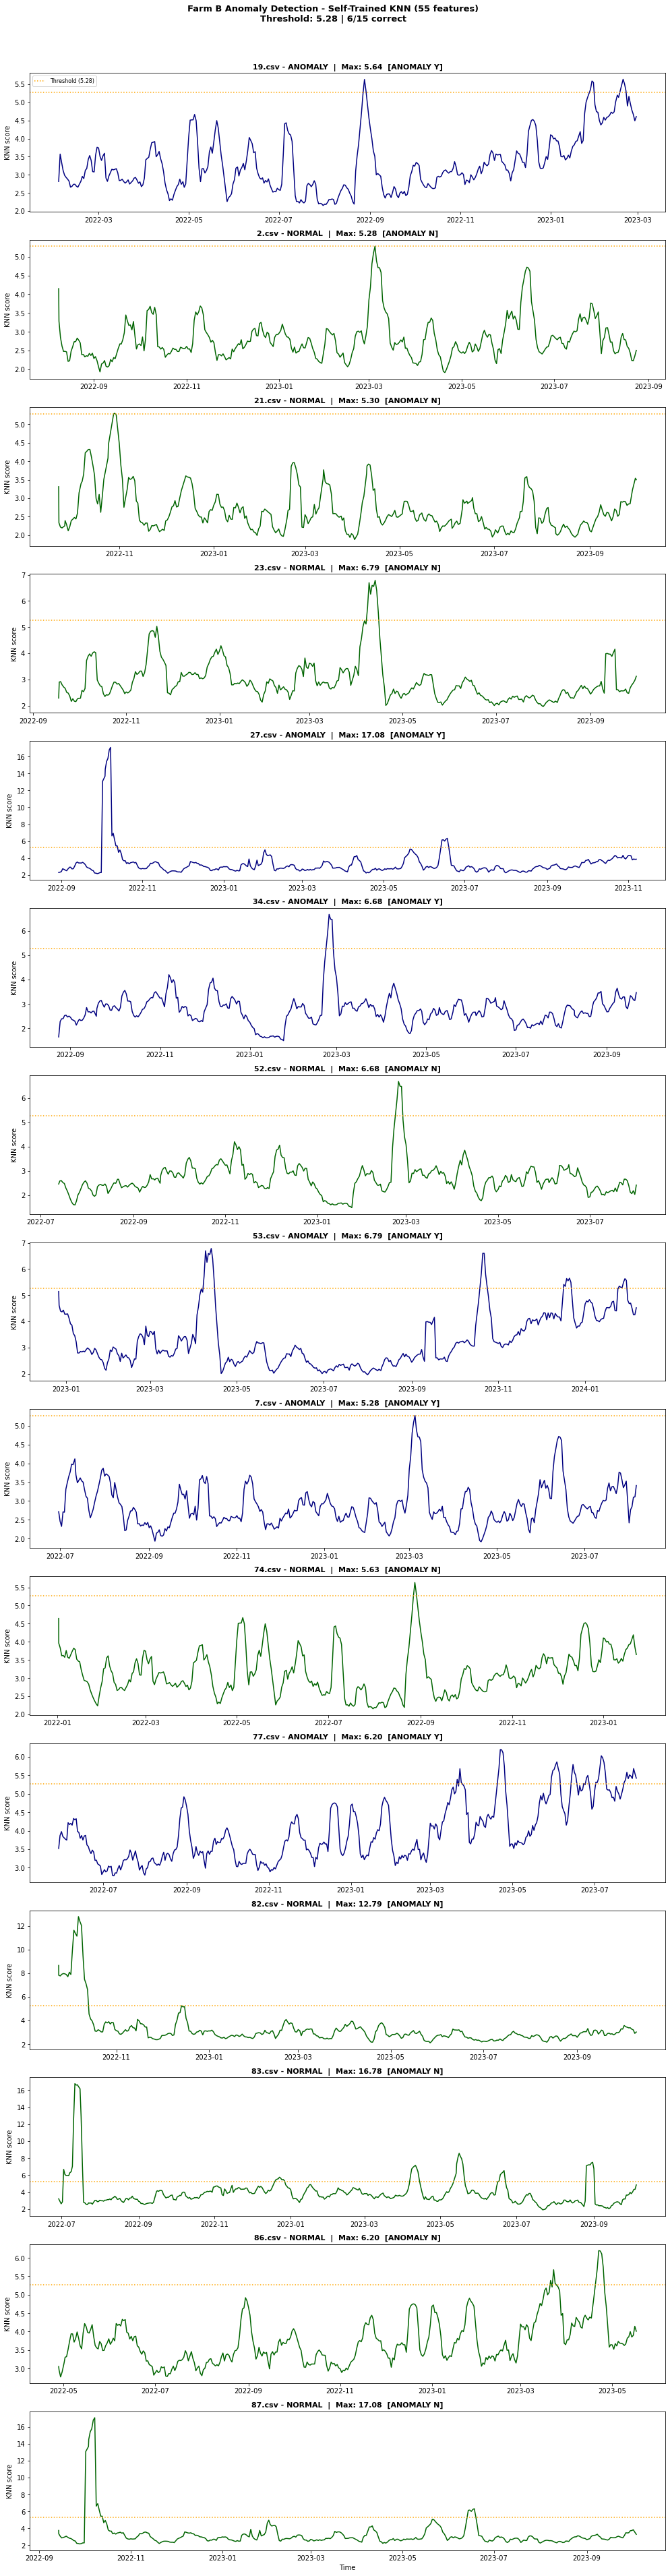

In [96]:
#farm B files and timelines
b_all_results = []
 
for fname in df_b_daily["source_file"].unique():
    file_days = df_b_daily[df_b_daily["source_file"] == fname].copy()
    X_file = scaler_b.transform(file_days[FEATURES_B])
    dist, _ = nn_b.kneighbors(X_file)
    file_days["raw_score"] = dist.mean(axis=1)
    file_days["rolling_7d"] = file_days["raw_score"].rolling(7, min_periods=1).mean()
    b_all_results.append(file_days)
 
df_b_scored = pd.concat(b_all_results, ignore_index=True)
 
 
b_file_summary = []
 
for fname in df_b_scored["source_file"].unique():
    fdata = df_b_scored[df_b_scored["source_file"] == fname]
    label = fdata["event_label"].iloc[0]
    scores = fdata["rolling_7d"].values
    
    b_file_summary.append({
        "file": fname,
        "label": label,
        "n_days": len(fdata),
        "knn_max": scores.max(),
        "last_14_mean": scores[-14:].mean() if len(scores) >= 14 else scores.mean(),
    })
 
df_b_files = pd.DataFrame(b_file_summary)
y_true_b = (df_b_files["label"] == "anomaly").astype(int).values
 
 

print("  FARM B RESULTS - Self-trained KNN, 55 features")

 
for method_name, col in [("Max score (7d rolling)", "knn_max"), ("Last-14-day mean", "last_14_mean")]:
    scores = df_b_files[col].values
    thresholds = np.linspace(scores.min(), scores.max(), 500)
    f1s = [f1_score(y_true_b, (scores >= t).astype(int), zero_division=0) for t in thresholds]
    f1s = np.array(f1s)
    best_idx = f1s.argmax()
    opt_thresh = thresholds[best_idx]
    opt_f1 = f1s[best_idx]
    
    preds = (scores >= opt_thresh).astype(int)
    tp = ((preds == 1) & (y_true_b == 1)).sum()
    fp = ((preds == 1) & (y_true_b == 0)).sum()
    fn = ((preds == 0) & (y_true_b == 1)).sum()
    tn = ((preds == 0) & (y_true_b == 0)).sum()
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    accuracy = (tp + tn) / len(y_true_b)
    
    print(f"\n{method_name}:")
    print(f"  Optimal threshold: {opt_thresh:.3f}")
    print(f"  Accuracy: {accuracy:.1%}  |  F1: {opt_f1:.3f}")
    print(f"  Precision: {precision:.3f}  |  Recall: {recall:.3f}")
    print(f"  TP={tp}  FP={fp}  FN={fn}  TN={tn}")
 
 
scores_max = df_b_files["knn_max"].values
thresholds = np.linspace(scores_max.min(), scores_max.max(), 500)
f1s = [f1_score(y_true_b, (scores_max >= t).astype(int), zero_division=0) for t in thresholds]
best_thresh_b = thresholds[np.argmax(f1s)]
 
df_b_files["predicted"] = (df_b_files["knn_max"] >= best_thresh_b).map({True: "ANOMALY", False: "NORMAL"})
df_b_files["correct"] = (
    ((df_b_files["predicted"] == "ANOMALY") & (df_b_files["label"] == "anomaly")) |
    ((df_b_files["predicted"] == "NORMAL") & (df_b_files["label"] == "normal"))
)
 

print(f"  PER-FILE PREDICTIONS (max score, threshold={best_thresh_b:.3f})")

for _, row in df_b_files.sort_values("file").iterrows():
    status = "Y" if row["correct"] else "N"
    print(f"  {status}  {row['file']:>8s}  true={row['label']:>8s}  pred={row['predicted']:>8s}  "
          f"max={row['knn_max']:.3f}  last14={row['last_14_mean']:.3f}")
 
correct_count = df_b_files["correct"].sum()
total_count = len(df_b_files)
print(f"\nOverall: {correct_count}/{total_count} = {correct_count/total_count:.1%} accuracy")
 
 
farm_b_files_sorted = sorted(df_b_scored["source_file"].unique())
n_files = len(farm_b_files_sorted)
 
fig, axes = plt.subplots(n_files, 1, figsize=(14, 3.5 * n_files))
if n_files == 1:
    axes = [axes]
 
for ax, fname in zip(axes, farm_b_files_sorted):
    fdata = df_b_scored[df_b_scored["source_file"] == fname].copy()
    label = fdata["event_label"].iloc[0]
    
    color = "navy" if label == "anomaly" else "darkgreen"
    ax.plot(fdata["time_stamp"].values, fdata["rolling_7d"].values,
            linewidth=1.5, color=color)
    
    ax.axhline(best_thresh_b, color="orange", linestyle=":", linewidth=1.5,
               label=f"Threshold ({best_thresh_b:.2f})")
    
    file_row = df_b_files[df_b_files["file"] == fname].iloc[0]
    pred = file_row["predicted"]
    correct = file_row["correct"]
    marker = "Y" if correct else "N"
    
    ax.set_title(f"{fname} - {label.upper()}  |  Max: {file_row['knn_max']:.2f}  [{pred} {marker}]",
                 fontsize=11, fontweight="bold")
    ax.set_ylabel("KNN score")
    
    if ax == axes[0]:
        ax.legend(loc="upper left", fontsize=8)
 
axes[-1].set_xlabel("Time")
fig.suptitle(f"Farm B Anomaly Detection - Self-Trained KNN (55 features)\n"
             f"Threshold: {best_thresh_b:.2f} | {correct_count}/{total_count} correct",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

In [97]:
#Farm A rolling window
windows = [7, 14, 21, 30]
 

print("  FARM A - Max Score with Different Rolling Windows")

 
for w in windows:
    file_scores = []
    
    for fname in df_all["source_file"].unique():
        fdata = df_all[df_all["source_file"] == fname].copy()
        label = fdata["event_label"].iloc[0]
        fault_type = FAULT_MAP.get(fname, "normal")
        
        rolling = fdata["raw_score"].rolling(w, min_periods=1).mean()
        max_score = rolling.max()
        
        file_scores.append({
            "file": fname,
            "label": label,
            "fault_type": fault_type,
            "knn_max": max_score,
        })
    
    df_scores = pd.DataFrame(file_scores)
    y_true = (df_scores["label"] == "anomaly").astype(int).values
    
    scores = df_scores["knn_max"].values
    thresholds = np.linspace(scores.min(), scores.max(), 500)
    f1s = [f1_score(y_true, (scores >= t).astype(int), zero_division=0) for t in thresholds]
    f1s = np.array(f1s)
    best_thresh = thresholds[f1s.argmax()]
    best_f1 = f1s.max()
    
    preds = (scores >= best_thresh).astype(int)
    tp = ((preds == 1) & (y_true == 1)).sum()
    fp = ((preds == 1) & (y_true == 0)).sum()
    fn = ((preds == 0) & (y_true == 1)).sum()
    tn = ((preds == 0) & (y_true == 0)).sum()
    acc = (tp + tn) / len(y_true)
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    
    print(f"  {w}-DAY ROLLING WINDOW")
    
    print(f"  Threshold: {best_thresh:.3f}  |  Accuracy: {acc:.1%}  |  F1: {best_f1:.3f}")
    print(f"  Precision: {prec:.3f}  |  Recall: {rec:.3f}")
    print(f"  TP={tp}  FP={fp}  FN={fn}  TN={tn}")
    
    print(f"\n  Per-file predictions:")
    for _, row in df_scores.sort_values("file").iterrows():
        pred = "ANOMALY" if row["knn_max"] >= best_thresh else "NORMAL"
        correct = (pred == "ANOMALY" and row["label"] == "anomaly") or \
                  (pred == "NORMAL" and row["label"] == "normal")
        status = "Y" if correct else "N"
        print(f"    {status}  {row['file']:>8s}  true={row['label']:>8s}  pred={pred:>8s}  "
              f"max={row['knn_max']:.3f}  ({row['fault_type']})")

  FARM A - Max Score with Different Rolling Windows
  7-DAY ROLLING WINDOW
  Threshold: 3.728  |  Accuracy: 81.8%  |  F1: 0.846
  Precision: 0.786  |  Recall: 0.917
  TP=11  FP=3  FN=1  TN=7

  Per-file predictions:
    Y     0.csv  true= anomaly  pred= ANOMALY  max=6.784  (Generator bearing failure)
    Y    10.csv  true= anomaly  pred= ANOMALY  max=5.316  (Gearbox failure)
    N    13.csv  true=  normal  pred= ANOMALY  max=29.448  (normal)
    N    14.csv  true=  normal  pred= ANOMALY  max=4.307  (normal)
    Y    17.csv  true=  normal  pred=  NORMAL  max=3.584  (normal)
    Y    22.csv  true= anomaly  pred= ANOMALY  max=9.000  (Hydraulic group)
    Y    24.csv  true=  normal  pred=  NORMAL  max=3.239  (normal)
    Y    25.csv  true=  normal  pred=  NORMAL  max=2.931  (normal)
    Y    26.csv  true= anomaly  pred= ANOMALY  max=8.592  (Hydraulic group)
    N     3.csv  true=  normal  pred= ANOMALY  max=5.316  (normal)
    Y    38.csv  true=  normal  pred=  NORMAL  max=2.952  (normal)


In [98]:
#Farm B rolling window
windows = [7, 14, 21, 30]
 

print("  FARM B - Max Score with Different Rolling Windows")

 
for w in windows:
    file_scores = []
    
    for fname in df_b_scored["source_file"].unique():
        fdata = df_b_scored[df_b_scored["source_file"] == fname].copy()
        label = fdata["event_label"].iloc[0]
        
        rolling = fdata["raw_score"].rolling(w, min_periods=1).mean()
        max_score = rolling.max()
        
        file_scores.append({
            "file": fname,
            "label": label,
            "knn_max": max_score,
        })
    
    df_scores = pd.DataFrame(file_scores)
    y_true = (df_scores["label"] == "anomaly").astype(int).values
    
    scores = df_scores["knn_max"].values
    thresholds = np.linspace(scores.min(), scores.max(), 500)
    f1s = [f1_score(y_true, (scores >= t).astype(int), zero_division=0) for t in thresholds]
    f1s = np.array(f1s)
    best_thresh = thresholds[f1s.argmax()]
    best_f1 = f1s.max()
    
    preds = (scores >= best_thresh).astype(int)
    tp = ((preds == 1) & (y_true == 1)).sum()
    fp = ((preds == 1) & (y_true == 0)).sum()
    fn = ((preds == 0) & (y_true == 1)).sum()
    tn = ((preds == 0) & (y_true == 0)).sum()
    acc = (tp + tn) / len(y_true)
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    
    print(f"  {w}-DAY ROLLING WINDOW")
    
    print(f"  Threshold: {best_thresh:.3f}  |  Accuracy: {acc:.1%}  |  F1: {best_f1:.3f}")
    print(f"  Precision: {prec:.3f}  |  Recall: {rec:.3f}")
    print(f"  TP={tp}  FP={fp}  FN={fn}  TN={tn}")
    
    print(f"\n  Per-file predictions:")
    for _, row in df_scores.sort_values("file").iterrows():
        pred = "ANOMALY" if row["knn_max"] >= best_thresh else "NORMAL"
        correct = (pred == "ANOMALY" and row["label"] == "anomaly") or \
                  (pred == "NORMAL" and row["label"] == "normal")
        status = "Y" if correct else "N"
        print(f"    {status}  {row['file']:>8s}  true={row['label']:>8s}  pred={pred:>8s}  "
              f"max={row['knn_max']:.3f}")
 

  FARM B - Max Score with Different Rolling Windows
  7-DAY ROLLING WINDOW
  Threshold: 5.275  |  Accuracy: 40.0%  |  F1: 0.571
  Precision: 0.400  |  Recall: 1.000
  TP=6  FP=9  FN=0  TN=0

  Per-file predictions:
    Y    19.csv  true= anomaly  pred= ANOMALY  max=5.638
    N     2.csv  true=  normal  pred= ANOMALY  max=5.275
    N    21.csv  true=  normal  pred= ANOMALY  max=5.300
    N    23.csv  true=  normal  pred= ANOMALY  max=6.789
    Y    27.csv  true= anomaly  pred= ANOMALY  max=17.078
    Y    34.csv  true= anomaly  pred= ANOMALY  max=6.677
    N    52.csv  true=  normal  pred= ANOMALY  max=6.677
    Y    53.csv  true= anomaly  pred= ANOMALY  max=6.789
    Y     7.csv  true= anomaly  pred= ANOMALY  max=5.275
    N    74.csv  true=  normal  pred= ANOMALY  max=5.634
    Y    77.csv  true= anomaly  pred= ANOMALY  max=6.196
    N    82.csv  true=  normal  pred= ANOMALY  max=12.788
    N    83.csv  true=  normal  pred= ANOMALY  max=16.778
    N    86.csv  true=  normal  pred= ANO